<a href="https://colab.research.google.com/github/romulorjr/USP-SI/blob/main/Semestre-04/MQAM-Metodos-Quantitativos-para-Analise-de-Multivariadas/TrabalhoMQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Banco de Dados Escolhido


In [ ]:
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
from sklearn.preprocessing import PowerTransformer, StandardScaler
from scipy.stats import shapiro, skew
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.regressionplots import plot_partregress_grid
from statsmodels.stats.stattools import durbin_watson
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.preprocessing import StandardScaler, PowerTransformer
from statsmodels.multivariate.manova import MANOVA
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import pearsonr


Esse código importa o módulo drive do Google Colab, que serve para conectar e acessar arquivos do Google Drive dentro do ambiente, e também importa a biblioteca pandas (apelidada de pd), usada para manipular e analisar dados em formato de tabela, como planilhas ou CSVs.



In [ ]:
from google.colab import drive
drive.flush_and_unmount()
print("Drive desconectado. Siga para a próxima célula.")

Drive not mounted, so nothing to flush and unmount.
Drive desconectado. Siga para a próxima célula.


In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


Esse comando conecta seu Google Drive ao Colab e “monta” ele na pasta /content/drive, permitindo que você acesse os arquivos do Drive como se estivessem em uma pasta local do computador.

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks/universal_top_spotify_songs.csv')

Esse comando usa o pandas para ler o arquivo CSV chamado universal_top_spotify_songs.csv, que está dentro da pasta Colab_Notebooks no Google Drive, e carrega os dados em um DataFrame chamado df, que funciona como uma tabela para organizar e analisar essas informações.

In [ ]:
df.head()

,spotify_id,name,artists,daily_rank,daily_movement,weekly_movement,country,snapshot_date,popularity,is_explicit,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,2RkZ5LkEzeHGRsmDqKwmaJ,Ordinary,Alex Warren,1,1,0,NaN,2025-06-11,95,False,...,2,-6.141,1,0.0600,0.704000,0.000007,0.0550,0.391,168.115,3
1,42UBPzRMh5yyz0EDPr6fr1,Manchild,Sabrina Carpenter,2,-1,48,NaN,2025-06-11,89,True,...,7,-5.087,1,0.0572,0.122000,0.000000,0.3170,0.811,123.010,4
2,0FTmksd2dxiE5e3rWyJXs6,back to friends,sombr,3,0,1,NaN,2025-06-11,98,False,...,1,-2.291,1,0.0301,0.000094,0.000088,0.0929,0.235,92.855,4
3,7so0lgd0zP2Sbgs2d7a1SZ,Die With A Smile,"Lady Gaga, Bruno Mars",4,0,-1,NaN,2025-06-11,91,False,...,6,-7.727,0,0.0317,0.289000,0.000000,0.1260,0.498,157.964,3
4,6dOtVTDdiauQNBQEDOtlAB,BIRDS OF A FEATHER,Billie Eilish,5,1,0,NaN,2025-06-11,100,False,...,2,-10.171,1,0.0358,0.200000,0.060800,0.1170,0.438,104.978,4


O comando df.head() mostra as primeiras linhas do DataFrame (por padrão, as 5 primeiras), permitindo dar uma olhada rápida nos dados que foram carregados.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2110316 entries, 0 to 2110315
Data columns (total 25 columns):
 #   Column              Dtype  
---  ------              -----  
 0   spotify_id          object 
 1   name                object 
 2   artists             object 
 3   daily_rank          int64  
 4   daily_movement      int64  
 5   weekly_movement     int64  
 6   country             object 
 7   snapshot_date       object 
 8   popularity          int64  
 9   is_explicit         bool   
 10  duration_ms         int64  
 11  album_name          object 
 12  album_release_date  object 
 13  danceability        float64
 14  energy              float64
 15  key                 int64  
 16  loudness            float64
 17  mode                int64  
 18  speechiness         float64
 19  acousticness        float64
 20  instrumentalness    float64
 21  liveness            float64
 22  valence             float64
 23  tempo               float64
 24  time_signature      int6

O comando df.info() mostra um resumo da tabela: quantidade de linhas e colunas, nomes das colunas, tipo de dado de cada uma (número, texto etc.) e quantos valores não estão vazios em cada coluna. É útil para entender a estrutura geral do DataFrame.

In [ ]:
df.isna().sum()

,0
spotify_id,0
name,30
artists,29
daily_rank,0
daily_movement,0
weekly_movement,0
country,28908
snapshot_date,0
popularity,0
is_explicit,0


O comando df.isna().sum() conta quantos valores ausentes (NaN) existem em cada coluna do DataFrame, ajudando a identificar onde há dados faltando.

In [ ]:
df.describe()

,daily_rank,daily_movement,weekly_movement,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06,2.110316e+06
mean,2.549302e+01,9.230660e-01,2.932522e+00,7.590713e+01,1.943095e+05,6.759191e-01,6.488031e-01,5.526496e+00,-6.772439e+00,5.364571e-01,9.550408e-02,2.748491e-01,2.316185e-02,1.705588e-01,5.462535e-01,1.221008e+02,3.900368e+00
std,1.442900e+01,7.015535e+00,1.233129e+01,1.576302e+01,4.986054e+04,1.440469e-01,1.689142e-01,3.594979e+00,3.874849e+00,4.986692e-01,9.138830e-02,2.509297e-01,1.137297e-01,1.247528e-01,2.311527e-01,2.781938e+01,4.044448e-01
min,1.000000e+00,-4.900000e+01,-4.900000e+01,0.000000e+00,0.000000e+00,0.000000e+00,2.010000e-05,0.000000e+00,-5.434100e+01,0.000000e+00,0.000000e+00,3.450000e-06,0.000000e+00,1.390000e-02,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.300000e+01,-1.000000e+00,-3.000000e+00,6.500000e+01,1.626370e+05,5.800000e-01,5.520000e-01,2.000000e+00,-7.830000e+00,0.000000e+00,3.840000e-02,6.670000e-02,0.000000e+00,9.610000e-02,3.700000e-01,1.000190e+02,4.000000e+00
50%,2.500000e+01,0.000000e+00,0.000000e+00,7.900000e+01,1.861910e+05,7.000000e-01,6.680000e-01,6.000000e+00,-6.064000e+00,1.000000e+00,5.810000e-02,1.910000e-01,1.340000e-06,1.220000e-01,5.480000e-01,1.199650e+02,4.000000e+00
75%,3.800000e+01,2.000000e+00,5.000000e+00,8.800000e+01,2.187010e+05,7.800000e-01,7.670000e-01,9.000000e+00,-4.723000e+00,1.000000e+00,1.120000e-01,4.370000e-01,1.010000e-04,2.040000e-01,7.330000e-01,1.400210e+02,4.000000e+00
max,5.000000e+01,4.900000e+01,4.900000e+01,1.000000e+02,1.296000e+06,9.880000e-01,9.980000e-01,1.100000e+01,3.233000e+00,1.000000e+00,9.570000e-01,9.960000e-01,9.950000e-01,9.830000e-01,9.920000e-01,2.360890e+02,5.000000e+00


# Preparação do Banco de Dados

## Primeiro decidimos com quais das váriaveis oferecidas vamos trabalhar

Variáveis Qualitativas

| Variavel                    | Tipo   | Descricao                                                                | Escala              |
| --------------------------- | ------ | ------------------------------------------------------------------------ | ------------------- |
| **titulo\_musica**          | object | Titulo da musica                                                         | Nominal             |
| **artistas**                | object | Nome(s) do(s) artista(s) associado(s) a musica                           | Nominal             |
| **pais**                    | object | Codigo ISO do pais da playlist Top 50 (ou “Global Top 50” se for global) | Nominal             |
| **continente**              | object | Continente ao qual pertence o pais da playlist                           | Nominal             |
| **data\_lancamento\_album** | object | Data de lancamento do album                                              | Temporal            |

Variáveis Quantitativas

| Variavel              | Tipo    | Descricao                                                     | Escala/Intervalo Usual                      |
| --------------------- | ------- | ------------------------------------------------------------- | ------------------------------------------- |
| **duracao\_s**       | int64   | Duracao da musica em segundos                            | Continua (\~120.000 – 300.000 ms ≈ 2–5 min) |
| **dancabilidade**     | float64 | Grau de dancabilidade (0 = nada dancante, 1 = muito dancante) | Continua (0 – 1)                            |
| **energia**           | float64 | Nivel de intensidade/energia da musica                        | Continua (0 – 1)                            |
| **volume\_db**        | float64 | Volume medio da faixa em decibeis                             | Continua (-60 – 0 dB)                       |
| **grau\_fala**        | float64 | Presenca de palavras faladas na faixa                         | Continua (0 – 1)                            |
| **acustica**          | float64 | Grau de caracteristicas acusticas da musica                   | Continua (0 – 1)                            |
| **instrumentalidade** | float64 | Probabilidade de a musica nao conter vocais                   | Continua (0 – 1)                            |
| **vivacidade**        | float64 | Indica se ha presenca de publico ao vivo                      | Continua (0 – 1)                            |
| **valencia**          | float64 | Grau de positividade transmitido pela musica                  | Continua (0 – 1)                            |
| **andamento\_bpm**    | float64 | Andamento da musica em batidas por minuto (BPM)               | Continua (50 – 220 BPM usuais)              |


Além disso precisaremos da variável de snapshot_date, já que a priori a análise será feita em cima do ultimo dia que o banco atualizou.

## Selecionando colunas que vamos utilizar

In [ ]:
colunas_selecionadas = [
    'name',
    'artists',
    'country',
    'snapshot_date',
    'album_release_date',
    'duration_ms',
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]
df = df[colunas_selecionadas]

Conferindo se está apenas com as colunas observadas.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2110316 entries, 0 to 2110315
Data columns (total 15 columns):
 #   Column              Dtype  
---  ------              -----  
 0   name                object 
 1   artists             object 
 2   country             object 
 3   snapshot_date       object 
 4   album_release_date  object 
 5   duration_ms         int64  
 6   danceability        float64
 7   energy              float64
 8   loudness            float64
 9   speechiness         float64
 10  acousticness        float64
 11  instrumentalness    float64
 12  liveness            float64
 13  valence             float64
 14  tempo               float64
dtypes: float64(9), int64(1), object(5)
memory usage: 241.5+ MB


## Adaptando o nome das variáveis

In [ ]:
df.columns = [
    "titulo_musica",
    "artistas",
    "pais",
    'snapshot_date',
    "data_lancamento_album",
    "duracao_s",
    "dancabilidade",
    "energia",
    "volume_db",
    "grau_fala",
    "acustica",
    "instrumentalidade",
    "vivacidade",
    "valencia",
    "andamento_bpm"
]

Conferindo a adaptação.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2110316 entries, 0 to 2110315
Data columns (total 15 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   titulo_musica          object 
 1   artistas               object 
 2   pais                   object 
 3   snapshot_date          object 
 4   data_lancamento_album  object 
 5   duracao_s              int64  
 6   dancabilidade          float64
 7   energia                float64
 8   volume_db              float64
 9   grau_fala              float64
 10  acustica               float64
 11  instrumentalidade      float64
 12  vivacidade             float64
 13  valencia               float64
 14  andamento_bpm          float64
dtypes: float64(9), int64(1), object(5)
memory usage: 241.5+ MB


## Transformando a duração de milissegundos para segundo

In [ ]:
df["duracao_s"] = df["duracao_s"] / 1000

In [ ]:
df.head()

,titulo_musica,artistas,pais,snapshot_date,data_lancamento_album,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm
0,Ordinary,Alex Warren,NaN,2025-06-11,2024-09-26,186.964,0.368,0.694,-6.141,0.0600,0.704000,0.000007,0.0550,0.391,168.115
1,Manchild,Sabrina Carpenter,NaN,2025-06-11,2025-06-05,213.645,0.731,0.685,-5.087,0.0572,0.122000,0.000000,0.3170,0.811,123.010
2,back to friends,sombr,NaN,2025-06-11,2024-12-27,199.032,0.436,0.723,-2.291,0.0301,0.000094,0.000088,0.0929,0.235,92.855
3,Die With A Smile,"Lady Gaga, Bruno Mars",NaN,2025-06-11,2025-03-07,251.667,0.519,0.601,-7.727,0.0317,0.289000,0.000000,0.1260,0.498,157.964
4,BIRDS OF A FEATHER,Billie Eilish,NaN,2025-06-11,2024-05-17,210.373,0.747,0.507,-10.171,0.0358,0.200000,0.060800,0.1170,0.438,104.978


## Extrair dados apenas do ultimo dia registrado

Como nossa análise se restringe ao ultimo registrado, vamos limitar nosso banco de dados para apenas o ultimo dia disponivel.

In [ ]:
df_last = df[df["snapshot_date"] == "2025-06-11"].drop(columns=["snapshot_date"])

Essa linha cria um novo DataFrame chamado df_last contendo apenas as linhas de df em que a coluna snapshot_date é igual a "2025-06-11"(ultimo dia de registro). A funçaõ drop() vai fazer com que o novo Data Frame df_last seja criado sem a coluna snapshot_date já que para análise ela não será interessante.

In [ ]:
df_last.shape[0]

3600

df_last.shape[0] retorna o número de linhas do DataFrame df_last, ou seja, quantos registros existem para a data "2025-06-11". Agora podemos ter uma noção de quantos registros estamos trabalhando.

OBS: provavelmente estão contidos menos de 73 paises nesse Data Frame.

In [ ]:
df_last.head()

,titulo_musica,artistas,pais,data_lancamento_album,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm
0,Ordinary,Alex Warren,NaN,2024-09-26,186.964,0.368,0.694,-6.141,0.0600,0.704000,0.000007,0.0550,0.391,168.115
1,Manchild,Sabrina Carpenter,NaN,2025-06-05,213.645,0.731,0.685,-5.087,0.0572,0.122000,0.000000,0.3170,0.811,123.010
2,back to friends,sombr,NaN,2024-12-27,199.032,0.436,0.723,-2.291,0.0301,0.000094,0.000088,0.0929,0.235,92.855
3,Die With A Smile,"Lady Gaga, Bruno Mars",NaN,2025-03-07,251.667,0.519,0.601,-7.727,0.0317,0.289000,0.000000,0.1260,0.498,157.964
4,BIRDS OF A FEATHER,Billie Eilish,NaN,2024-05-17,210.373,0.747,0.507,-10.171,0.0358,0.200000,0.060800,0.1170,0.438,104.978


df_last.head() mostra as primeiras 5 linhas do DataFrame df_last, permitindo visualizar rapidamente os registros filtrados para "2025-06-11".

In [ ]:
df_last.isna().sum()

,0
titulo_musica,0
artistas,0
pais,50
data_lancamento_album,0
duracao_s,0
dancabilidade,0
energia,0
volume_db,0
grau_fala,0
acustica,0


df_last.isna().sum() verifica quantos valores ausentes (NaN) existem em cada coluna do DataFrame df_last.

As 50 linhas na coluna pais são esperadas já que ela representa as top 50 global.

## Extrair dados apenas do primeiro dia registrado

Aqui vai ser extraido um novo Data Frame para futuras análises comparativas que vai abranger informações do primeiro dia de registro na base de dados

In [ ]:
df_first = df[df["snapshot_date"] == "2023-10-18"].drop(columns=["snapshot_date"])


Essa linha cria um novo DataFrame chamado df_first contendo apenas as linhas de df em que a coluna snapshot_date é igual a "2023-10-18"(primeiro dia de registro). A funçaõ drop() vai fazer com que o novo Data Frame df_first seja criado sem a coluna snapshot_date já que para análise ela não será interessante.

In [ ]:
df_first.shape[0]

3641

df_first.shape[0] retorna o número de linhas do DataFrame df_first, ou seja, quantos registros existem para a data "2023-10-18". Agora podemos ter uma noção de quantos registros estamos trabalhando.

OBS: Já nesse Data Frame existem 41 registros a mais que o primeiro e podem entender o porque mais para frente. Provavelmente um pais a mais está contido nesse Data Frame.

In [ ]:
df_first.head()

,titulo_musica,artistas,pais,data_lancamento_album,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm
2106675,MONACO,Bad Bunny,NaN,2023-10-13,267.194,0.787,0.621,-5.009,0.0680,0.1500,0.000402,0.5800,0.130,139.056
2106676,Seven (feat. Latto) (Explicit Ver.),"Jung Kook, Latto",NaN,2023-07-14,184.400,0.802,0.832,-4.107,0.0434,0.3110,0.000000,0.0815,0.890,124.997
2106677,Paint The Town Red,Doja Cat,NaN,2023-09-20,230.480,0.864,0.556,-7.683,0.1940,0.2550,0.000004,0.1120,0.726,99.974
2106678,Si No Estás,iñigo quintero,NaN,2022-09-23,184.061,0.537,0.421,-8.720,0.0285,0.8270,0.000000,0.1380,0.524,98.224
2106679,PERRO NEGRO,"Bad Bunny, Feid",NaN,2023-10-13,162.767,0.911,0.778,-2.248,0.2620,0.0887,0.000022,0.1790,0.345,96.057


df_last.head() mostra as primeiras 5 linhas do DataFrame df_last, permitindo visualizar rapidamente os registros filtrados para "2023-10-18".

In [ ]:
df_first.isna().sum()

,0
titulo_musica,0
artistas,0
pais,50
data_lancamento_album,0
duracao_s,0
dancabilidade,0
energia,0
volume_db,0
grau_fala,0
acustica,0


df_first.isna().sum() verifica quantos valores ausentes (NaN) existem em cada coluna do DataFrame df_last.

As 50 linhas na coluna pais são esperadas já que ela representa as top 50 global.

## Entendendo a diferença de registros entre os Data Frames

A principal hipótese é que o Data Frame df_first contenha mais países que o df_last. verificando:

In [ ]:
paises_unicos_first = df_first["pais"].unique()
print(paises_unicos_first)

[nan 'ZA' 'VN' 'VE' 'UY' 'US' 'UA' 'TW' 'TR' 'TH' 'SV' 'SK' 'SG' 'SE' 'SA'
 'RO' 'PY' 'PT' 'PL' 'PK' 'PH' 'PE' 'PA' 'NZ' 'NO' 'NL' 'NI' 'NG' 'MY'
 'MX' 'MA' 'LV' 'LU' 'LT' 'KZ' 'KR' 'JP' 'IT' 'IS' 'IN' 'IL' 'IE' 'ID'
 'HU' 'HN' 'HK' 'GT' 'GR' 'GB' 'FR' 'FI' 'ES' 'EG' 'EE' 'EC' 'DO' 'DK'
 'DE' 'CZ' 'CR' 'CO' 'CL' 'CH' 'CA' 'BY' 'BR' 'BO' 'BG' 'BE' 'AU' 'AT'
 'AR' 'AE']


In [ ]:
paises_unicos_last = df_last["pais"].unique()
print(paises_unicos_last)

[nan 'ZA' 'VN' 'VE' 'UY' 'US' 'UA' 'TW' 'TR' 'TH' 'SV' 'SK' 'SG' 'SE' 'SA'
 'RO' 'PY' 'PT' 'PL' 'PK' 'PH' 'PE' 'PA' 'NZ' 'NO' 'NL' 'NI' 'NG' 'MY'
 'MX' 'MA' 'LV' 'LU' 'LT' 'KZ' 'KR' 'JP' 'IT' 'IS' 'IN' 'IL' 'IE' 'ID'
 'HU' 'HN' 'HK' 'GT' 'GR' 'FR' 'FI' 'ES' 'EG' 'EE' 'EC' 'DO' 'DK' 'DE'
 'CZ' 'CR' 'CO' 'CL' 'CH' 'CA' 'BY' 'BR' 'BO' 'BG' 'BE' 'AU' 'AT' 'AR'
 'AE']


A hipótese portanto é comprovada, agora podemos descobrir qual/quais país(es) o df_first tem que o df_last não tem:

In [ ]:
set_first_paises = set(paises_unicos_first)
set_last_paises = set(paises_unicos_last)

Nesse trecho transformamos os arrays em conjuntos.

In [ ]:
so_no_first = set_first_paises - set_last_paises
print("Países só no df_first:", so_no_first)

Países só no df_first: {'GB'}


Aqui verificamos países que estão em df_first mas não em df_last. Apenas 1 pais ('GB').

In [ ]:
so_no_last = set_last_paises - set_first_paises
print("Países só no df_last:", so_no_last)

Países só no df_last: set()


Aqui verificamos países que estão em df_last mas não em df_first. Como resultado o retorno foi um conjunto vazio, ou seja não tem nenhum pais de df_last que não esteja em df_first.

In [ ]:
diferenca_total = set_first_paises.symmetric_difference(set_last_paises)
print("Países diferentes entre os dois:", diferenca_total)

Países diferentes entre os dois: {'GB'}


.symmetric_difference() → mostra todos os paises que não estão em comum. Portanto o Reino Unido('GB') é o unico pais que se difere entre os Data Frames.

Afim de facilitar a análise futuramente iremos remover os registros do Reino Unido do Data Frame df_first:

In [ ]:
df_first = df_first[df_first["pais"] != "GB"]

Essa linha atualiza o DataFrame df_first removendo todas as linhas em que a coluna pais seja igual a "GB", de modo que apenas os registros de outros países permanecem.

In [ ]:
df_first.shape[0]

3591

Essa linha mostra a nova quantidade de registros contidos no Data Frame df_first.

Notamos que df_first agora tem 9 registros a menos que df_last. Por isso agora devemos saber qual pais esta com registros falatantes em df_first:

In [ ]:
contagem_paises_last= df_last["pais"].value_counts()
print(contagem_paises_last)

pais
ZA    50
VN    50
VE    50
UY    50
US    50
      ..
BE    50
AU    50
AT    50
AR    50
AE    50
Name: count, Length: 71, dtype: int64


O código seleciona a coluna pais do DataFrame df_last, utiliza value_counts() para contar quantas vezes cada país aparece nos registros e exibe essas contagens na tela com print(). Aqui vemos todos os paises aparecem 50 vezes no df_last.

In [ ]:
contagem_paises_first = df_first["pais"].value_counts()
print(contagem_paises_first)

pais
ZA    50
VN    50
VE    50
UY    50
US    50
      ..
BE    50
AR    50
AT    50
AE    50
LU    41
Name: count, Length: 71, dtype: int64


Repetindo o mesmo procedimento para o df_first.

No caso ideal todos os paises deveriam aparecer 50 vezes, porem o pais identificado pela ISO 'LU' (Luxemburgo) aprece apenas 41 vezes. Portanto aqui tems uma disparidade de dados onde podemos escolher se trabalhamos ou não com dados faltantes de LU am ambos os Data Frames.

Uma das alternativas possiveis (e que será a realizada nessa análise) é a deleção dos registros relacionados a 'LU' em ambos os Data Frames:

In [ ]:
df_first = df_first[df_first["pais"] != "LU"]

Aqui excluimos todos os registros relacionado a pais = 'LU' do Data Frame df_first.

In [ ]:
df_first.shape[0]

3550

Verificação da quantidade de registro pós mudança.

In [ ]:
df_last = df_last[df_last["pais"] != "LU"]

Aqui excluimos todos os registros relacionado a pais = 'LU' do Data Frame df_last.

In [ ]:
df_last.shape[0]

3550

Verificação da quantidade de registro pós mudança.

Agora estamos trabalhando com uma mesma quatidade de registros extraidos em tempos diferentes, isso irá facilitar na nossa posterior análise.

## Adição da coluna 'continente'

Agora que sabemos que os Data Frames possuem os mesmos paises, podemos relembrar quais são os paises disponiveis, fazendo a consulta em qualquer um dos dois Data Frames:

In [ ]:
paises_unicos_first = df_first["pais"].unique()
print(paises_unicos_first)

[nan 'ZA' 'VN' 'VE' 'UY' 'US' 'UA' 'TW' 'TR' 'TH' 'SV' 'SK' 'SG' 'SE' 'SA'
 'RO' 'PY' 'PT' 'PL' 'PK' 'PH' 'PE' 'PA' 'NZ' 'NO' 'NL' 'NI' 'NG' 'MY'
 'MX' 'MA' 'LV' 'LT' 'KZ' 'KR' 'JP' 'IT' 'IS' 'IN' 'IL' 'IE' 'ID' 'HU'
 'HN' 'HK' 'GT' 'GR' 'FR' 'FI' 'ES' 'EG' 'EE' 'EC' 'DO' 'DK' 'DE' 'CZ'
 'CR' 'CO' 'CL' 'CH' 'CA' 'BY' 'BR' 'BO' 'BG' 'BE' 'AU' 'AT' 'AR' 'AE']


Esse comandos possibilitam a visualização dos pais que aparecem no Data Frame.

In [ ]:
pais_para_continente = {
    "ZA": "Africa",
    "VN": "Asia",
    "VE": "America do Sul",
    "UY": "America do Sul",
    "US": "America do Norte",
    "UA": "Europa",
    "TW": "Asia",
    "TR": "Europa/Asia",
    "TH": "Asia",
    "SV": "America Central",
    "SK": "Europa",
    "SG": "Asia",
    "SE": "Europa",
    "SA": "Asia",
    "RO": "Europa",
    "PY": "America do Sul",
    "PT": "Europa",
    "PL": "Europa",
    "PK": "Asia",
    "PH": "Asia",
    "PE": "America do Sul",
    "PA": "America Central",
    "NZ": "Oceania",
    "NO": "Europa",
    "NL": "Europa",
    "NI": "America Central",
    "NG": "Africa",
    "MY": "Asia",
    "MX": "America do Norte",
    "MA": "Africa",
    "LV": "Europa",
    "LT": "Europa",
    "KZ": "Asia/Europa",
    "KR": "Asia",
    "JP": "Asia",
    "IT": "Europa",
    "IS": "Europa",
    "IN": "Asia",
    "IL": "Asia",
    "IE": "Europa",
    "ID": "Asia",
    "HU": "Europa",
    "HN": "America Central",
    "HK": "Asia",
    "GT": "America Central",
    "GR": "Europa",
    "FR": "Europa",
    "FI": "Europa",
    "ES": "Europa",
    "EG": "Africa",
    "EE": "Europa",
    "EC": "America do Sul",
    "DO": "America Central",
    "DK": "Europa",
    "DE": "Europa",
    "CZ": "Europa",
    "CR": "America Central",
    "CO": "America do Sul",
    "CL": "America do Sul",
    "CH": "Europa",
    "CA": "America do Norte",
    "BY": "Europa",
    "BR": "America do Sul",
    "BO": "America do Sul",
    "BG": "Europa",
    "BE": "Europa",
    "AU": "Oceania",
    "AT": "Europa",
    "AR": "America do Sul",
    "AE": "Asia"
}

df_last["continente"] = df_last["pais"].map(pais_para_continente)
df_first["continente"] = df_first["pais"].map(pais_para_continente)

Primeiramente montamos um dicionário referenciando os países ao seus respectivos continentes. Denominamos o dicionário de 'pais_para_continente'.

Após isso a linha de código cria uma nova coluna continente nos DataFrames df_last e df_first, preenchendo-a com base na coluna pais. df_last["pais"].map(pais_para_continente) aplica a função ou dicionário pais_para_continente a cada valor da coluna pais, retornando o continente correspondente para cada país. O resultado é atribuído à nova coluna continente, adicionando a informação de continente a cada registro do DataFrame. Isso é feito para o df_first também.

In [ ]:
nova_ordem = [
    "titulo_musica",
    "artistas",
    "pais",
    "continente",
    "data_lancamento_album",
    "duracao_s",
    "dancabilidade",
    "energia",
    "volume_db",
    "grau_fala",
    "acustica",
    "instrumentalidade",
    "vivacidade",
    "valencia",
    "andamento_bpm"
]

df_last = df_last[nova_ordem]
df_first = df_first[nova_ordem]

Ajustando a ordem só por quesões estéticas.

In [ ]:
df_last.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3550 entries, 0 to 3599
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   titulo_musica          3550 non-null   object 
 1   artistas               3550 non-null   object 
 2   pais                   3500 non-null   object 
 3   continente             3500 non-null   object 
 4   data_lancamento_album  3550 non-null   object 
 5   duracao_s              3550 non-null   float64
 6   dancabilidade          3550 non-null   float64
 7   energia                3550 non-null   float64
 8   volume_db              3550 non-null   float64
 9   grau_fala              3550 non-null   float64
 10  acustica               3550 non-null   float64
 11  instrumentalidade      3550 non-null   float64
 12  vivacidade             3550 non-null   float64
 13  valencia               3550 non-null   float64
 14  andamento_bpm          3550 non-null   float64
dtypes: float6

In [ ]:
df_first.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3550 entries, 2106675 to 2110315
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   titulo_musica          3550 non-null   object 
 1   artistas               3550 non-null   object 
 2   pais                   3500 non-null   object 
 3   continente             3500 non-null   object 
 4   data_lancamento_album  3550 non-null   object 
 5   duracao_s              3550 non-null   float64
 6   dancabilidade          3550 non-null   float64
 7   energia                3550 non-null   float64
 8   volume_db              3550 non-null   float64
 9   grau_fala              3550 non-null   float64
 10  acustica               3550 non-null   float64
 11  instrumentalidade      3550 non-null   float64
 12  vivacidade             3550 non-null   float64
 13  valencia               3550 non-null   float64
 14  andamento_bpm          3550 non-null   float64
dtype

Verificação da coluna continente. Valor esperado: OK.



## Criação do recorte df_paises_last

Para fazer nossa análise utilizaremos 2 países de cada continente, os paises serão:


*   África: África do Sul (ZA), Egito (EG);
*   Ásia: Japão (JP), Índia (IN);
*   América do Sul: Brasil (BR), Argentina (AR);
*   América do Norte: Estados Unidos (US), Canadá (CA);
*   América Central: Panamá (PA), Costa Rica (CR);
*   Europa: França (FR), Alemanha (DE);
*   Oceania: Austrália (AU), Nova Zelândia (NZ);

Além disso faremos uma analise global.

In [ ]:
paises_escolhidos = [

    "ZA", "EG",  # África
    "JP", "IN",  # Ásia
    "BR", "AR",  # América do Sul
    "US", "CA",  # América do Norte
    "PA", "CR",  # América Central
    "FR", "DE",  # Europa
    "AU", "NZ"   # Oceania
]

df_paises_last = df_last[df_last["pais"].isin(paises_escolhidos)]

df_paises_last.info()

<class 'pandas.core.frame.DataFrame'>
Index: 700 entries, 50 to 3549
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   titulo_musica          700 non-null    object 
 1   artistas               700 non-null    object 
 2   pais                   700 non-null    object 
 3   continente             700 non-null    object 
 4   data_lancamento_album  700 non-null    object 
 5   duracao_s              700 non-null    float64
 6   dancabilidade          700 non-null    float64
 7   energia                700 non-null    float64
 8   volume_db              700 non-null    float64
 9   grau_fala              700 non-null    float64
 10  acustica               700 non-null    float64
 11  instrumentalidade      700 non-null    float64
 12  vivacidade             700 non-null    float64
 13  valencia               700 non-null    float64
 14  andamento_bpm          700 non-null    float64
dtypes: float6

## Criação do recorte df_paises_first

In [ ]:
df_paises_first = df_first[df_first["pais"].isin(paises_escolhidos)]

df_paises_first.info()

<class 'pandas.core.frame.DataFrame'>
Index: 700 entries, 2106725 to 2110265
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   titulo_musica          700 non-null    object 
 1   artistas               700 non-null    object 
 2   pais                   700 non-null    object 
 3   continente             700 non-null    object 
 4   data_lancamento_album  700 non-null    object 
 5   duracao_s              700 non-null    float64
 6   dancabilidade          700 non-null    float64
 7   energia                700 non-null    float64
 8   volume_db              700 non-null    float64
 9   grau_fala              700 non-null    float64
 10  acustica               700 non-null    float64
 11  instrumentalidade      700 non-null    float64
 12  vivacidade             700 non-null    float64
 13  valencia               700 non-null    float64
 14  andamento_bpm          700 non-null    float64
dtypes

## Criação da coluna hemisfério

In [ ]:
hemisferios = {
    # Hemisfério Norte
    "US": "Norte",
    "CA": "Norte",
    "FR": "Norte",
    "DE": "Norte",
    "JP": "Norte",
    "IN": "Norte",
    "EG": "Norte",
    "PA": "Norte",
    "CR": "Norte",

    # Hemisfério Sul
    "BR": "Sul",
    "AR": "Sul",
    "AU": "Sul",
    "NZ": "Sul",
    "ZA": "Sul"
}

# Criar nova coluna 'hemisferio' com base na coluna 'pais'
df_paises_last.loc[:, "hemisferio"] = df_paises_last["pais"].map(hemisferios)

df_paises_first.loc[:, "hemisferio"] = df_paises_first["pais"].map(hemisferios)

/tmp/ipython-input-809745698.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_paises_last.loc[:, "hemisferio"] = df_paises_last["pais"].map(hemisferios)
/tmp/ipython-input-809745698.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_paises_first.loc[:, "hemisferio"] = df_paises_first["pais"].map(hemisferios)


In [ ]:
nova_ordem = [
    "titulo_musica",
    "artistas",
    "pais",
    "continente",
    "hemisferio",
    "data_lancamento_album",
    "duracao_s",
    "dancabilidade",
    "energia",
    "volume_db",
    "grau_fala",
    "acustica",
    "instrumentalidade",
    "vivacidade",
    "valencia",
    "andamento_bpm"
]

df_paises_last = df_paises_last[nova_ordem]
df_paises_first = df_paises_first[nova_ordem]

In [ ]:
df_paises_last.info()

df_paises_first.info()

<class 'pandas.core.frame.DataFrame'>
Index: 700 entries, 50 to 3549
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   titulo_musica          700 non-null    object 
 1   artistas               700 non-null    object 
 2   pais                   700 non-null    object 
 3   continente             700 non-null    object 
 4   hemisferio             700 non-null    object 
 5   data_lancamento_album  700 non-null    object 
 6   duracao_s              700 non-null    float64
 7   dancabilidade          700 non-null    float64
 8   energia                700 non-null    float64
 9   volume_db              700 non-null    float64
 10  grau_fala              700 non-null    float64
 11  acustica               700 non-null    float64
 12  instrumentalidade      700 non-null    float64
 13  vivacidade             700 non-null    float64
 14  valencia               700 non-null    float64
 15  andamento

# Carregamento do df_paises_last

In [ ]:
import pandas as pd


df_paises_last = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks/df_paises_last.csv')

print("DataFrame 'df_paises_last' carregado com sucesso!")
display(df_paises_last.head())

DataFrame 'df_paises_last' carregado com sucesso!


,titulo_musica,artistas,pais,continente,hemisferio,data_lancamento_album,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm,CP1,CP2,CP3,CP4
0,Isaka (6am),"CIZA, Jazzworx, Thukuthela",ZA,Africa,Sul,2025-04-11,349.910,0.341,0.540,-9.070,0.0566,0.29200,0.27900,0.2120,0.752,176.762,-2.136521,-1.727489,0.155284,1.595395
1,Uzizwa Kanjan (feat. GL_Ceejay),"Jazzworx, MaWhoo, Thukuthela, GL_Ceejay",ZA,Africa,Sul,2025-04-25,467.145,0.510,0.431,-11.190,0.0518,0.58200,0.37100,0.1100,0.560,118.055,-3.559074,-1.236537,-1.908591,-0.399821
2,Mali,"Dlala Thukzin, Zee Nxumalo, SYKES",ZA,Africa,Sul,2025-04-25,408.813,0.807,0.538,-7.799,0.0518,0.00606,0.00329,0.0526,0.291,118.050,-0.611081,-1.516130,-2.518044,-0.059811
3,"Abantwana Bakho (feat. Thatohatsi, Young Stunn...","DJ Maphorisa, Xduppy, Kabza De Small, Thatohat...",ZA,Africa,Sul,2025-03-28,518.307,0.740,0.747,-10.590,0.0496,0.02180,0.00370,0.1810,0.542,112.992,-0.346901,-2.502773,-2.613862,-0.918899
4,Vuka (feat. Thukuthela),"Oscar Mbo, Jazzworx, Thukuthela",ZA,Africa,Sul,2024-12-13,327.451,0.738,0.455,-10.965,0.0466,0.17500,0.19800,0.1050,0.524,118.006,-1.582859,-0.397247,-1.943969,0.075306


# Análise Descritiva dos Dados

In [ ]:
# lista das colunas numéricas
colunas_numericas = [
    "duracao_s", "dancabilidade", "energia",
    "volume_db", "grau_fala", "acustica", "instrumentalidade",
    "vivacidade", "valencia", "andamento_bpm"
]

Funções relacionadas a plots de Histogramas e Boxplots

In [ ]:
def resumo_estatistico(df):
    resultados = pd.DataFrame()

    for col in df.select_dtypes(include=np.number).columns:
        serie = df[col].dropna()  # remove valores ausentes
        minimo = serie.min()
        q1 = serie.quantile(0.25)
        mediana = serie.median()
        q3 = serie.quantile(0.75)
        maximo = serie.max()
        media = serie.mean()
        try:
            moda = serie.mode().iloc[0]  # pode haver mais de uma moda
        except:
            moda = np.nan
        variancia = serie.var(ddof=1)
        desvio_padrao = serie.std(ddof=1)
        cv = desvio_padrao / media if media != 0 else np.nan

        resultados[col] = [
            minimo, q1, mediana, q3, maximo, media, moda, variancia, desvio_padrao, cv
        ]

    resultados.index = [
        "Mínimo", "1º Quartil", "Mediana", "3º Quartil", "Máximo",
        "Média", "Moda", "Variância", "Desvio Padrão", "Coef. de Variação"
    ]

    return resultados.T  # transpor para cada coluna virar linha

In [ ]:
def plot_boxplots(df, colunas, ncols=5, color="skyblue"):
    """
    Cria um grid de boxplots para as colunas numéricas escolhidas.

    Parâmetros:
        df (pd.DataFrame): DataFrame de entrada.
        colunas (list): Lista de colunas numéricas a serem plotadas.
        ncols (int): Quantos plots por linha. Default = 5.
        color (str): Cor dos boxplots. Default = 'skyblue'.
    """
    sns.set(style="whitegrid")

    n = len(colunas)
    nrows = (n + ncols - 1) // ncols  # calcula número de linhas

    plt.figure(figsize=(18, nrows*4))

    for i, col in enumerate(colunas):
        plt.subplot(nrows, ncols, i+1)
        sns.boxplot(y=df[col], color=color, linewidth=2)
        plt.title(col, fontsize=12, fontweight='bold')
        plt.ylabel('')
        plt.xticks([])

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_outliers_iqr(df, colunas, color="#77dd77"):
    """
    Conta outliers (IQR) e plota gráfico de barras estilizado.

    Parâmetros:
        df (pd.DataFrame): DataFrame de entrada.
        colunas (list): Lista de colunas numéricas para verificar outliers.
        color (str): Cor das barras. Default = verde claro.
    """

    def contar_outliers_iqr(serie):
        Q1 = serie.quantile(0.25)
        Q3 = serie.quantile(0.75)
        IQR = Q3 - Q1
        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR
        return ((serie < limite_inferior) | (serie > limite_superior)).sum()

    # conta outliers por coluna
    outliers_por_coluna = {col: contar_outliers_iqr(df[col]) for col in colunas}

    # estilo
    sns.set_theme(style="whitegrid")

    # plota gráfico
    plt.figure(figsize=(12,6))
    ax = sns.barplot(
        x=list(outliers_por_coluna.keys()),
        y=list(outliers_por_coluna.values()),
        color=color,
        edgecolor="black"
    )

    # adiciona valores em cima das barras
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.title("Quantidade de Outliers por Coluna (IQR)", fontsize=16, fontweight="bold")
    ##plt.xlabel("Colunas numéricas", fontsize=12)
    plt.ylabel("Quantidade de outliers", fontsize=12)
    plt.xticks(rotation=30, ha="right")

    sns.despine()
    plt.tight_layout()
    plt.show()


In [ ]:
def plot_histograms(df, colunas, ncols=5, bins=15, color="skyblue", kde=True):
    """
    Cria um grid de histogramas para as colunas numéricas escolhidas.

    Parâmetros:
        df (pd.DataFrame): DataFrame de entrada.
        colunas (list): Lista de colunas numéricas a serem plotadas.
        ncols (int): Quantos plots por linha. Default = 5.
        bins (int): Número de bins do histograma. Default = 15.
        color (str): Cor dos histogramas. Default = 'skyblue'.
        kde (bool): Se True, adiciona curva KDE. Default = True.
    """
    sns.set(style="whitegrid")

    n = len(colunas)
    nrows = (n + ncols - 1) // ncols

    plt.figure(figsize=(18, nrows*4))

    for i, col in enumerate(colunas):
        plt.subplot(nrows, ncols, i+1)
        sns.histplot(df[col], bins=bins, kde=kde, color=color)
        plt.title(col, fontsize=12, fontweight='bold')
        plt.xlabel('')
        plt.ylabel('')

    plt.tight_layout()
    plt.show()

Função relacionada a avaliação da normalidade e QQ-plot.

In [ ]:
def avaliacao_normalidade(df, colunas_numericas, titulo="QQ-Plots"):
    """
    Avalia a normalidade de colunas numéricas de um DataFrame.
    - Se n <= 50 usa Shapiro-Wilk.
    - Se n > 50 usa Kolmogorov-Smirnov (KS).

    Parâmetros:
        df : DataFrame
            DataFrame com os dados.
        colunas_numericas : list
            Lista das colunas numéricas a serem avaliadas.
        titulo : str
            Título geral dos QQ-plots.

    Retorna:
        resultados_normalidade : DataFrame
            Tabela com média, desvio, limites, p-valor e indicação de normalidade.
    """

    resultados_normalidade = pd.DataFrame(columns=[
        "Variável", "Média", "Desvio", "Limite Inferior", "Limite Superior",
        "Teste", "p-valor", "Normal?"
    ])

    # Número de colunas por linha para os QQ-plots
    ncols = 5
    nvariaveis = len(colunas_numericas)
    nrows = int(np.ceil(nvariaveis / ncols))

    # Calcular estatísticas e testes
    for col in colunas_numericas:
        dados = df[col].dropna()

        media = dados.mean()
        desvio = dados.std()
        limite_inf = media - 2*desvio
        limite_sup = media + 2*desvio

        if len(dados) <= 50:
            teste = "Shapiro-Wilk"
            stat, p_valor = stats.shapiro(dados)
        else:
            teste = "Kolmogorov-Smirnov"
            # KS precisa da normal teórica ajustada
            stat, p_valor = stats.kstest(dados, "norm", args=(media, desvio))

        normalidade = "Sim" if p_valor > 0.05 else "Não"

        resultados_normalidade.loc[len(resultados_normalidade)] = [
            col, media, desvio, limite_inf, limite_sup, teste, p_valor, normalidade
        ]

    # QQ-plots
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows*5))
    axes = axes.flatten()

    for i, col in enumerate(colunas_numericas):
        dados = df[col].dropna()
        stats.probplot(dados, dist="norm", plot=axes[i])
        p_valor = resultados_normalidade.loc[i, "p-valor"]
        teste = resultados_normalidade.loc[i, "Teste"]
        axes[i].set_title(f"{col} - {teste} p={p_valor:.3f}", fontsize=12)
        axes[i].grid(True, linestyle='--', alpha=0.5)

    # Remove eixos vazios
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(titulo, fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

    return resultados_normalidade


Funções relacionadas a normalização das variéveis não normalizadas:

In [ ]:
def log_transform(df, colunas):
    """
    Aplica transformação log1p (log(1+x)) em colunas numéricas para normalização.

    Parâmetros:
        df : pd.DataFrame
            DataFrame original.
        colunas : list
            Lista de colunas numéricas a serem transformadas.

    Retorna:
        pd.DataFrame : DataFrame com as colunas transformadas.
    """
    df_log = df.copy()

    for col in colunas:
        if (df_log[col] < 0).any():
            print(f"⚠️ Coluna '{col}' contém valores negativos -> log não aplicado")
        else:
            df_log[col] = np.log1p(df_log[col])
            print(f"✔️ Coluna '{col}' transformada com log1p")

    return df_log

## Relacionados ao df_last

### Métricas e Gráficos

#### Países

In [ ]:
resumo_estatistico(df_paises_last)

,Mínimo,1º Quartil,Mediana,3º Quartil,Máximo,Média,Moda,Variância,Desvio Padrão,Coef. de Variação
duracao_s,70.400000,170.971750,196.561000,235.111750,586.075000,2.100223e+02,186.964000,4001.411363,63.256710,3.011904e-01
dancabilidade,0.142000,0.554000,0.663000,0.757250,0.963000,6.485143e-01,0.519000,0.024638,0.156964,2.420368e-01
energia,0.003320,0.572250,0.674500,0.773500,0.981000,6.593414e-01,0.694000,0.026937,0.164126,2.489243e-01
volume_db,-46.113000,-7.787750,-5.923500,-4.507250,-0.236000,-6.952097e+00,-6.141000,25.596386,5.059287,-7.277354e-01
grau_fala,0.023600,0.036800,0.055600,0.112000,0.600000,9.171443e-02,0.031700,0.007899,0.088876,9.690474e-01
acustica,0.000094,0.076700,0.208500,0.465000,0.921000,2.818008e-01,0.289000,0.058282,0.241416,8.566894e-01
instrumentalidade,0.000000,0.000000,0.000000,0.000159,0.995000,2.392648e-02,0.000000,0.013979,0.118234,4.941541e+00
vivacidade,0.034500,0.096750,0.126000,0.214000,0.968000,1.837059e-01,0.101000,0.023493,0.153275,8.343485e-01
valencia,0.000010,0.388000,0.537500,0.741000,0.978000,5.446162e-01,0.235000,0.051730,0.227443,4.176201e-01
andamento_bpm,48.718000,103.006250,117.997000,135.313500,203.812000,1.214466e+02,157.964000,704.515981,26.542720,2.185547e-01


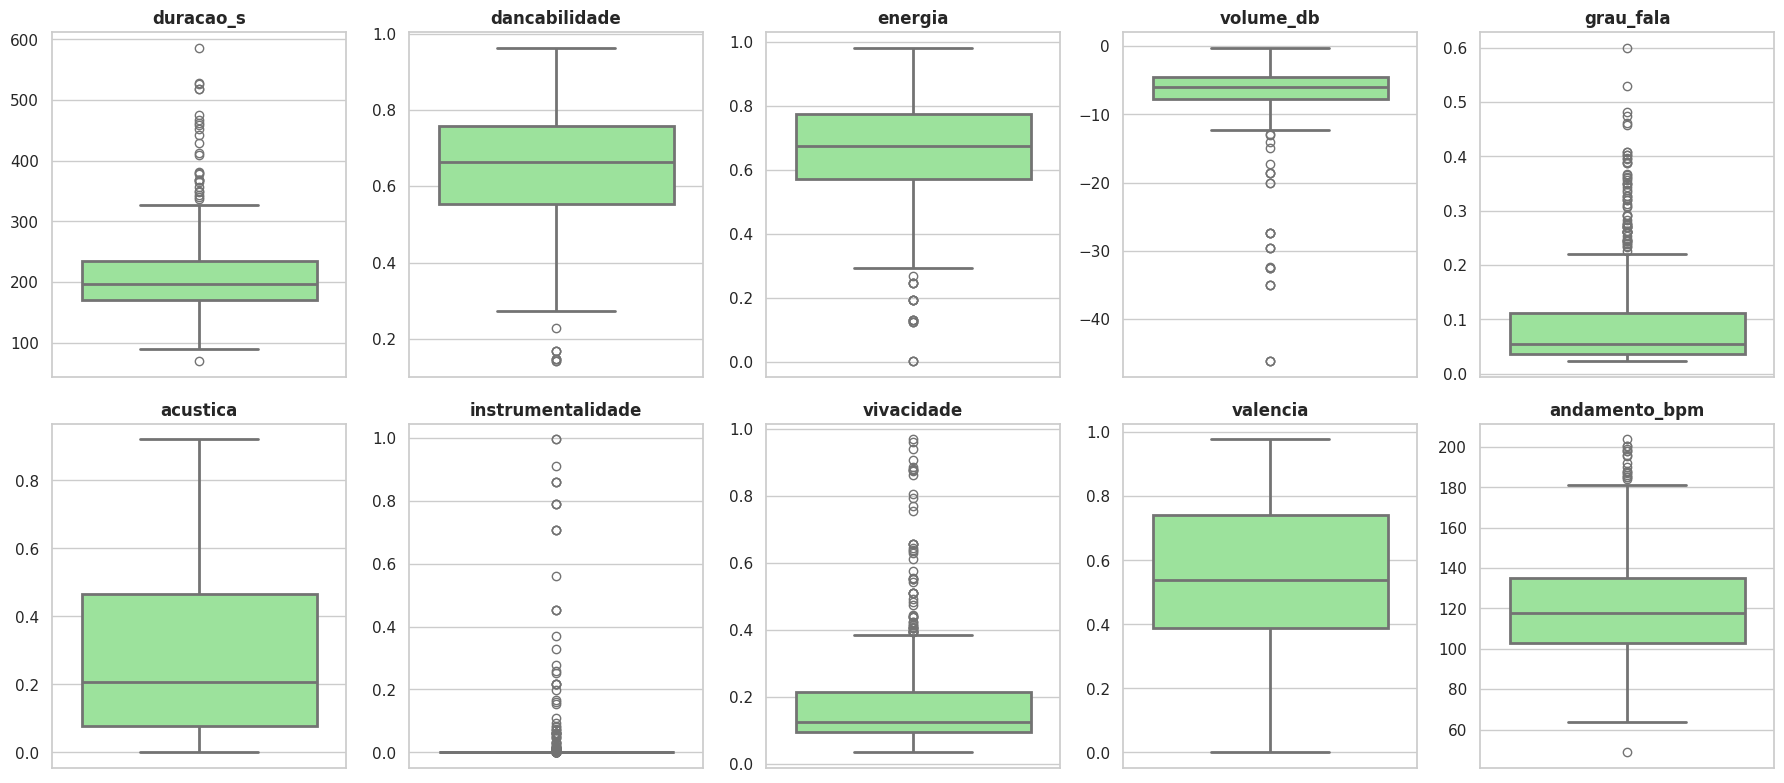

In [ ]:
plot_boxplots(df_paises_last, colunas_numericas, ncols=5, color="lightgreen")

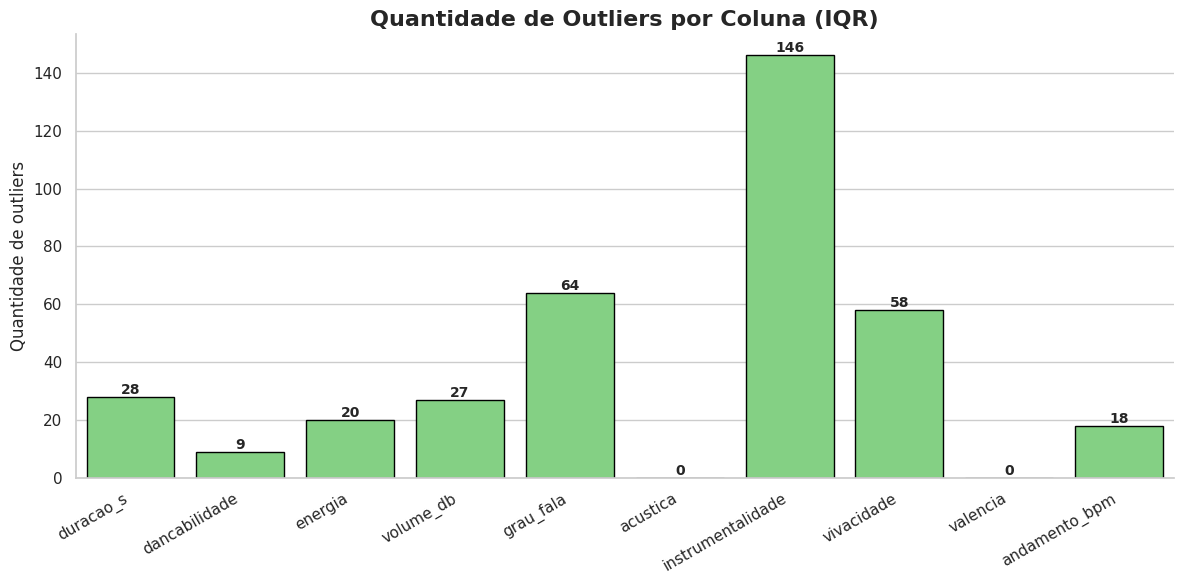

In [ ]:
plot_outliers_iqr(df_paises_last, colunas_numericas)

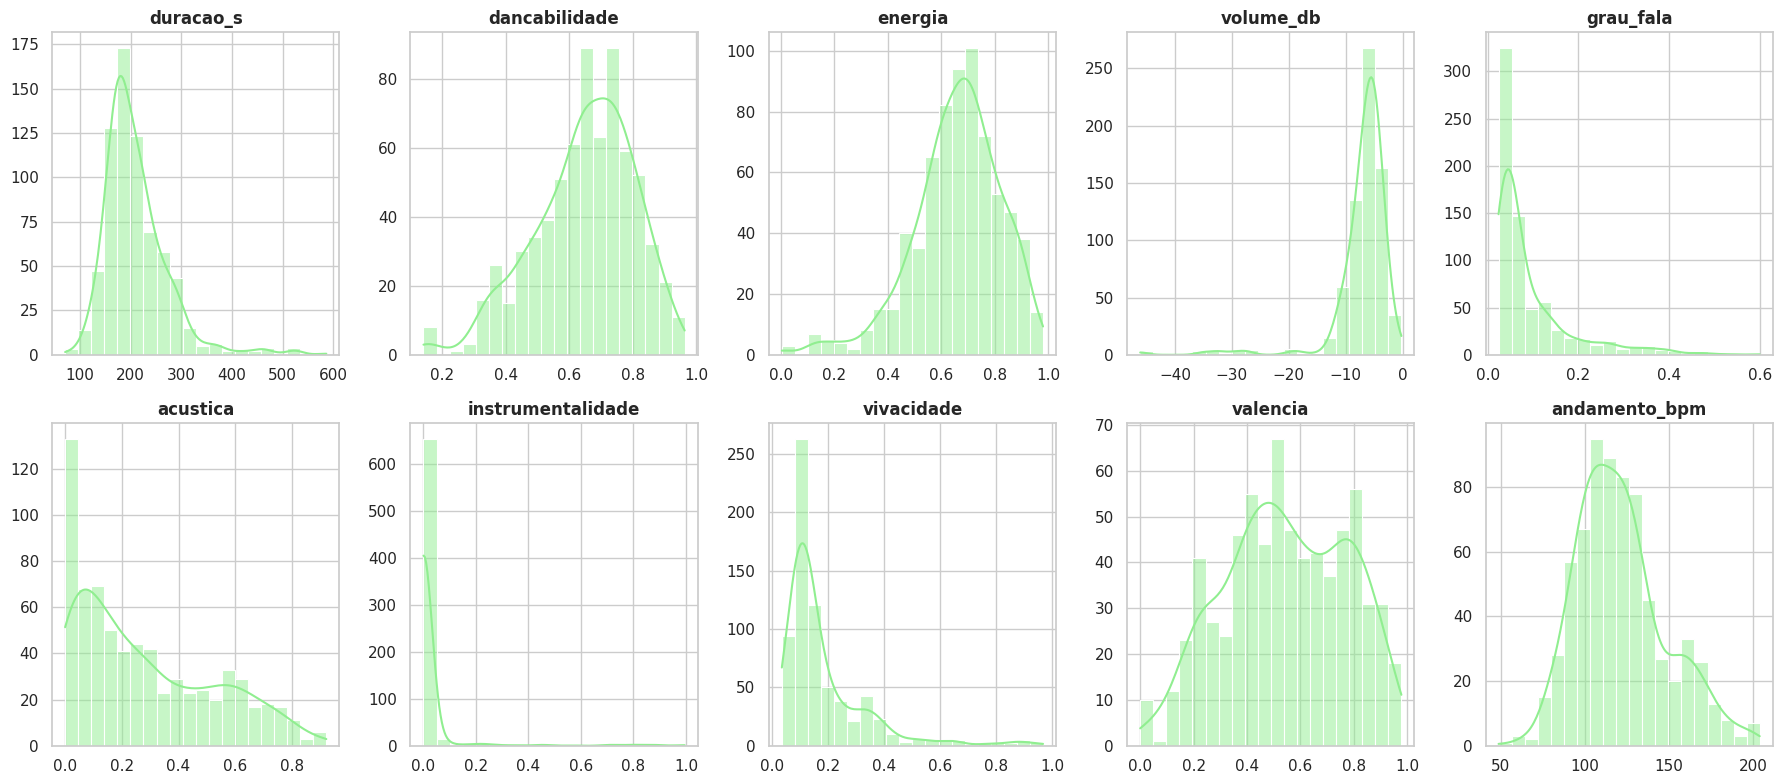

In [ ]:
plot_histograms(df_paises_last, colunas_numericas, ncols=5, bins=20, color="lightgreen", kde=True)

### Avaliação de Normalidade

#### Países

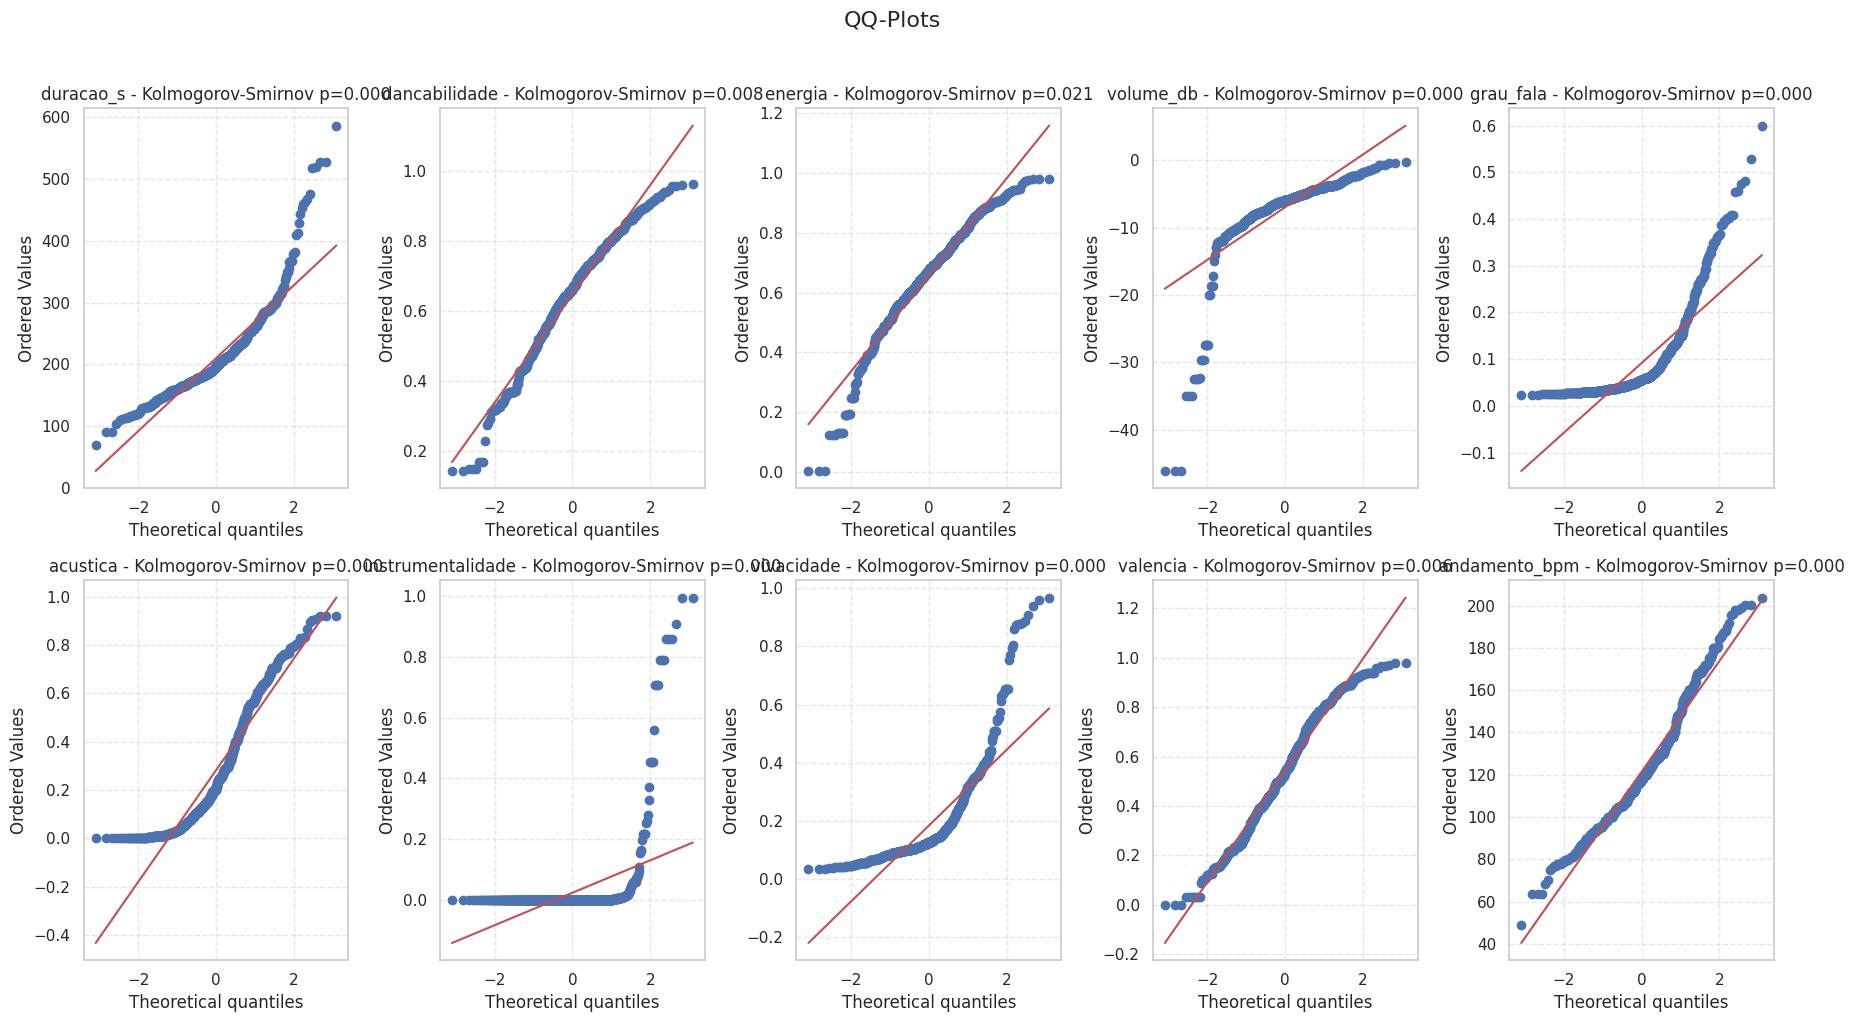

,Variável,Média,Desvio,Limite Inferior,Limite Superior,Teste,p-valor,Normal?
0,duracao_s,210.022341,63.256710,83.508921,336.535761,Kolmogorov-Smirnov,7.895089e-09,Não
1,dancabilidade,0.648514,0.156964,0.334586,0.962443,Kolmogorov-Smirnov,8.484981e-03,Não
2,energia,0.659341,0.164126,0.331089,0.987594,Kolmogorov-Smirnov,2.105267e-02,Não
3,volume_db,-6.952097,5.059287,-17.070671,3.166477,Kolmogorov-Smirnov,1.156699e-25,Não
4,grau_fala,0.091714,0.088876,-0.086037,0.269466,Kolmogorov-Smirnov,2.284820e-32,Não
5,acustica,0.281801,0.241416,-0.201031,0.764632,Kolmogorov-Smirnov,1.636532e-10,Não
6,instrumentalidade,0.023926,0.118234,-0.212541,0.260394,Kolmogorov-Smirnov,2.449217e-132,Não
7,vivacidade,0.183706,0.153275,-0.122844,0.490255,Kolmogorov-Smirnov,1.224838e-29,Não
8,valencia,0.544616,0.227443,0.089731,0.999501,Kolmogorov-Smirnov,6.322519e-03,Não
9,andamento_bpm,121.446596,26.542720,68.361156,174.532036,Kolmogorov-Smirnov,3.881120e-05,Não


In [ ]:
avaliacao_normalidade(df_paises_last, colunas_numericas)

## Relacionados ao df_first

### Métricas e Gráficos

#### Países

In [ ]:
resumo_estatistico(df_paises_first)

,Mínimo,1º Quartil,Mediana,3º Quartil,Máximo,Média,Moda,Variância,Desvio Padrão,Coef. de Variação
duracao_s,81.077000,167.22700,195.919500,231.489500,641.941,207.438804,131.8720,4104.787463,64.068615,0.308855
dancabilidade,0.271000,0.58300,0.702000,0.795250,0.974,0.685919,0.8010,0.018929,0.137582,0.200581
energia,0.091100,0.55275,0.674000,0.760250,0.987,0.657564,0.7330,0.025424,0.159451,0.242487
volume_db,-20.137000,-7.84250,-5.903500,-4.717000,1.155,-6.420183,-8.3070,7.359924,2.712918,-0.422561
grau_fala,0.025000,0.04340,0.066950,0.157000,0.706,0.113734,0.0319,0.010777,0.103811,0.912747
acustica,0.000028,0.07390,0.207000,0.447250,0.970,0.277724,0.2560,0.059031,0.242964,0.874840
instrumentalidade,0.000000,0.00000,0.000001,0.000089,0.836,0.014212,0.0000,0.006332,0.079574,5.599199
vivacidade,0.023100,0.10200,0.130500,0.227000,0.958,0.187033,0.1120,0.020496,0.143165,0.765453
valencia,0.066700,0.37100,0.531000,0.722000,0.971,0.535733,0.1420,0.051370,0.226649,0.423063
andamento_bpm,62.830000,100.02000,119.995000,141.095000,203.759,122.773316,99.9740,764.459148,27.648854,0.225202


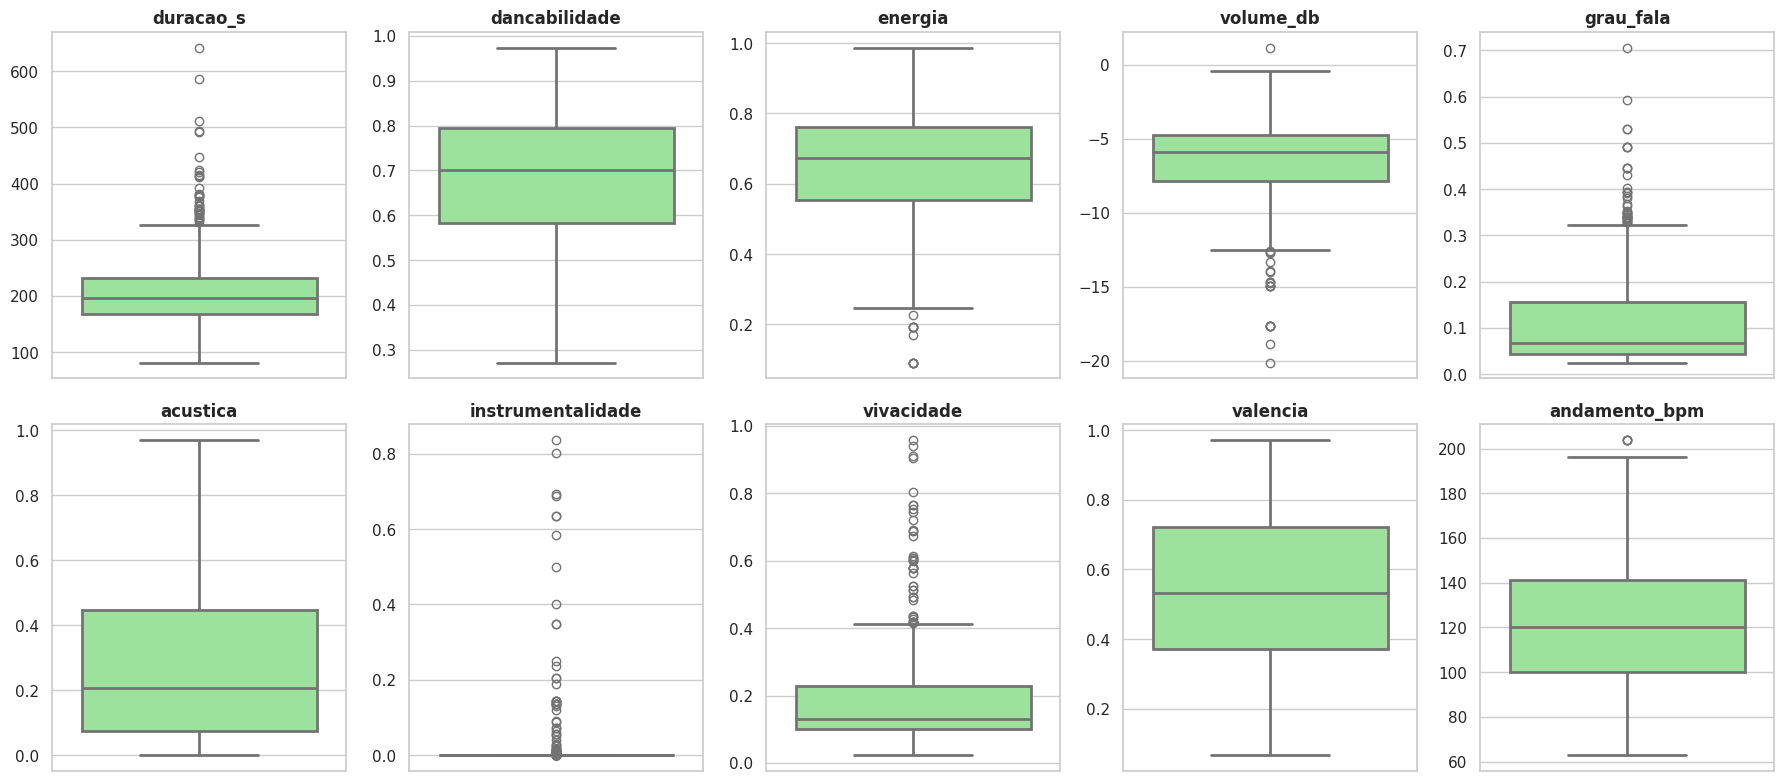

In [ ]:
plot_boxplots(df_paises_first, colunas_numericas, ncols=5, color="lightgreen")

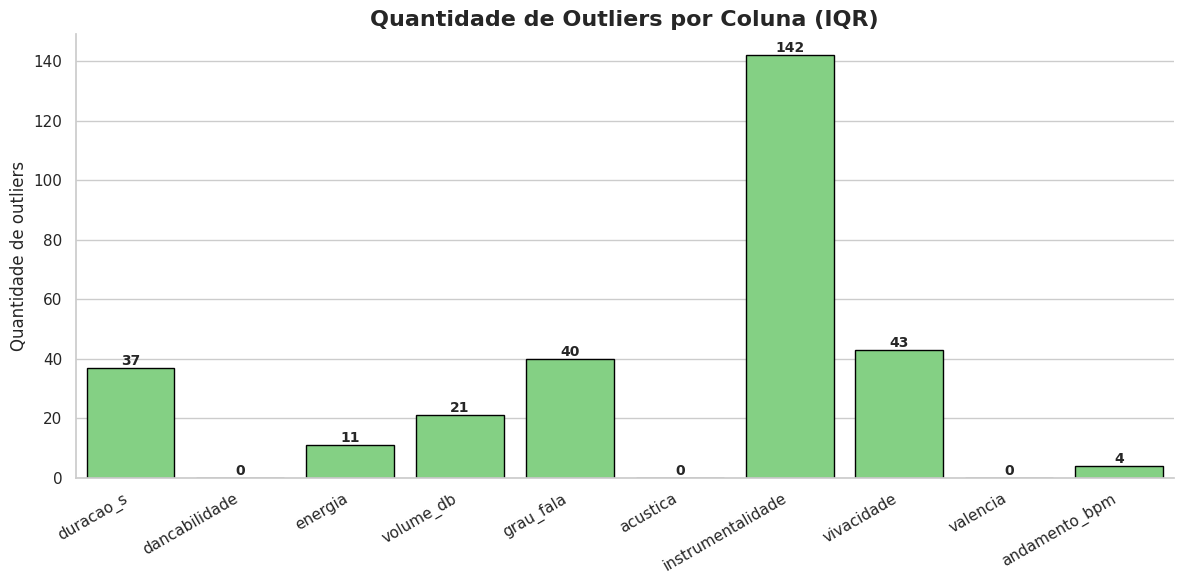

In [ ]:
plot_outliers_iqr(df_paises_first, colunas_numericas)

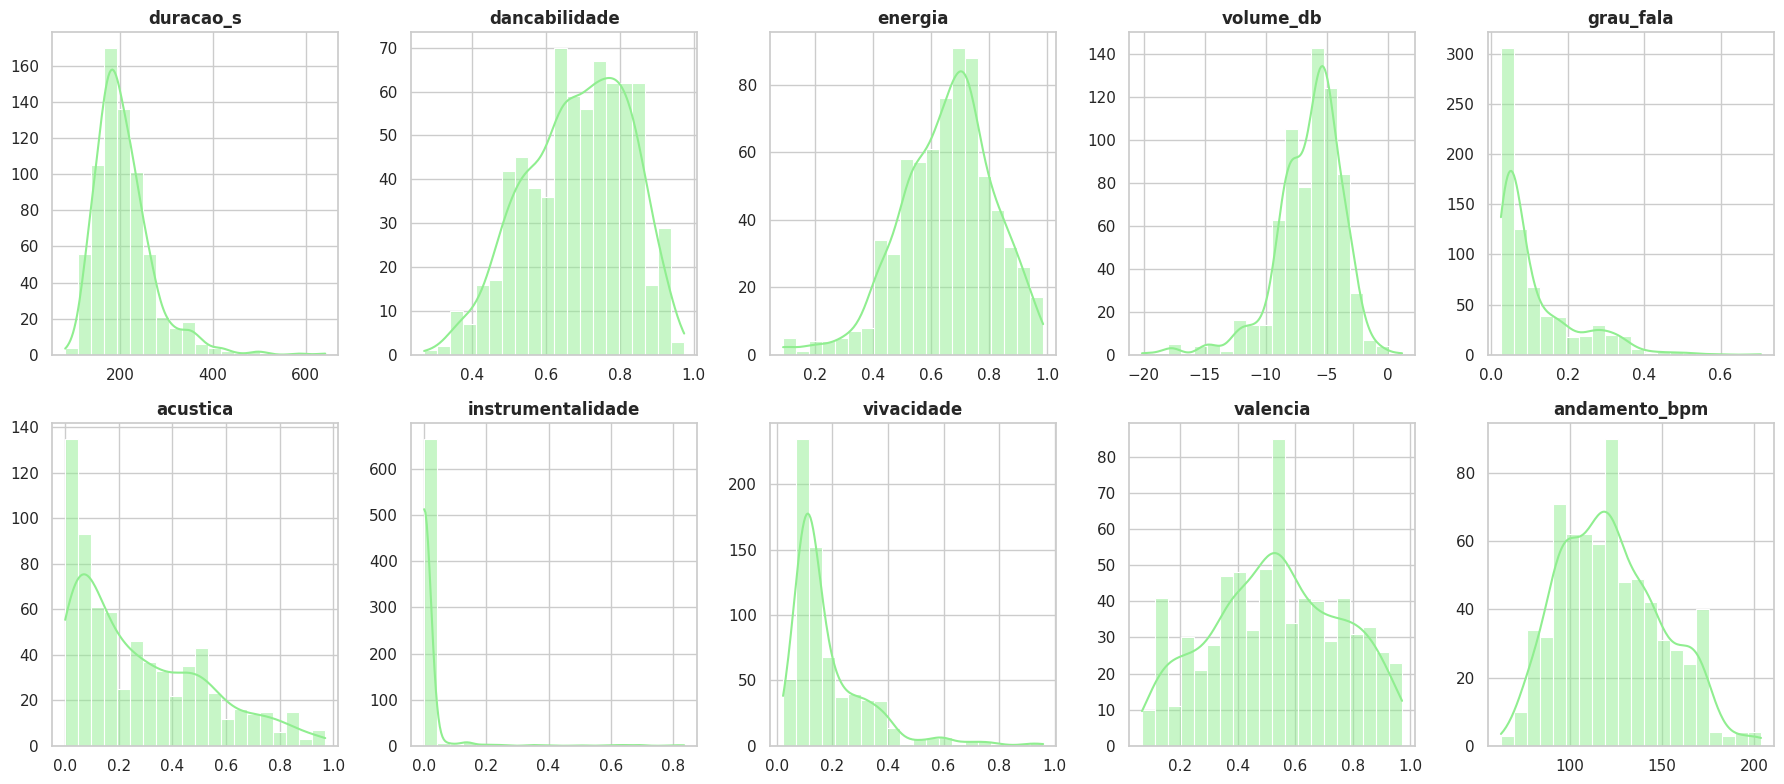

In [ ]:
plot_histograms(df_paises_first, colunas_numericas, ncols=5, bins=20, color="lightgreen", kde=True)

### Avaliação de Normalidade

#### Países

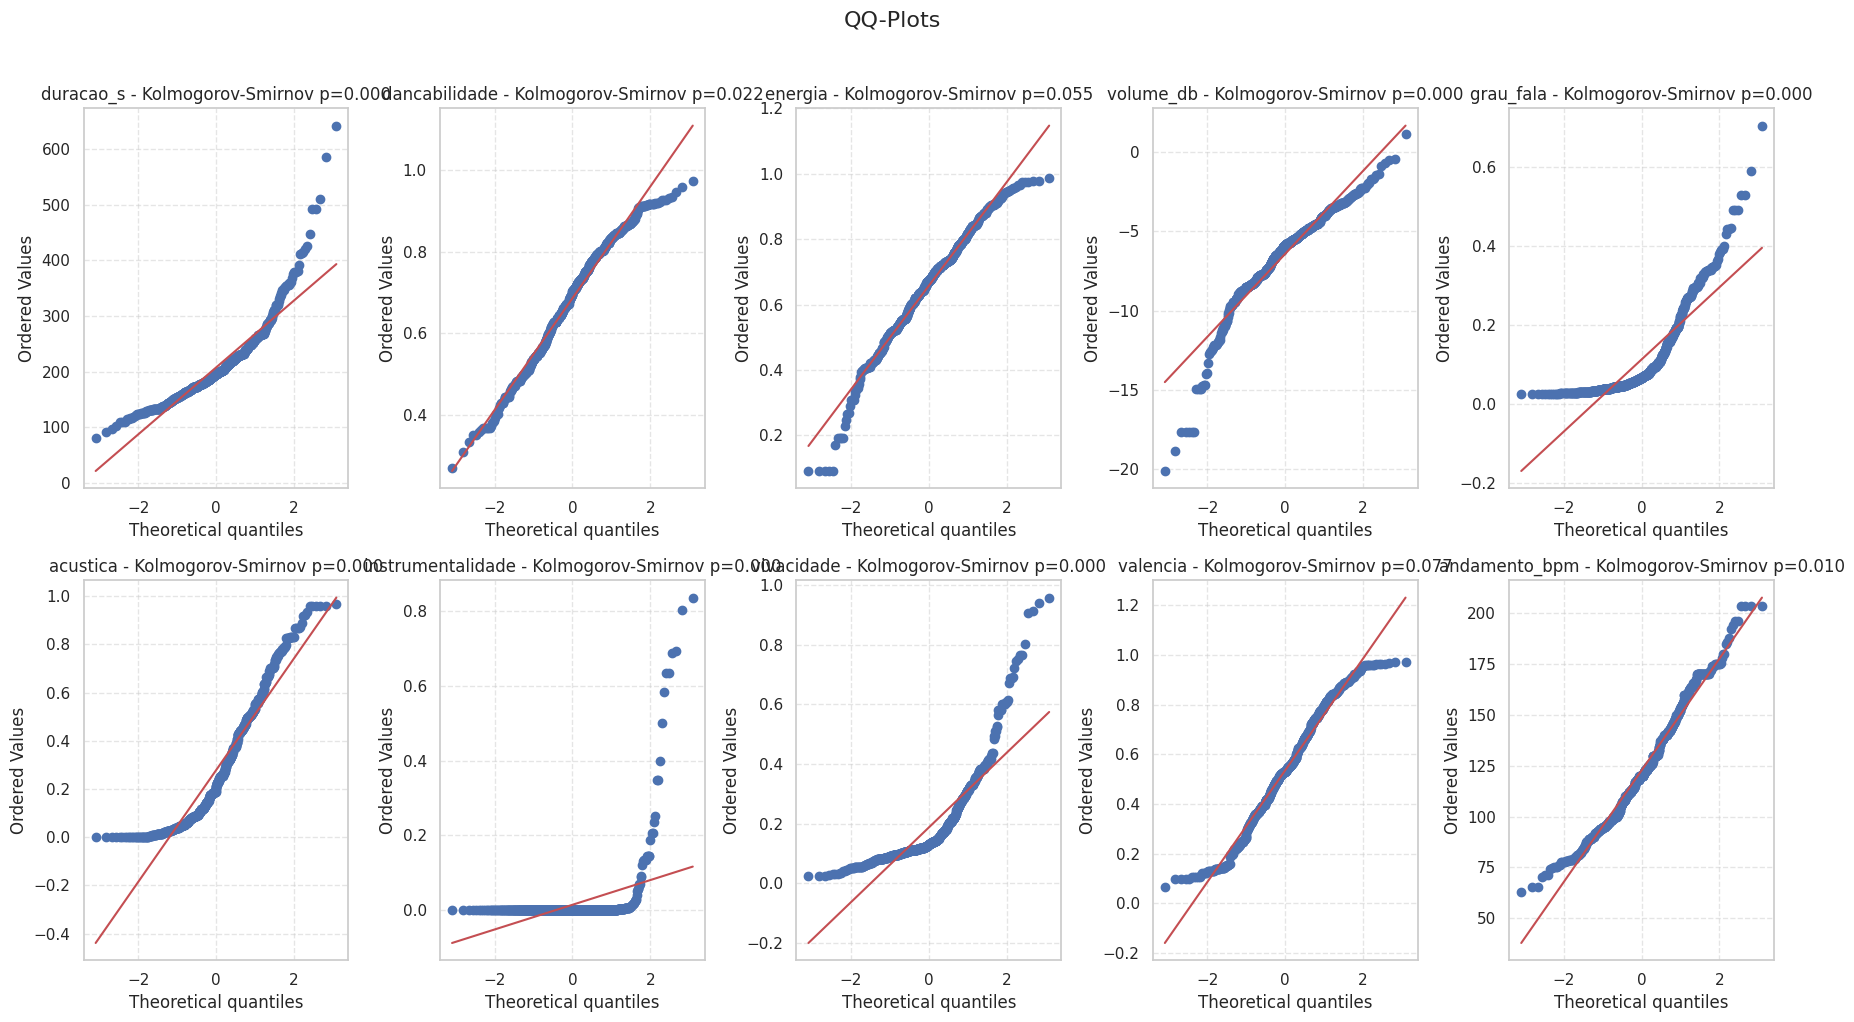

,Variável,Média,Desvio,Limite Inferior,Limite Superior,Teste,p-valor,Normal?
0,duracao_s,207.438804,64.068615,79.301574,335.576035,Kolmogorov-Smirnov,4.560281e-08,Não
1,dancabilidade,0.685919,0.137582,0.410754,0.961083,Kolmogorov-Smirnov,2.163265e-02,Não
2,energia,0.657564,0.159451,0.338662,0.976465,Kolmogorov-Smirnov,5.532149e-02,Sim
3,volume_db,-6.420183,2.712918,-11.846019,-0.994347,Kolmogorov-Smirnov,7.456265e-05,Não
4,grau_fala,0.113734,0.103811,-0.093887,0.321356,Kolmogorov-Smirnov,5.340845e-28,Não
5,acustica,0.277724,0.242964,-0.208204,0.763651,Kolmogorov-Smirnov,3.964900e-12,Não
6,instrumentalidade,0.014212,0.079574,-0.144937,0.173360,Kolmogorov-Smirnov,2.923823e-140,Não
7,vivacidade,0.187033,0.143165,-0.099297,0.473362,Kolmogorov-Smirnov,1.434083e-25,Não
8,valencia,0.535733,0.226649,0.082435,0.989030,Kolmogorov-Smirnov,7.720203e-02,Sim
9,andamento_bpm,122.773316,27.648854,67.475607,178.071024,Kolmogorov-Smirnov,9.755060e-03,Não


In [ ]:
# Avaliar normalidade
avaliacao_normalidade(df_paises_first, colunas_numericas)

# Análise de Variáveis Qualitativas

Função relacionada ao plot dos artistas mais escutados.

In [ ]:

def plot_top_artistas(df, coluna="artistas", top_n=10):
    """
    Plota os Top N artistas mais frequentes em um DataFrame.

    Parâmetros:
    -----------
    df : pandas.DataFrame
        DataFrame contendo os dados.
    coluna : str, default="artistas"
        Nome da coluna onde estão os artistas.
    top_n : int, default=10
        Número de artistas a mostrar.
    """

    top_artistas = df[coluna].value_counts().head(top_n)

    plt.figure(figsize=(8, 5))
    top_artistas.sort_values().plot(
        kind='barh',
        color='#81C784',  # verde claro
    )

    plt.title(f"Top {top_n} Artistas Mais Frequentes", fontsize=14, weight='bold')
    plt.xlabel("Número de músicas", fontsize=12)
    plt.ylabel("Artista", fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.5, color='gray')

    plt.xticks(color='#2E7D32')
    plt.yticks(color='#2E7D32')
    plt.tight_layout()
    plt.show()

Função relacionado ao plot dos gráfico de antigas vs novas.

In [ ]:
def plot_distribuicao_albuns(df, coluna_data="data_lancamento_album", ano_limiar=2015):
    """
    Plota a distribuição de álbuns lançados antes e depois de um ano limiar.

    Parâmetros:
    -----------
    df : pandas.DataFrame
        DataFrame contendo os dados.
    coluna_data : str, default="data_lancamento_album"
        Nome da coluna com a data de lançamento dos álbuns.
    ano_limiar : int, default=2015
        Ano que define a separação entre 'Antes' e 'Depois'.
    """

    # Garante cópia para evitar warnings
    df = df.copy()

    # Converte para datetime
    df[coluna_data] = pd.to_datetime(df[coluna_data], errors='coerce')

    # Cria categorias
    df['categoria_tempo'] = df[coluna_data].dt.year.apply(
        lambda x: f"Antes de {ano_limiar}" if pd.notnull(x) and x < ano_limiar else f"Depois de {ano_limiar}"
    )

    # Contagem
    contagem_tempo = df['categoria_tempo'].value_counts()

    # Gráfico
    plt.figure(figsize=(5, 5))
    contagem_tempo.plot(
        kind='pie',
        autopct='%1.1f%%',
        startangle=90,
        colors=['#C8E6C9', '#81C784'],  # dois tons de verde claro
        wedgeprops={'edgecolor': 'black'}
    )

    plt.title(
        f"Distribuição de Álbuns (antes/depois de {ano_limiar})",
        fontsize=14, weight='bold', color='#388E3C'
    )
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

## Relacionados ao df_last

### Artistas mais famosos

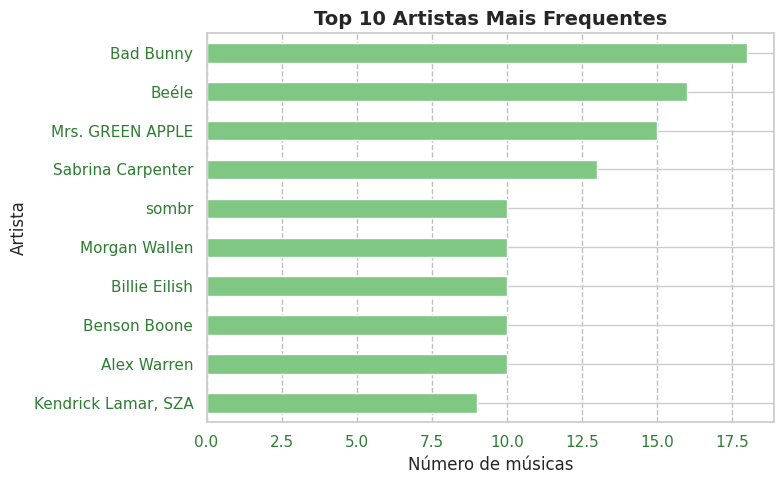

In [ ]:
plot_top_artistas(df_paises_last)

### Músicas Antigas vc Novas

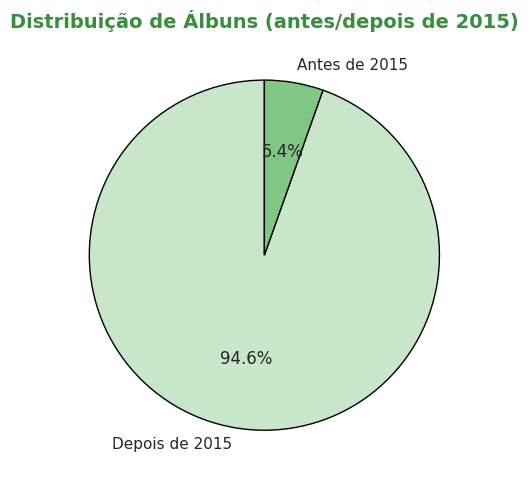

In [ ]:
plot_distribuicao_albuns(df_paises_last, ano_limiar=2015)

## Relacionados ao df_first

### Artistas Mais Famosos

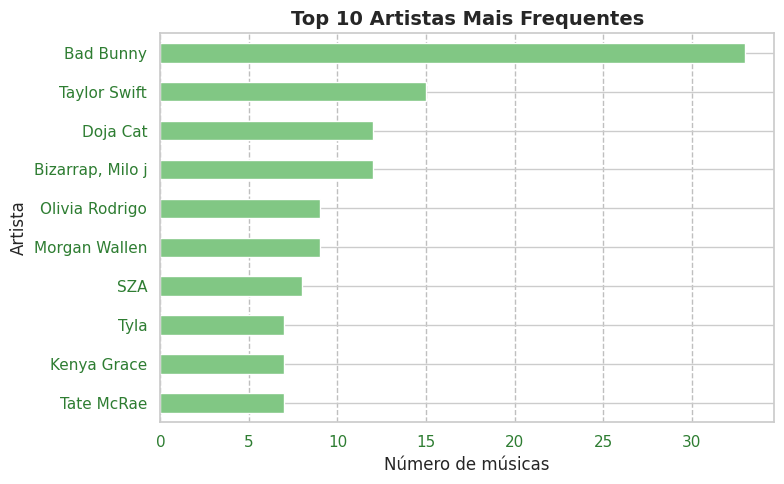

In [ ]:
plot_top_artistas(df_paises_first)

### Músicas Antigas vs Novas

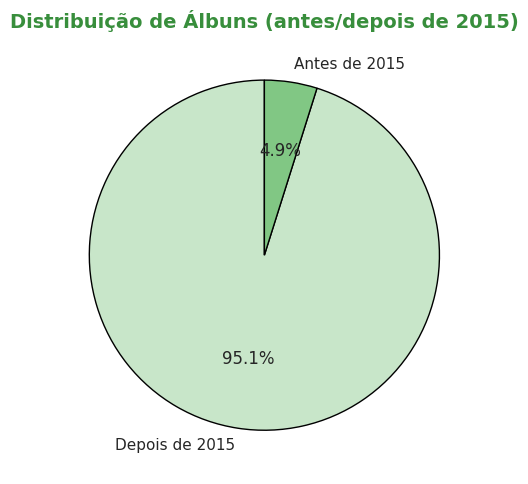

In [ ]:
plot_distribuicao_albuns(df_paises_first, ano_limiar=2015)

# Regressão Linear Múltipla

### Análise de correlações

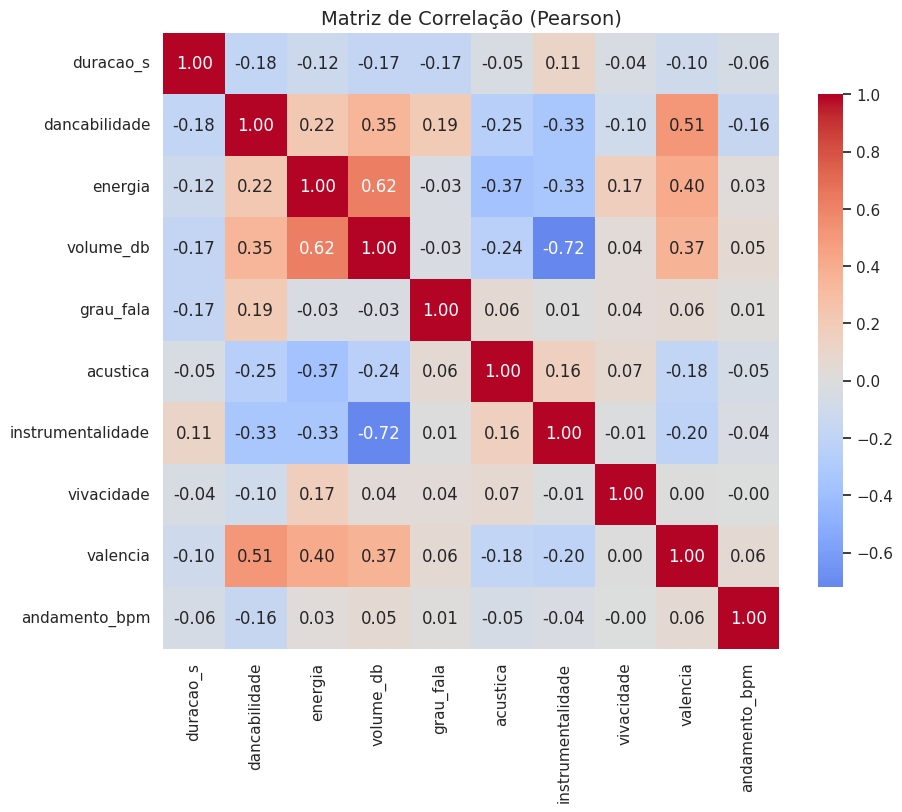

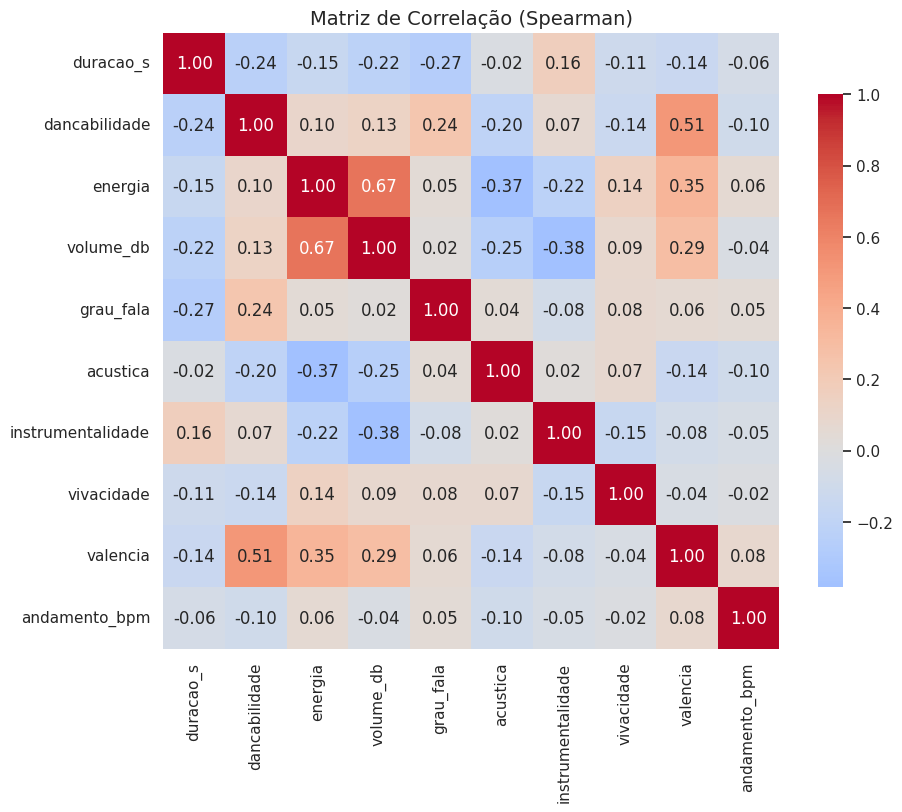

In [ ]:
df_num = df_paises_last[colunas_numericas].dropna()

# Função para plotar matriz de correlação
def plot_corr(df, metodo="pearson"):
    corr = df.corr(method=metodo)

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                square=True, cbar_kws={"shrink": .8})
    plt.title(f"Matriz de Correlação ({metodo.capitalize()})", fontsize=14)
    plt.show()

# Correlação de Pearson (linear)
plot_corr(df_num, metodo="pearson")

# Correlação de Spearman (monotônica, não-linear)
plot_corr(df_num, metodo="spearman")

## Candidato valência

#### Teste VIF

In [ ]:
# Defina as variáveis independentes candidatas
independentes = ["dancabilidade", "energia", "volume_db", "instrumentalidade"]

# Monta a matriz X com constante (intercepto)
X = df_paises_last[independentes]
X = sm.add_constant(X)

# Calcula o VIF para cada variável
vif_data = pd.DataFrame()
vif_data["Variável"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

vif_data

,Variável,VIF
0,const,68.884188
1,dancabilidade,1.156788
2,energia,1.719000
3,volume_db,3.210980
4,instrumentalidade,2.219801


Aqui tem um problema já que i VIF estourou muito. Tomaremos outras estrátégias nesse caso.

#### Regressão, comparação e escolha inicial dos modelos

##### Países

Mesmo com os VIF ok, ainda não tem resultados satisfatórios, então utilizaremos as mesmas estratégias do global:

Estratégia 1, tirar volume_db:

In [ ]:
# Definir variáveis independentes e dependente
X = df_paises_last[['dancabilidade', 'energia', 'instrumentalidade']]
y = df_paises_last['valencia']

# Adicionar constante (intercepto)
X = sm.add_constant(X)

# Ajustar modelo OLS
modelo = sm.OLS(y, X).fit()

# Mostrar resumo
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               valencia   R-squared:                       0.353
Model:                            OLS   Adj. R-squared:                  0.350
Method:                 Least Squares   F-statistic:                     126.4
Date:                Tue, 09 Dec 2025   Prob (F-statistic):           2.35e-65
Time:                        02:36:48   Log-Likelihood:                 196.06
No. Observations:                 700   AIC:                            -384.1
Df Residuals:                     696   BIC:                            -365.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.1803      0.041     -4.378      0.000      -0.261      -0.099
dancabilidade         0.6666      0.047     14.108      0.000       0.574       0.759
energia               0.4399      0.045      9.742      0.000       0.351       0.529
instrumentalidade     0.1047      0.065      1.616      0.106      -0.022       0.232
==============================================================================
Omnibus:                        7.328   Durbin-Watson:                   1.828
Prob(Omnibus):                  0.026   Jarque-Bera (JB):                7.461
Skew:                          -0.251   Prob(JB):                       0.0240
Kurtosis:                       2.935   Cond. No.                         14.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Estratégia 2, tirar energia:

In [ ]:
# Definir variáveis independentes e dependente
X = df_paises_last[['dancabilidade', 'volume_db', 'instrumentalidade']]
y = df_paises_last['valencia']

# Adicionar constante (intercepto)
X = sm.add_constant(X)

# Ajustar modelo OLS
modelo = sm.OLS(y, X).fit()

# Mostrar resumo
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               valencia   R-squared:                       0.324
Model:                            OLS   Adj. R-squared:                  0.321
Method:                 Least Squares   F-statistic:                     111.3
Date:                Tue, 09 Dec 2025   Prob (F-statistic):           6.85e-59
Time:                        02:36:48   Log-Likelihood:                 181.04
No. Observations:                 700   AIC:                            -354.1
Df Residuals:                     696   BIC:                            -335.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.2164      0.037      5.850      0.000       0.144       0.289
dancabilidade         0.6638      0.049     13.681      0.000       0.569       0.759
volume_db             0.0161      0.002      7.855      0.000       0.012       0.020
instrumentalidade     0.3964      0.087      4.551      0.000       0.225       0.567
==============================================================================
Omnibus:                       13.693   Durbin-Watson:                   1.821
Prob(Omnibus):                  0.001   Jarque-Bera (JB):                8.280
Skew:                          -0.085   Prob(JB):                       0.0159
Kurtosis:                       2.495   Cond. No.                         107.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# Definir variáveis independentes e dependente
X = df_paises_last[['dancabilidade', 'energia', 'volume_db', 'instrumentalidade']]
y = df_paises_last['valencia']

# Adicionar constante (intercepto)
X = sm.add_constant(X)

# Ajustar modelo OLS
modelo_ofc_reg_paises = sm.OLS(y, X).fit()

# Mostrar resumo
modelo_ofc_reg_paises.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               valencia   R-squared:                       0.361
Model:                            OLS   Adj. R-squared:                  0.357
Method:                 Least Squares   F-statistic:                     97.99
Date:                Tue, 09 Dec 2025   Prob (F-statistic):           4.06e-66
Time:                        02:36:48   Log-Likelihood:                 200.37
No. Observations:                 700   AIC:                            -390.7
Df Residuals:                     695   BIC:                            -368.0
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.0630      0.057     -1.100      0.272      -0.175       0.049
dancabilidade         0.6516      0.047     13.785      0.000       0.559       0.744
energia               0.3462      0.055      6.281      0.000       0.238       0.454
volume_db             0.0072      0.002      2.935      0.003       0.002       0.012
instrumentalidade     0.2760      0.087      3.175      0.002       0.105       0.447
==============================================================================
Omnibus:                        6.325   Durbin-Watson:                   1.820
Prob(Omnibus):                  0.042   Jarque-Bera (JB):                5.692
Skew:                          -0.162   Prob(JB):                       0.0581
Kurtosis:                       2.699   Cond. No.                         115.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Nesse caso o modelo mais expressivo foi o com as 4 váriaveis independetes.

=== VIF (Variance Inflation Factor) ===
            variavel       VIF
0      dancabilidade  1.156788
1            energia  1.719000
2          volume_db  3.210980
3  instrumentalidade  2.219801 

=== Breusch-Pagan Test ===
{'LM Statistic': np.float64(23.075774060387154), 'LM-Test p-value': np.float64(0.00012228795498430697), 'F-Statistic': np.float64(5.922990475672436), 'F-Test p-value': np.float64(0.0001087579850765401)} 

=== Shapiro-Wilk Test ===
Estatística = 0.9947, p-valor = 0.0149



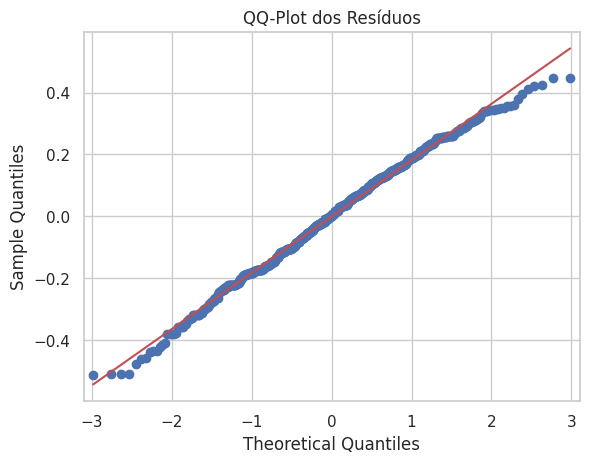

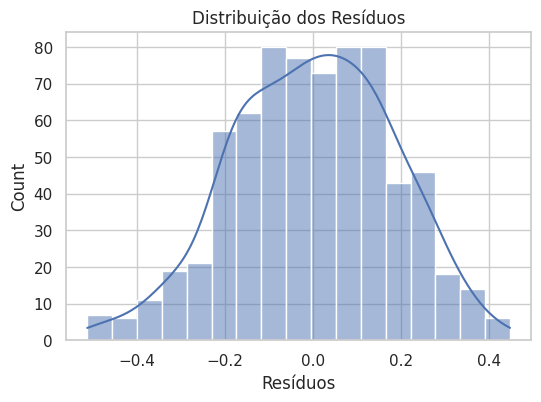

=== Durbin-Watson ===
Estatística DW = 1.820



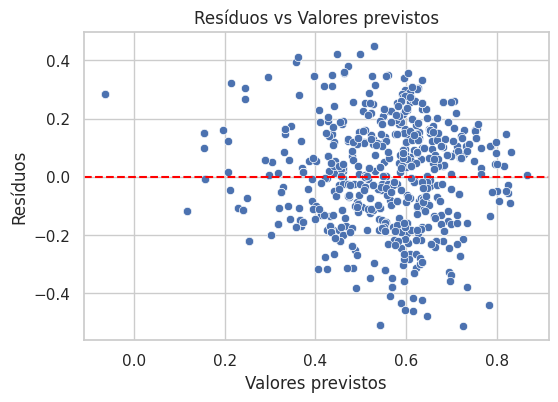

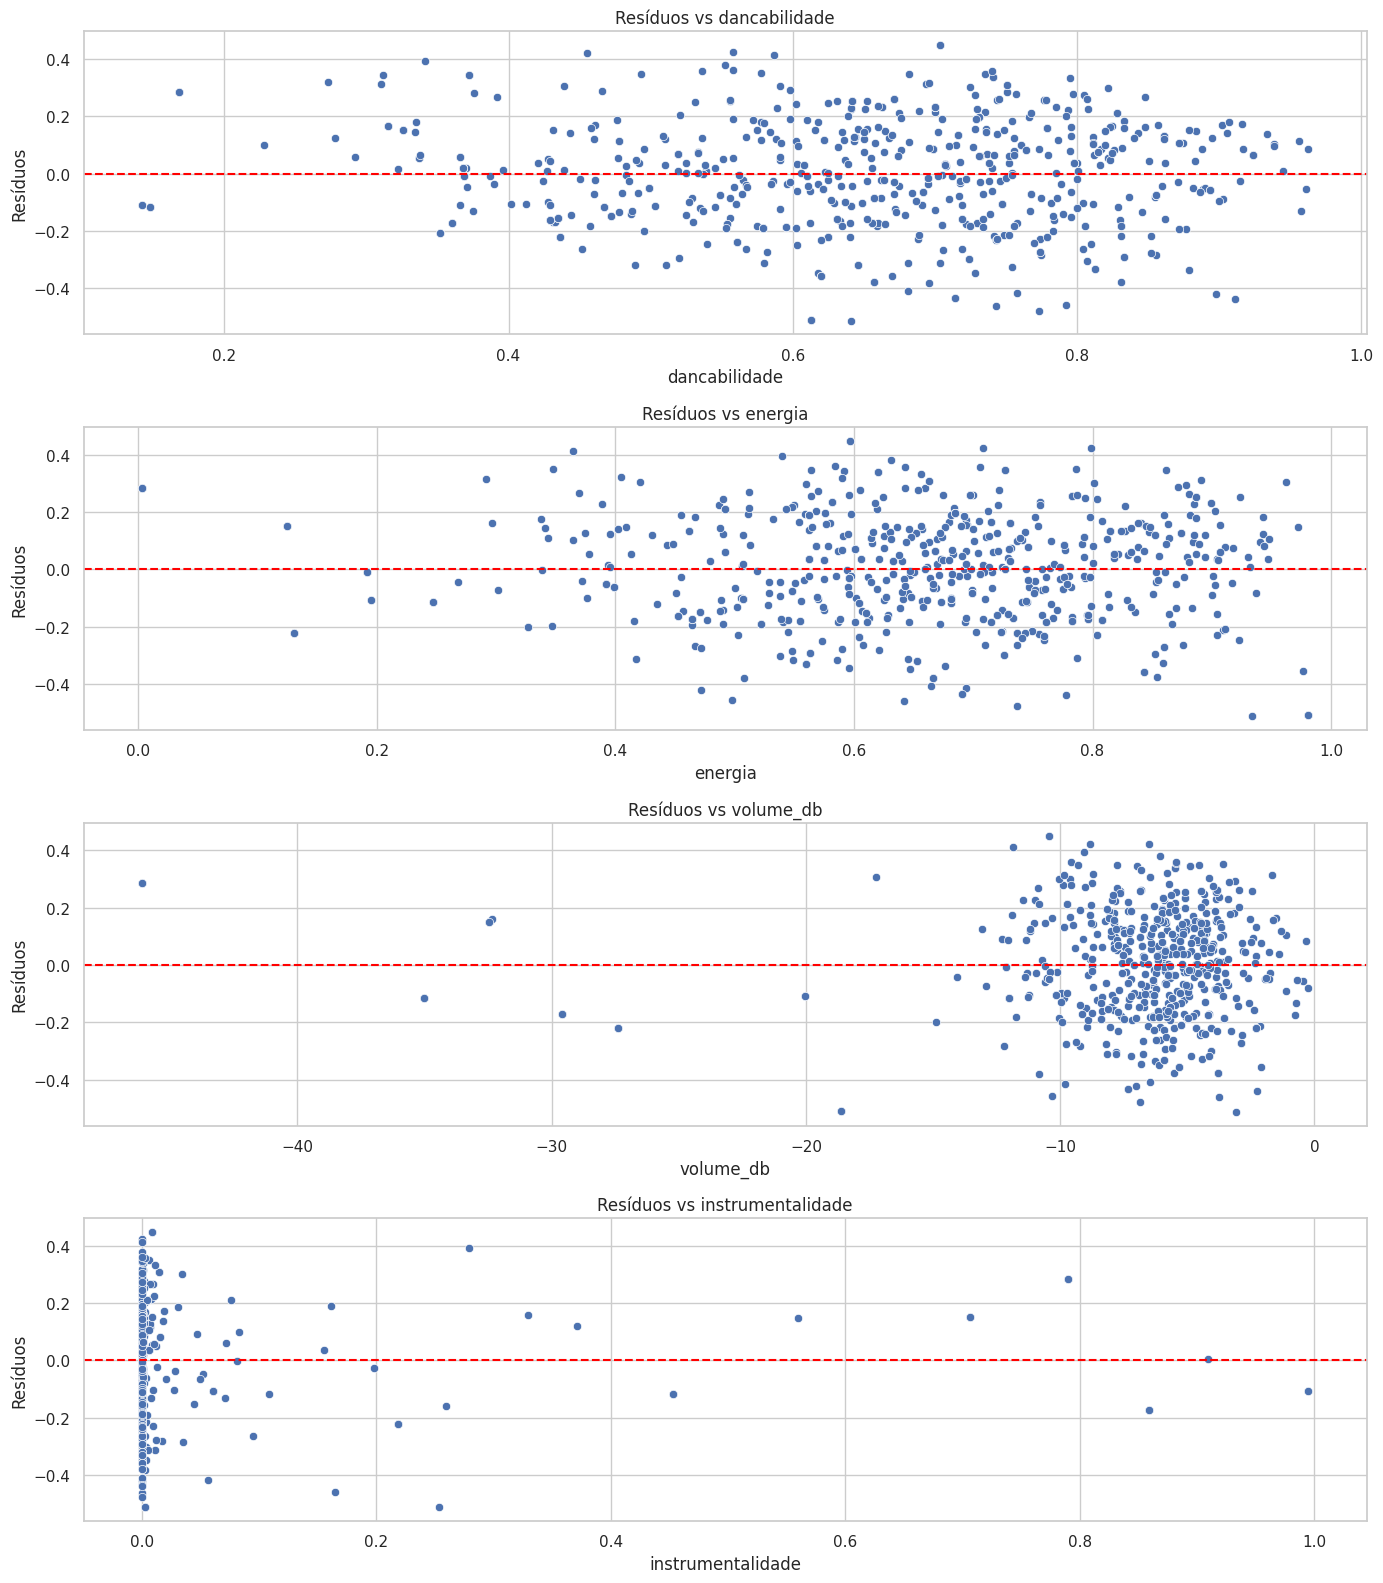

In [ ]:
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# =============================
# 1. MULTICOLINEARIDADE (VIF)
# =============================
vif_data = pd.DataFrame()
vif_data["variavel"] = X.drop(columns="const").columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i+1)
                   for i in range(len(X.drop(columns="const").columns))]

print("=== VIF (Variance Inflation Factor) ===")
print(vif_data, "\n")

# =============================
# 2. HETEROCEDASTICIDADE (Breusch-Pagan)
# =============================
residuos = modelo_ofc_reg_paises.resid
test_bp = sms.het_breuschpagan(residuos, modelo_ofc_reg_paises.model.exog)
labels = ["LM Statistic", "LM-Test p-value", "F-Statistic", "F-Test p-value"]

print("=== Breusch-Pagan Test ===")
print(dict(zip(labels, test_bp)), "\n")

# =============================
# 3. NORMALIDADE DOS RESÍDUOS
# =============================
# Shapiro-Wilk
shapiro_test = stats.shapiro(residuos)
print("=== Shapiro-Wilk Test ===")
print(f"Estatística = {shapiro_test.statistic:.4f}, p-valor = {shapiro_test.pvalue:.4f}\n")

# QQ-Plot
sm.qqplot(residuos, line='s')
plt.title("QQ-Plot dos Resíduos")
plt.show()

# Histograma dos resíduos
plt.figure(figsize=(6,4))
sns.histplot(residuos, kde=True)
plt.title("Distribuição dos Resíduos")
plt.xlabel("Resíduos")
plt.show()

# =============================
# 4. AUTOCORRELAÇÃO (Durbin-Watson)
# =============================
dw = sm.stats.stattools.durbin_watson(residuos)
print("=== Durbin-Watson ===")
print(f"Estatística DW = {dw:.3f}\n")

# =============================
# 5. GRÁFICOS DE RESÍDUOS
# =============================

# Resíduos vs Valores previstos
y_pred = modelo_ofc_reg_paises.fittedvalues
plt.figure(figsize=(6,4))
sns.scatterplot(x=y_pred, y=residuos)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valores previstos")
plt.ylabel("Resíduos")
plt.title("Resíduos vs Valores previstos")
plt.show()

# Resíduos vs Variáveis independentes
plt.figure(figsize=(14, 4*len(X.drop(columns='const').columns)))
for i, var in enumerate(X.drop(columns='const').columns, 1):
    plt.subplot(len(X.drop(columns='const').columns), 1, i)
    sns.scatterplot(x=X[var], y=residuos)
    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel(var)
    plt.ylabel("Resíduos")
    plt.title(f"Resíduos vs {var}")
plt.tight_layout()
plt.show()


#### Checagem de Linearidade

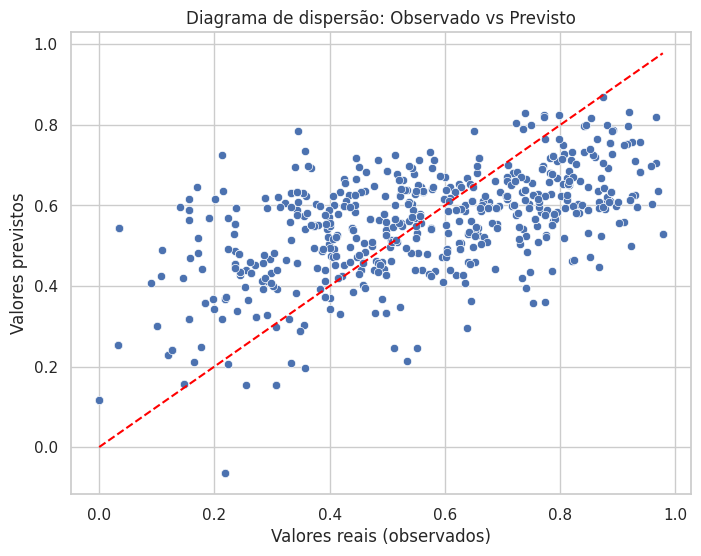

In [ ]:
# Valores observados e previstos
y_real = y
y_pred = modelo_ofc_reg_paises.fittedvalues

# Diagrama de dispersão
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_real, y=y_pred)

# Linha 45° de referência
plt.plot([y_real.min(), y_real.max()],
         [y_real.min(), y_real.max()],
         color="red", linestyle="--")

plt.xlabel("Valores reais (observados)")
plt.ylabel("Valores previstos")
plt.title("Diagrama de dispersão: Observado vs Previsto")
plt.show()

#### Checagem de autocorrelação serial

In [ ]:
# Resíduos do modelo
residuos = modelo_ofc_reg_paises.resid

# Junta resíduos com os preditores originais
df_corr = pd.concat([X.drop(columns="const"), residuos.rename("residuos")], axis=1)

# Correlação de Pearson
corr = df_corr.corr()["residuos"].drop("residuos")
print("Correlação dos resíduos com os preditores:")
print(corr)


Correlação dos resíduos com os preditores:
dancabilidade        3.018885e-15
energia             -3.038307e-15
volume_db           -1.398975e-15
instrumentalidade    1.670881e-16
Name: residuos, dtype: float64


In [ ]:
for var in X.drop(columns="const").columns:
    r, p = pearsonr(X[var], residuos)
    print(f"{var}: correlação = {r:.3f}, p-valor = {p:.3f}")

dancabilidade: correlação = 0.000, p-valor = 1.000
energia: correlação = -0.000, p-valor = 1.000
volume_db: correlação = -0.000, p-valor = 1.000
instrumentalidade: correlação = 0.000, p-valor = 1.000


#### Checagem da homocedasticidade dos resíduos

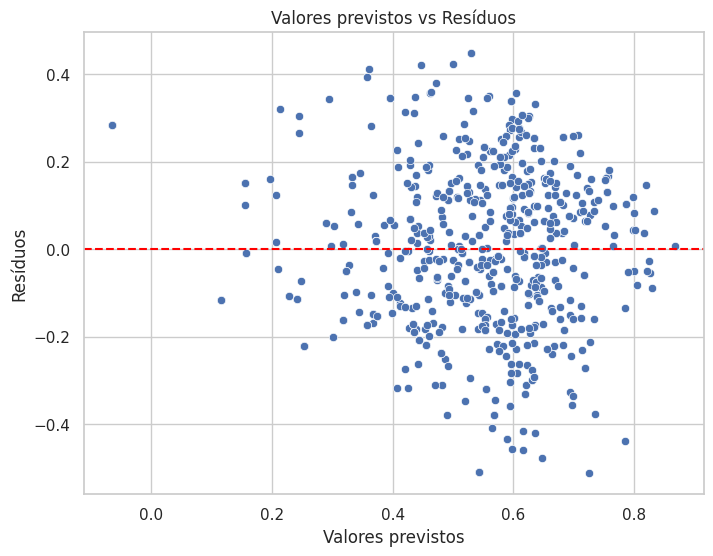

In [ ]:
y_pred = modelo_ofc_reg_paises.fittedvalues
residuos = modelo_ofc_reg_paises.resid

# Criando o gráfico
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_pred, y=residuos)
plt.axhline(0, color='red', linestyle='--')  # linha de referência
plt.xlabel("Valores previstos")
plt.ylabel("Resíduos")
plt.title("Valores previstos vs Resíduos")
plt.show()

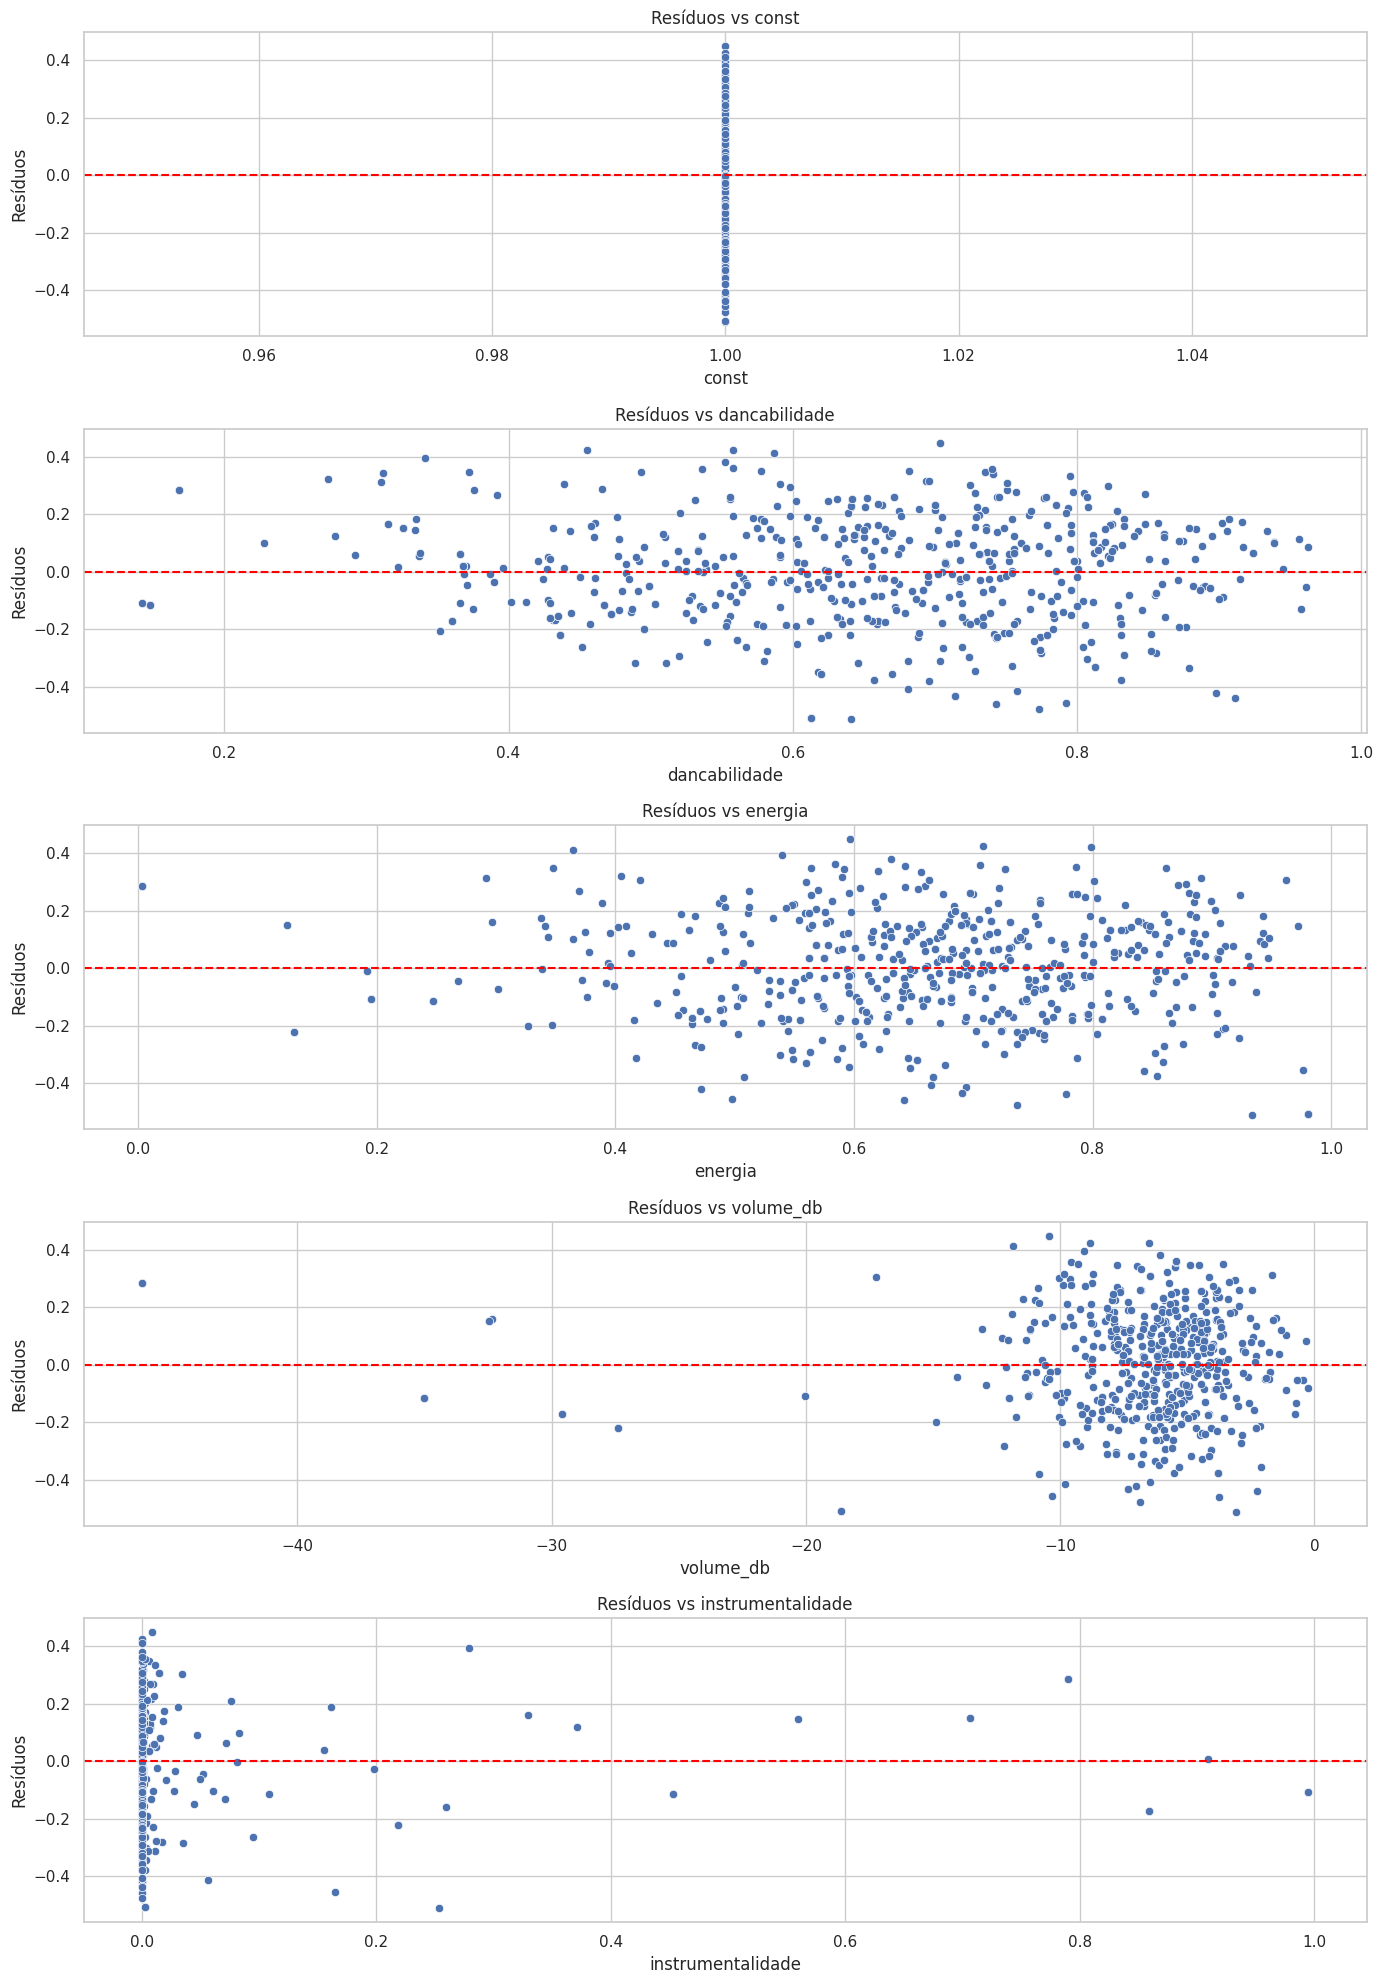

In [ ]:
y_pred = modelo_ofc_reg_paises.fittedvalues
residuos = modelo_ofc_reg_paises.resid

# Lista das variáveis independentes usadas no modelo
variaveis = X.columns

# Configuração do layout
plt.figure(figsize=(14, 4*len(variaveis)))

for i, var in enumerate(variaveis, 1):
    plt.subplot(len(variaveis), 1, i)
    sns.scatterplot(x=X[var], y=residuos)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel(var)
    plt.ylabel("Resíduos")
    plt.title(f"Resíduos vs {var}")

plt.tight_layout()
plt.show()

#### Checagem da normalidade dos resíduos

Shapiro-Wilk: estatística=0.9947, p-valor=0.0149
Jarque-Bera: estatística=5.6922, p-valor=0.0581


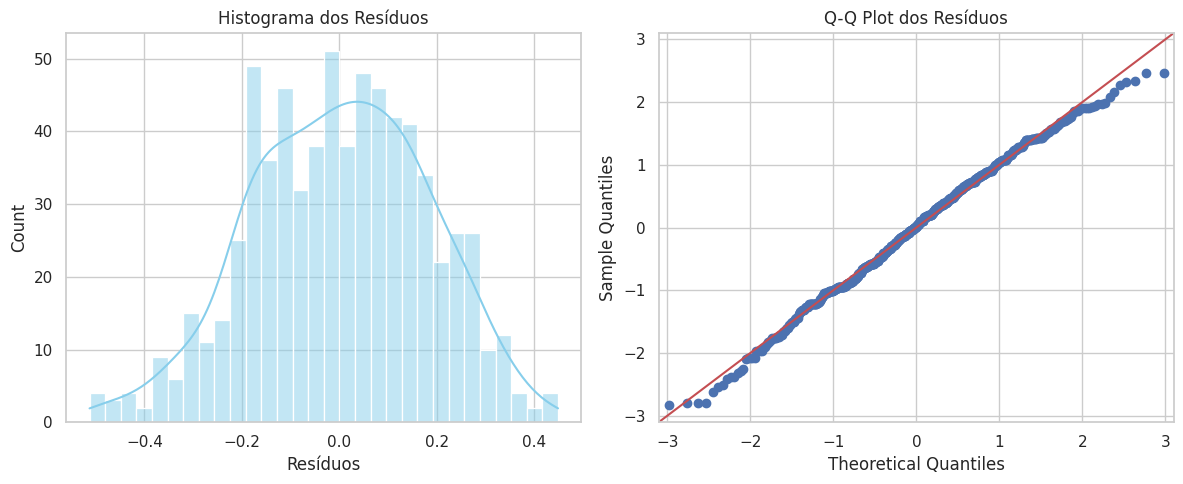

In [ ]:
residuals = modelo_ofc_reg_paises.resid

# Shapiro-Wilk
shapiro_test = stats.shapiro(residuals)
print(f"Shapiro-Wilk: estatística={shapiro_test.statistic:.4f}, p-valor={shapiro_test.pvalue:.4f}")

# Jarque-Bera
jb_test = stats.jarque_bera(residuals)
print(f"Jarque-Bera: estatística={jb_test.statistic:.4f}, p-valor={jb_test.pvalue:.4f}")

# ------------------------
# 5. Plots dos resíduos
# ------------------------
plt.figure(figsize=(12,5))

# Histograma
plt.subplot(1,2,1)
sns.histplot(residuals, kde=True, bins=30, color='skyblue')
plt.title('Histograma dos Resíduos')
plt.xlabel('Resíduos')

# Q-Q plot
plt.subplot(1,2,2)
sm.qqplot(residuals, line='45', fit=True, ax=plt.gca())
plt.title('Q-Q Plot dos Resíduos')

plt.tight_layout()
plt.show()

# MANOVA / ANOVA


📊 Resultado MANOVA:
                   Multivariate linear model
                                                               
---------------------------------------------------------------
       Intercept        Value  Num DF  Den DF   F Value  Pr > F
---------------------------------------------------------------
          Wilks' lambda 0.1001 4.0000 690.0000 1551.5671 0.0000
         Pillai's trace 0.8999 4.0000 690.0000 1551.5671 0.0000
 Hotelling-Lawley trace 8.9946 4.0000 690.0000 1551.5671 0.0000
    Roy's greatest root 8.9946 4.0000 690.0000 1551.5671 0.0000
---------------------------------------------------------------
                                                               
---------------------------------------------------------------
       continente       Value   Num DF   Den DF  F Value Pr > F
---------------------------------------------------------------
          Wilks' lambda 0.8538 24.0000 2408.3325  4.6520 0.0000
         Pillai's trace 0.1526 24.0000

/tmp/ipython-input-2751826761.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if anova_table["PR(>F)"][0] < 0.05:



Post-hoc Tukey:
          Multiple Comparison of Means - Tukey HSD, FWER=0.05           
     group1           group2      meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------
          Africa  America Central  -0.0305 0.7982 -0.0947  0.0337  False
          Africa America do Norte  -0.0489 0.2687 -0.1131  0.0153  False
          Africa   America do Sul  -0.0408 0.4935  -0.105  0.0234  False
          Africa             Asia  -0.0725 0.0153 -0.1367 -0.0083   True
          Africa           Europa   0.0359 0.6469 -0.0283  0.1001  False
          Africa          Oceania  -0.0679 0.0302 -0.1321 -0.0037   True
 America Central America do Norte  -0.0184 0.9799 -0.0826  0.0458  False
 America Central   America do Sul  -0.0103 0.9992 -0.0745  0.0539  False
 America Central             Asia   -0.042 0.4582 -0.1062  0.0222  False
 America Central           Europa   0.0665 0.0369  0.0023  0.1306   True
 America Central          Oceania 

/tmp/ipython-input-2751826761.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if anova_table["PR(>F)"][0] < 0.05:
/tmp/ipython-input-2751826761.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if anova_table["PR(>F)"][0] < 0.05:



Post-hoc Tukey:
          Multiple Comparison of Means - Tukey HSD, FWER=0.05           
     group1           group2      meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------
          Africa  America Central  -0.1159 0.0055 -0.2102 -0.0217   True
          Africa America do Norte  -0.0486 0.7306 -0.1428  0.0457  False
          Africa   America do Sul  -0.0088    1.0  -0.103  0.0855  False
          Africa             Asia  -0.0236   0.99 -0.1178  0.0707  False
          Africa           Europa  -0.0342 0.9359 -0.1284  0.0601  False
          Africa          Oceania  -0.0706 0.2885 -0.1649  0.0236  False
 America Central America do Norte   0.0674 0.3459 -0.0269  0.1616  False
 America Central   America do Sul   0.1071 0.0143  0.0129  0.2014   True
 America Central             Asia   0.0923 0.0592 -0.0019  0.1866  False
 America Central           Europa   0.0817 0.1389 -0.0125   0.176  False
 America Central          Oceania 

/tmp/ipython-input-2751826761.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if anova_table["PR(>F)"][0] < 0.05:



Post-hoc Tukey:
           Multiple Comparison of Means - Tukey HSD, FWER=0.05           
     group1           group2      meandiff p-adj   lower    upper  reject
-------------------------------------------------------------------------
          Africa  America Central -15.0304  0.001 -25.9428  -4.118   True
          Africa America do Norte  -4.4297  0.894 -15.3421  6.4827  False
          Africa   America do Sul   1.0907 0.9999  -9.8217  12.003  False
          Africa             Asia  -5.9381 0.6765 -16.8505  4.9743  False
          Africa           Europa   2.2285 0.9967  -8.6839 13.1409  False
          Africa          Oceania  -3.9212 0.9387 -14.8336  6.9911  False
 America Central America do Norte  10.6007 0.0633  -0.3117 21.5131  False
 America Central   America do Sul  16.1211 0.0003   5.2087 27.0334   True
 America Central             Asia   9.0923 0.1743  -1.8201 20.0047  False
 America Central           Europa  17.2589 0.0001   6.3465 28.1713   True
 America Central     

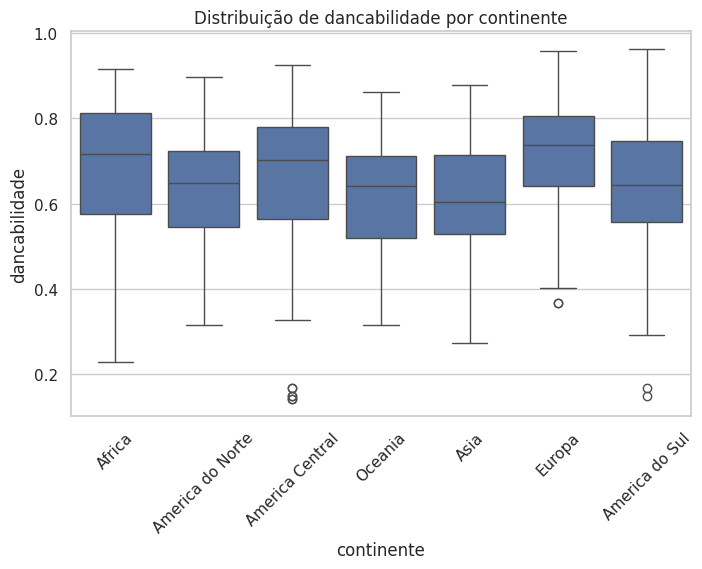

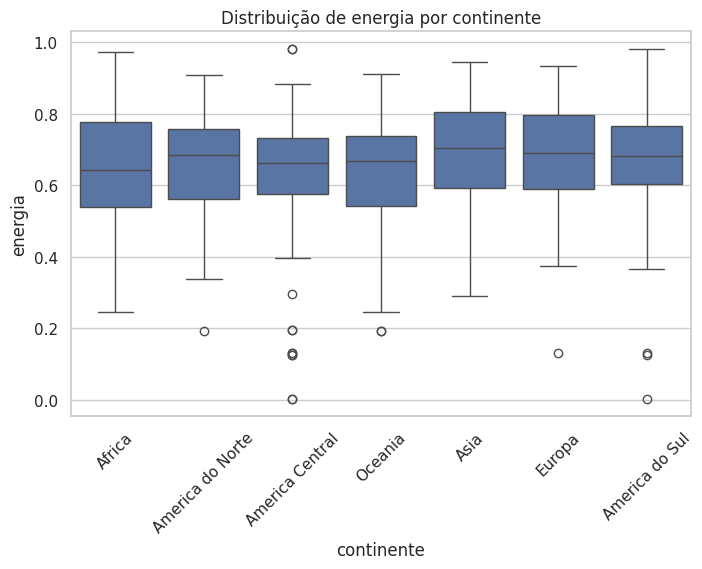

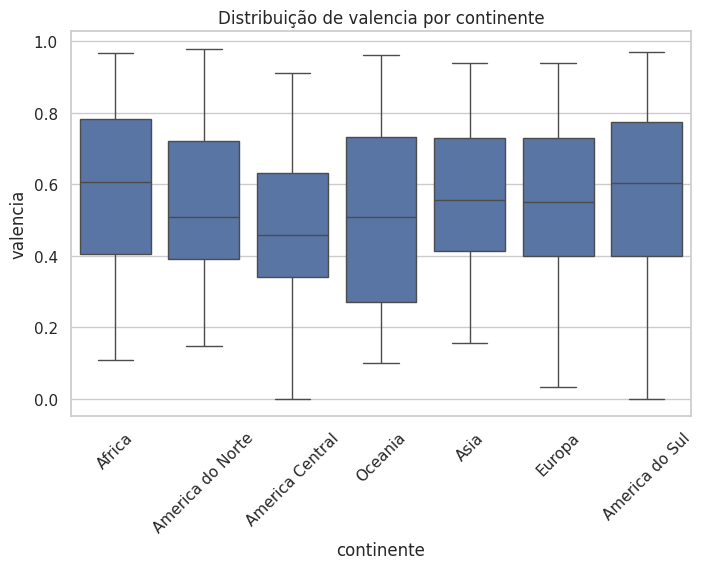

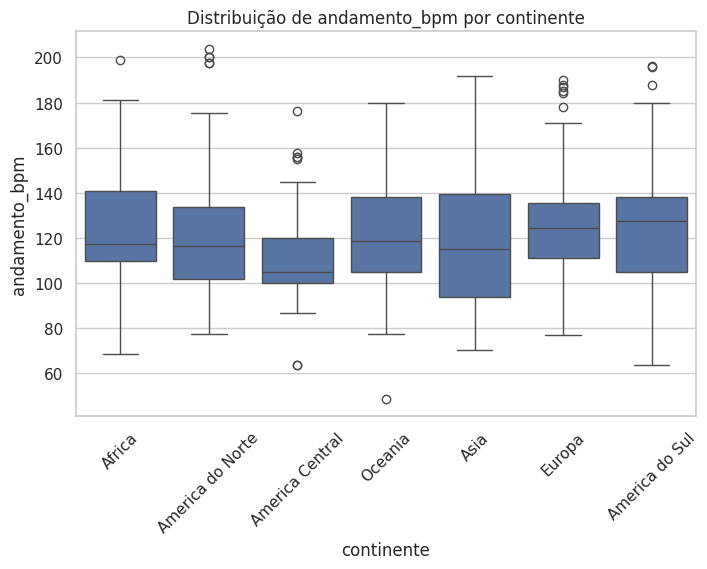

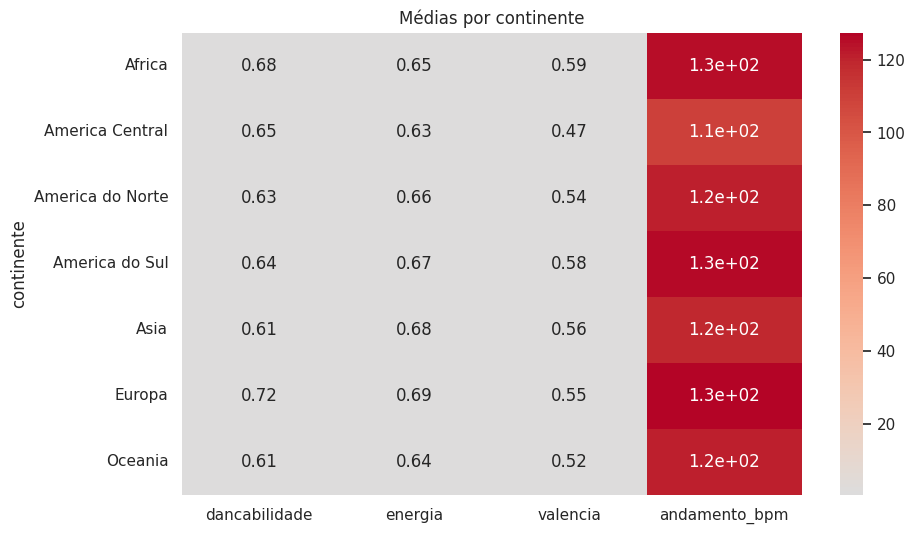

In [ ]:
# -----------------------------
# 1. Definir variáveis
# -----------------------------
variaveis = ["dancabilidade", "energia", "valencia", "andamento_bpm"]

# -----------------------------
# 2. MANOVA
# -----------------------------
formula = ' + '.join(variaveis) + ' ~ continente'
maov = MANOVA.from_formula(formula, data=df_paises_last)
print("\n📊 Resultado MANOVA:")
print(maov.mv_test())

# -----------------------------
# 3. ANOVA univariada + Tukey
# -----------------------------
for var in variaveis:
    print(f"\n📈 ANOVA para {var}:")
    model = ols(f'{var} ~ C(continente)', data=df_paises_last).fit()
    anova_table = sm.stats.anova_lm(model, typ=2)
    print(anova_table)

    # Tukey se ANOVA for significativa
    if anova_table["PR(>F)"][0] < 0.05:
        tukey = pairwise_tukeyhsd(endog=df_paises_last[var],
                                  groups=df_paises_last['continente'],
                                  alpha=0.05)
        print("\nPost-hoc Tukey:")
        print(tukey)

# -----------------------------
# 4. Visualizações
# -----------------------------

# Boxplots por variável
for var in variaveis:
    plt.figure(figsize=(8,5))
    sns.boxplot(x="continente", y=var, data=df_paises_last)
    plt.title(f"Distribuição de {var} por continente")
    plt.xticks(rotation=45)
    plt.show()

# Heatmap das médias por continente
plt.figure(figsize=(10,6))
sns.heatmap(df_paises_last.groupby("continente")[variaveis].mean(),
            annot=True, cmap="coolwarm", center=0)
plt.title("Médias por continente")
plt.show()

# Regressão Logística - Com Balanceamento

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, roc_curve, roc_auc_score
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from imblearn.over_sampling import SMOTE
import statsmodels.api as sm

sns.set(style="whitegrid", font_scale=1.1)

## Dados e variáveis

In [ ]:
X = df_paises_last[['duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala',
                    'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm']]
y = df_paises_last['hemisferio']

print("Tamanho total:", X.shape)
print("\nDistribuição de classes:\n", y.value_counts())

Tamanho total: (700, 10)

Distribuição de classes:
 hemisferio
Norte    450
Sul      250
Name: count, dtype: int64


## Análise de corelação

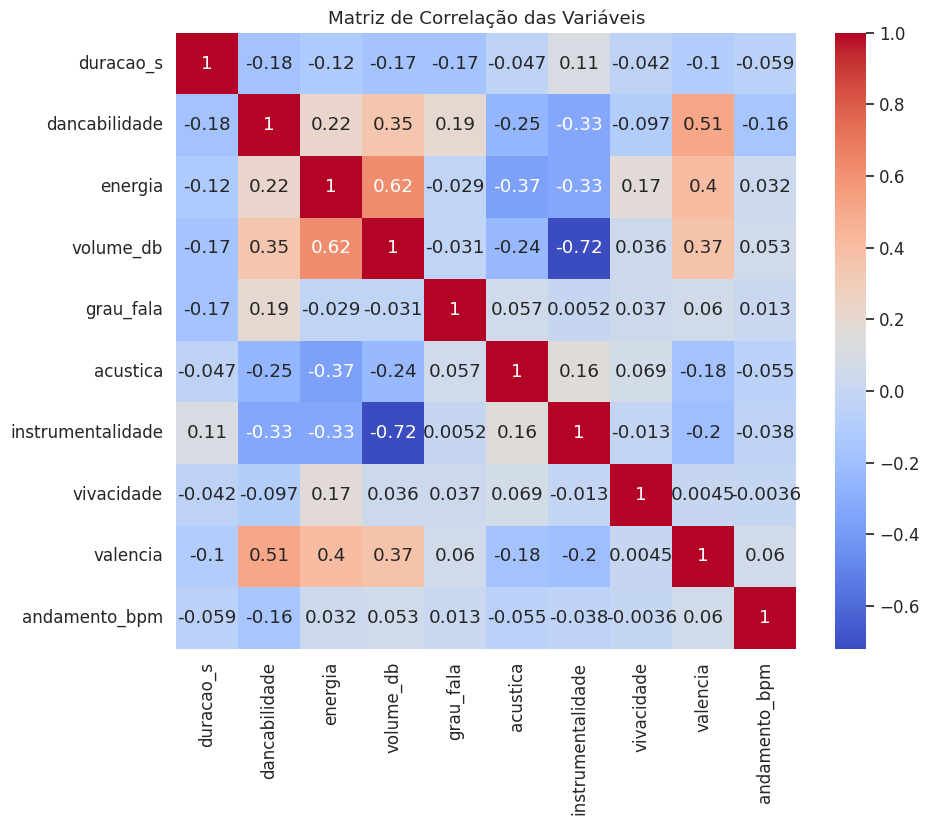

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm')
plt.title("Matriz de Correlação das Variáveis")
plt.show()

## Treino / teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("\nTamanho treino:", X_train.shape)
print("Tamanho teste:", X_test.shape)


Tamanho treino: (490, 10)
Tamanho teste: (210, 10)


## Escalonamento (padronização das variáveis)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## VIF (multicolinearidade)

In [ ]:
vif = pd.DataFrame()
vif["Variável"] = X.columns
vif["VIF"] = [variance_inflation_factor(X_train_scaled, i) for i in range(X.shape[1])]
print("\n--- VIF ---")
print(vif.sort_values(by="VIF", ascending=False))


--- VIF ---
            Variável       VIF
3          volume_db  3.479855
6  instrumentalidade  2.331156
2            energia  2.178126
1      dancabilidade  1.767379
8           valencia  1.654186
5           acustica  1.224870
7         vivacidade  1.097172
0          duracao_s  1.094823
9      andamento_bpm  1.085334
4          grau_fala  1.062195


## Balanceamento (SMOTE)

In [ ]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

## Treinamento do modelo

In [ ]:
modelo = LogisticRegression(max_iter=1000, penalty='l2', solver='lbfgs', random_state=42)
modelo.fit(X_train_bal, y_train_bal)

LogisticRegression(max_iter=1000, random_state=42)

## Validação cruzada

In [ ]:
scores = cross_val_score(modelo, X_train_bal, y_train_bal, cv=5, scoring='accuracy')
print("\nAcurácias por fold:", scores)
print("Acurácia média (CV):", scores.mean())


Acurácias por fold: [0.57142857 0.6031746  0.55555556 0.5952381  0.57142857]
Acurácia média (CV): 0.5793650793650793


## Avaliação no conjunto de teste


Acurácia no teste: 0.5857142857142857

Relatório de Classificação:
               precision    recall  f1-score   support

       Norte       0.69      0.65      0.67       135
         Sul       0.43      0.47      0.45        75

    accuracy                           0.59       210
   macro avg       0.56      0.56      0.56       210
weighted avg       0.59      0.59      0.59       210



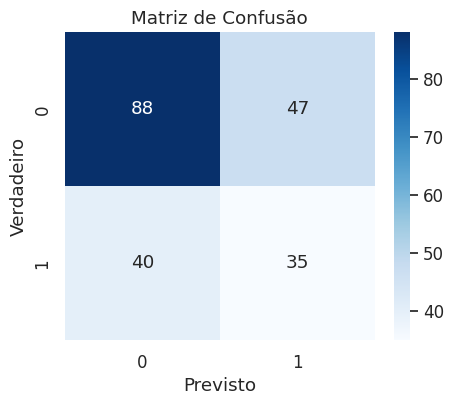

In [ ]:
y_pred = modelo.predict(X_test_scaled)

print("\nAcurácia no teste:", accuracy_score(y_test, y_pred))
print("\nRelatório de Classificação:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusão")
plt.xlabel("Previsto")
plt.ylabel("Verdadeiro")
plt.show()

## Coeficientes e Odds Ratio


--- Coeficientes ---


,Variável,Coeficiente (log-odds),Odds Ratio (exp(coef))
0,duracao_s,0.381208,1.464052
3,volume_db,0.341006,1.406361
7,vivacidade,0.316806,1.372736
6,instrumentalidade,0.200157,1.221594
9,andamento_bpm,0.186099,1.204541
8,valencia,0.157578,1.170672
5,acustica,0.153043,1.165376
1,dancabilidade,0.143407,1.154199
2,energia,-0.213811,0.807501
4,grau_fala,-0.296286,0.743575


/tmp/ipython-input-2356288128.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


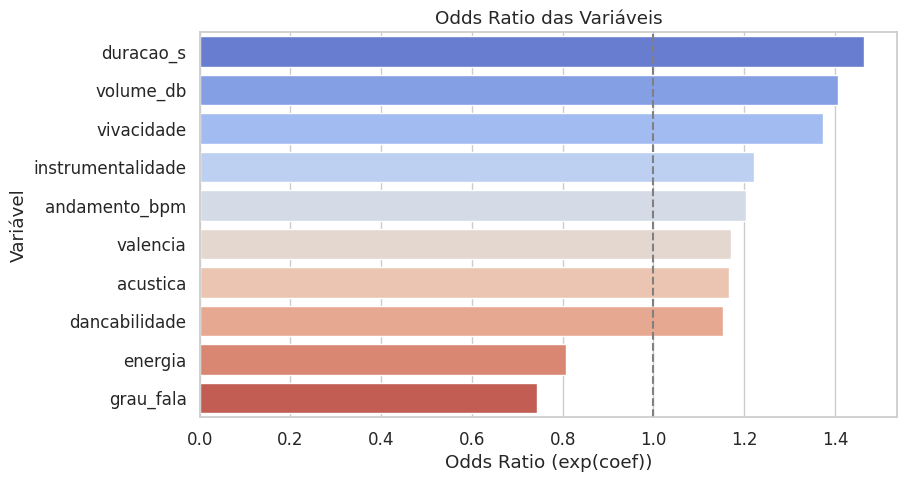

In [ ]:
coef_df = pd.DataFrame({
    'Variável': X.columns,
    'Coeficiente (log-odds)': modelo.coef_[0],
    'Odds Ratio (exp(coef))': np.exp(modelo.coef_[0])
}).sort_values(by='Odds Ratio (exp(coef))', ascending=False)

print("\n--- Coeficientes ---")
display(coef_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=coef_df, x='Odds Ratio (exp(coef))', y='Variável', palette='coolwarm'
)
plt.axvline(1, color='gray', linestyle='--')
plt.title('Odds Ratio das Variáveis')
plt.show()

## Curva ROC e AUC

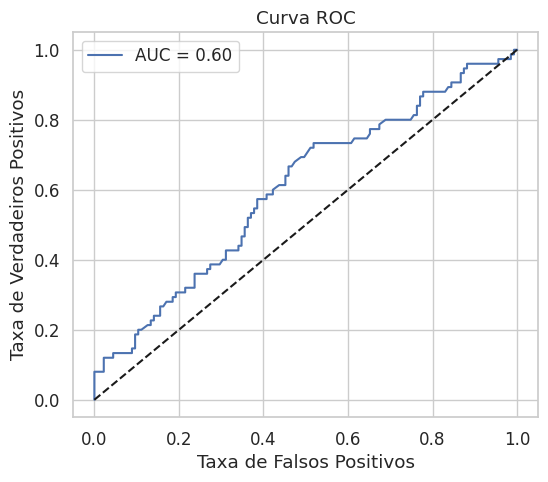

In [ ]:
y_test_bin = y_test.map({y.unique()[0]: 1, y.unique()[1]: 0})
y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, _ = roc_curve(y_test_bin, y_prob)
auc = roc_auc_score(y_test_bin, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend()
plt.show()

## Diagnóstico estatístico (statsmodels)

In [ ]:
X_const = sm.add_constant(X_train_bal)
modelo_sm = sm.Logit(y_train_bal.map({y.unique()[0]: 0, y.unique()[1]: 1}), X_const)
resultado = modelo_sm.fit(disp=False)

print("\n--- Resumo Estatístico ---")
print(resultado.summary())


--- Resumo Estatístico ---
                           Logit Regression Results                           
Dep. Variable:             hemisferio   No. Observations:                  630
Model:                          Logit   Df Residuals:                      619
Method:                           MLE   Df Model:                           10
Date:                Tue, 09 Dec 2025   Pseudo R-squ.:                 0.05998
Time:                        02:36:55   Log-Likelihood:                -410.49
converged:                       True   LL-Null:                       -436.68
Covariance Type:            nonrobust   LLR p-value:                 9.669e-08
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0516      0.084      0.615      0.539      -0.113       0.216
x1            -0.3861      0.089     -4.322      0.000      -0.561      -0.211
x2            -0.1467   

## Resíduos de Pearson

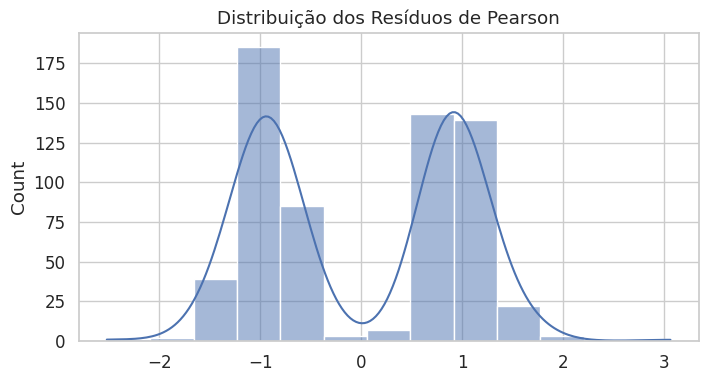

In [ ]:
residuos = resultado.resid_pearson
plt.figure(figsize=(8, 4))
sns.histplot(residuos, kde=True)
plt.title("Distribuição dos Resíduos de Pearson")
plt.show()

## Influência (Cook’s Distance)

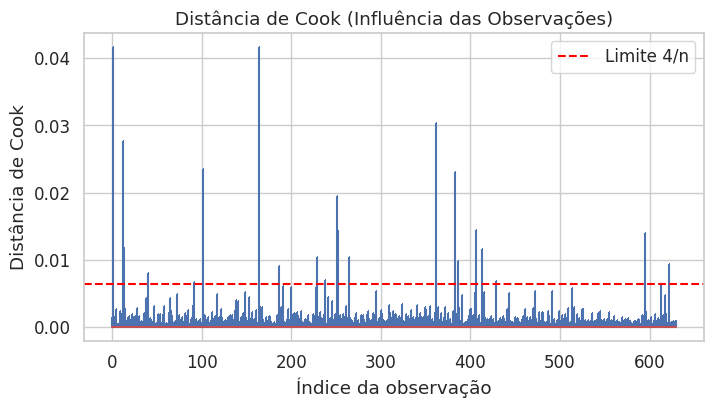


Observações potencialmente influentes (Cook's D > 4/n): 21
[  1  12  13  40  92 101 164 186 229 238]


In [ ]:
influence = resultado.get_influence()
cook_d = influence.cooks_distance[0]

plt.figure(figsize=(8, 4))
plt.stem(np.arange(len(cook_d)), cook_d, markerfmt=",")
plt.axhline(4 / len(cook_d), color='red', linestyle='--', label='Limite 4/n')
plt.title("Distância de Cook (Influência das Observações)")
plt.xlabel("Índice da observação")
plt.ylabel("Distância de Cook")
plt.legend()
plt.show()

influentes = np.where(cook_d > 4 / len(cook_d))[0]
print(f"\nObservações potencialmente influentes (Cook's D > 4/n): {len(influentes)}")
print(influentes[:10])


## Análise de erros com alta confiança

In [ ]:
y_pred_proba = modelo.predict_proba(X_test_scaled)
probabilidades = pd.DataFrame(y_pred_proba, columns=modelo.classes_)
probabilidades['predito'] = y_pred
probabilidades['verdadeiro'] = y_test.values

colunas_prob = list(modelo.classes_)
alto_erro = probabilidades[
    (probabilidades['predito'] != probabilidades['verdadeiro']) &
    (probabilidades[colunas_prob].max(axis=1) > 0.8)
]
print("\n--- Casos com alta confiança e erro ---")
display(alto_erro.head())


--- Casos com alta confiança e erro ---


,Norte,Sul,predito,verdadeiro
150,0.807919,0.192081,Norte,Sul
208,0.805393,0.194607,Norte,Sul


#Regressão Logística - Sem Balanceamento

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, roc_curve, roc_auc_score
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

sns.set(style="whitegrid", font_scale=1.1)

## Dados e variáveis

In [ ]:
X = df_paises_last[['duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala',
                    'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm']]
y = df_paises_last['hemisferio']

print("Tamanho total:", X.shape)
print("\nDistribuição de classes:\n", y.value_counts())

Tamanho total: (700, 10)

Distribuição de classes:
 hemisferio
Norte    450
Sul      250
Name: count, dtype: int64


## Análise de corelação

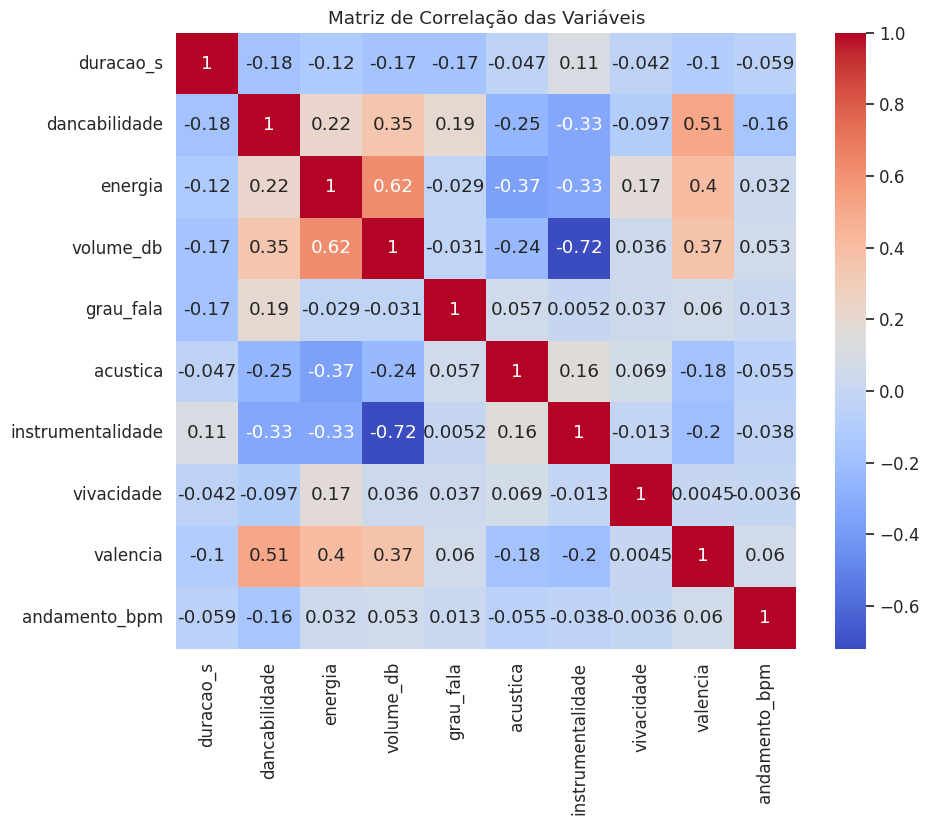

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm')
plt.title("Matriz de Correlação das Variáveis")
plt.show()

## Treino / teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("\nTamanho treino:", X_train.shape)
print("Tamanho teste:", X_test.shape)


Tamanho treino: (490, 10)
Tamanho teste: (210, 10)


## Escalonamento (padronização das variáveis)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## VIF (multicolinearidade)

In [ ]:
vif = pd.DataFrame()
vif["Variável"] = X.columns
vif["VIF"] = [variance_inflation_factor(X_train_scaled, i) for i in range(X.shape[1])]
print("\n--- VIF ---")
print(vif.sort_values(by="VIF", ascending=False))


--- VIF ---
            Variável       VIF
3          volume_db  3.479855
6  instrumentalidade  2.331156
2            energia  2.178126
1      dancabilidade  1.767379
8           valencia  1.654186
5           acustica  1.224870
7         vivacidade  1.097172
0          duracao_s  1.094823
9      andamento_bpm  1.085334
4          grau_fala  1.062195


## Treinamento do modelo

In [ ]:
modelo = LogisticRegression(max_iter=1000, penalty='l2', solver='lbfgs', random_state=42)
modelo.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

## Validação cruzada

In [ ]:
scores = cross_val_score(modelo, X_train_scaled, y_train, cv=5, scoring='accuracy')
print("\nAcurácias por fold:", np.round(scores, 4))
print("Acurácia média (CV):", scores.mean().round(4))


Acurácias por fold: [0.6327 0.5918 0.6837 0.6939 0.6735]
Acurácia média (CV): 0.6551


## Avaliação no conjunto de teste


Acurácia no teste: 0.6476190476190476

Relatório de Classificação:
               precision    recall  f1-score   support

       Norte       0.66      0.93      0.77       135
         Sul       0.53      0.13      0.21        75

    accuracy                           0.65       210
   macro avg       0.59      0.53      0.49       210
weighted avg       0.61      0.65      0.57       210



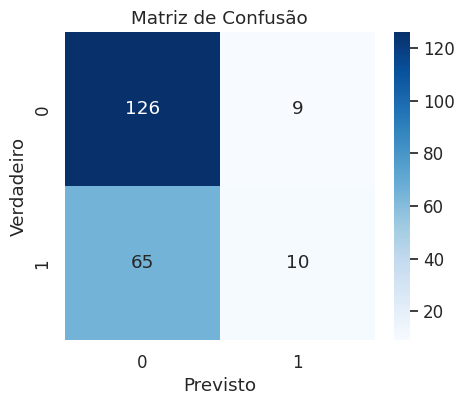

In [ ]:
y_pred = modelo.predict(X_test_scaled)

print("\nAcurácia no teste:", accuracy_score(y_test, y_pred))
print("\nRelatório de Classificação:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusão")
plt.xlabel("Previsto")
plt.ylabel("Verdadeiro")
plt.show()

## Coeficientes e Odds Ratio


--- Coeficientes ---


,Variável,Coeficiente (log-odds),Odds Ratio (exp(coef))
7,vivacidade,0.366186,1.442223
0,duracao_s,0.343377,1.409700
3,volume_db,0.263389,1.301333
6,instrumentalidade,0.178991,1.196010
9,andamento_bpm,0.162426,1.176362
8,valencia,0.151012,1.163010
5,acustica,0.090907,1.095167
1,dancabilidade,0.078501,1.081665
4,grau_fala,-0.213933,0.807403
2,energia,-0.240761,0.786030


/tmp/ipython-input-1634827285.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


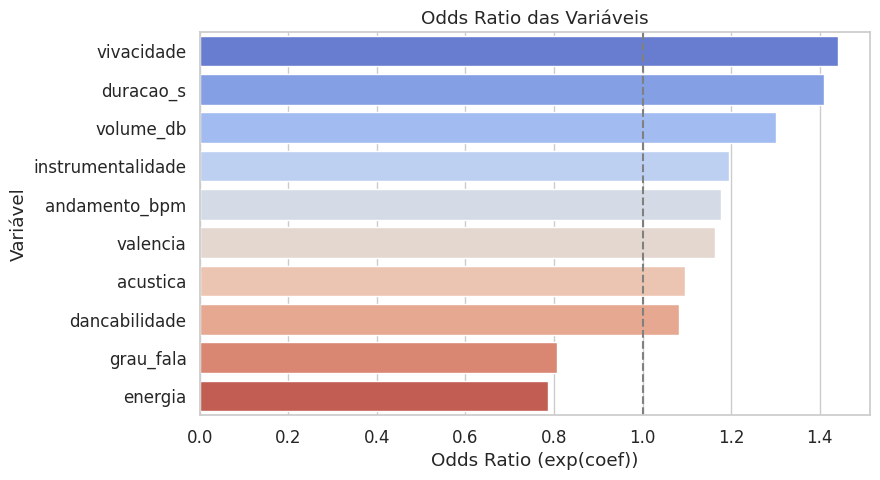

In [ ]:
coef_df = pd.DataFrame({
    'Variável': X.columns,
    'Coeficiente (log-odds)': modelo.coef_[0],
    'Odds Ratio (exp(coef))': np.exp(modelo.coef_[0])
}).sort_values(by='Odds Ratio (exp(coef))', ascending=False)

print("\n--- Coeficientes ---")
display(coef_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=coef_df, x='Odds Ratio (exp(coef))', y='Variável',
    palette='coolwarm', orient='h'
)
plt.axvline(1, color='gray', linestyle='--')
plt.title('Odds Ratio das Variáveis')
plt.tight_layout()
plt.show()

## Curva ROC e AUC

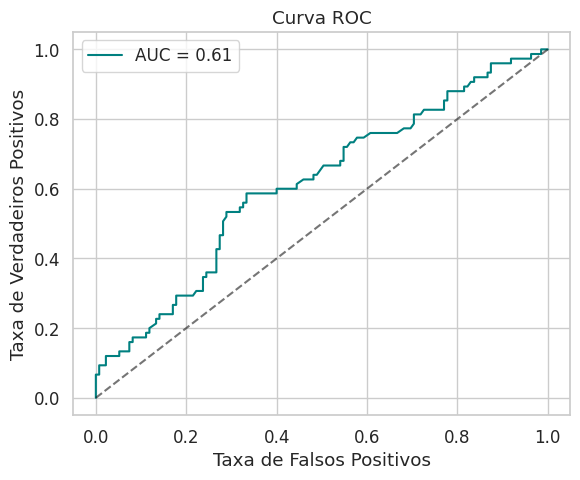

In [ ]:
classe0, classe1 = y.unique()
y_test_bin = y_test.map({classe0: 1, classe1: 0})
y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, _ = roc_curve(y_test_bin, y_prob)
auc = roc_auc_score(y_test_bin, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}', color='teal')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.6)
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend()
plt.tight_layout()
plt.show()

## Diagnóstico estatístico (statsmodels)

In [ ]:
X_const = sm.add_constant(X_train_scaled)
y_train_bin = y_train.map({classe0: 0, classe1: 1})

modelo_sm = sm.Logit(y_train_bin, X_const)
resultado = modelo_sm.fit(disp=False)

print("\n--- Resumo Estatístico ---")
print(resultado.summary())


--- Resumo Estatístico ---
                           Logit Regression Results                           
Dep. Variable:             hemisferio   No. Observations:                  490
Model:                          Logit   Df Residuals:                      479
Method:                           MLE   Df Model:                           10
Date:                Tue, 09 Dec 2025   Pseudo R-squ.:                 0.05389
Time:                        02:36:57   Log-Likelihood:                -302.15
converged:                       True   LL-Null:                       -319.36
Covariance Type:            nonrobust   LLR p-value:                 0.0001567
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6227      0.099      6.319      0.000       0.430       0.816
x1            -0.3481      0.103     -3.390      0.001      -0.549      -0.147
x2            -0.0811   

## Resíduos de Pearson

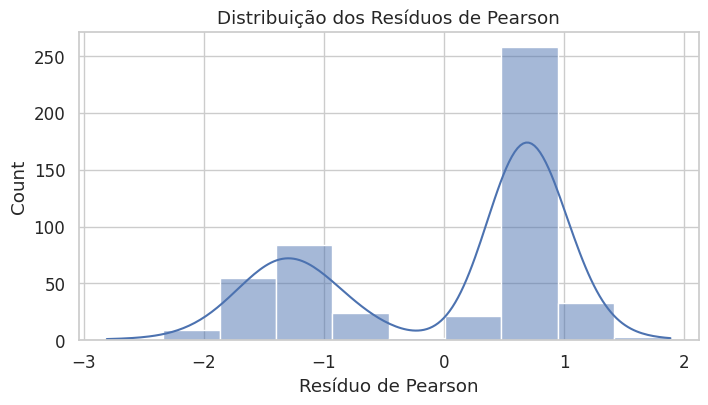

In [ ]:
residuos = resultado.resid_pearson
plt.figure(figsize=(8, 4))
sns.histplot(residuos, kde=True)
plt.title("Distribuição dos Resíduos de Pearson")
plt.xlabel("Resíduo de Pearson")
plt.show()

## Influência (Cook’s Distance)

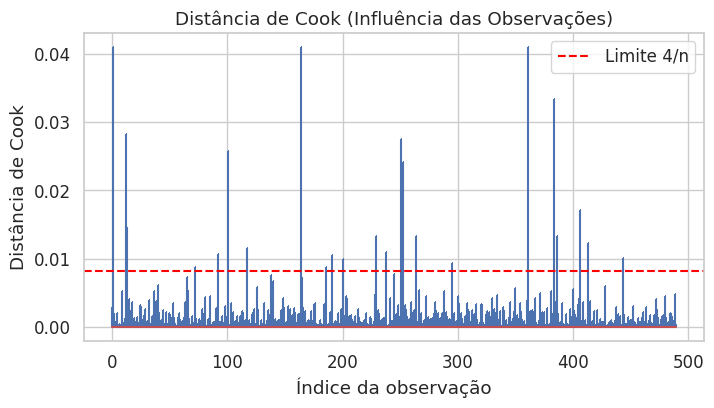


Observações potencialmente influentes (Cook's D > 4/n): 23
[  1  12  13  72  92 101 117 164 186 191]


In [ ]:
influence = resultado.get_influence()
cook_d = influence.cooks_distance[0]

plt.figure(figsize=(8, 4))
plt.stem(np.arange(len(cook_d)), cook_d, markerfmt=",")
plt.axhline(4 / len(cook_d), color='red', linestyle='--', label='Limite 4/n')
plt.title("Distância de Cook (Influência das Observações)")
plt.xlabel("Índice da observação")
plt.ylabel("Distância de Cook")
plt.legend()
plt.show()

influentes = np.where(cook_d > 4 / len(cook_d))[0]
print(f"\nObservações potencialmente influentes (Cook's D > 4/n): {len(influentes)}")
print(influentes[:10])

## Análise de erros com alta confiança

In [ ]:
y_pred_proba = modelo.predict_proba(X_test_scaled)
probabilidades = pd.DataFrame(y_pred_proba, columns=modelo.classes_)
probabilidades['predito'] = y_pred
probabilidades['verdadeiro'] = y_test.values

colunas_prob = list(modelo.classes_)
alto_erro = probabilidades[
    (probabilidades['predito'] != probabilidades['verdadeiro']) &
    (probabilidades[colunas_prob].max(axis=1) > 0.8)
]
print("\n--- Casos com alta confiança e erro ---")
display(alto_erro.head())


--- Casos com alta confiança e erro ---


,Norte,Sul,predito,verdadeiro
130,0.842997,0.157003,Norte,Sul
150,0.852273,0.147727,Norte,Sul
208,0.817921,0.182079,Norte,Sul


# Análise Discriminantes Linear - Com Balanceamento

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, roc_auc_score, auc as calc_auc

from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import shapiro
import numpy.linalg as la

from imblearn.over_sampling import SMOTE

## Dados e variáveis

In [ ]:
X = df_paises_last[['duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala',
                    'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm']]
y = df_paises_last['hemisferio']

print("Tamanho total:", X.shape)
print("\nDistribuição de classes:\n", y.value_counts())

Tamanho total: (700, 10)

Distribuição de classes:
 hemisferio
Norte    450
Sul      250
Name: count, dtype: int64


## Visualização: histogramas por classe

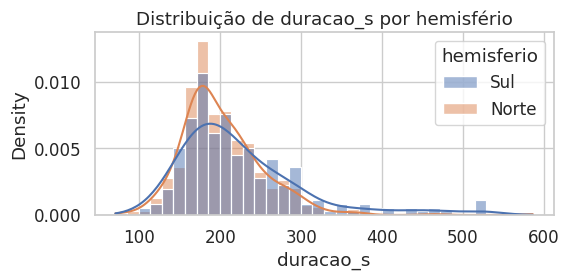

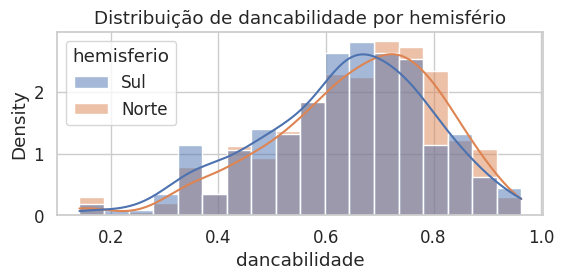

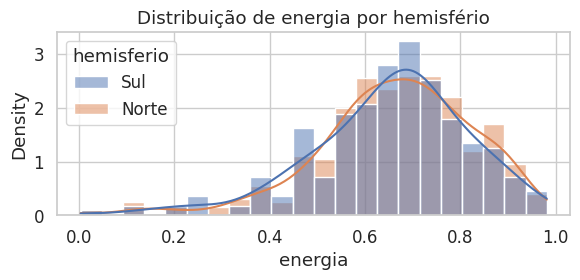

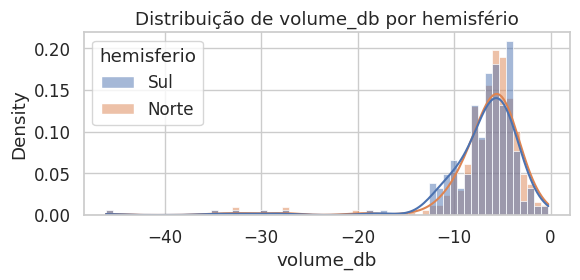

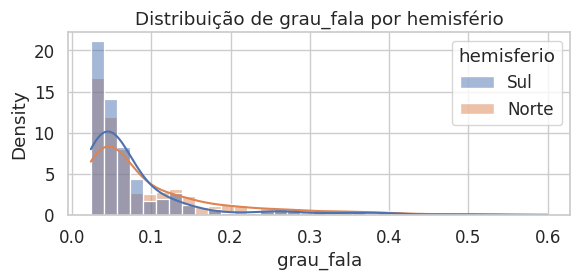

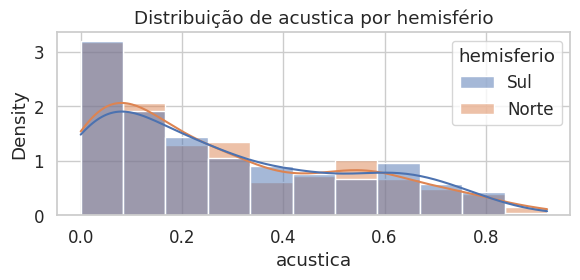

/tmp/ipython-input-1775422463.py:5: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


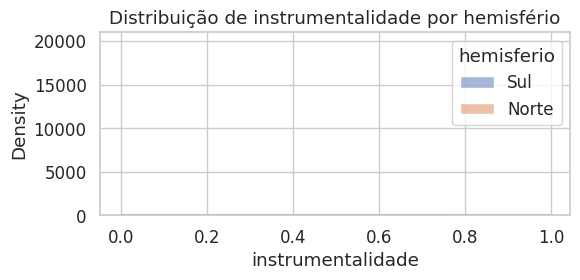

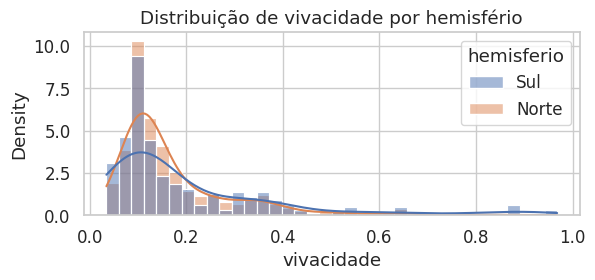

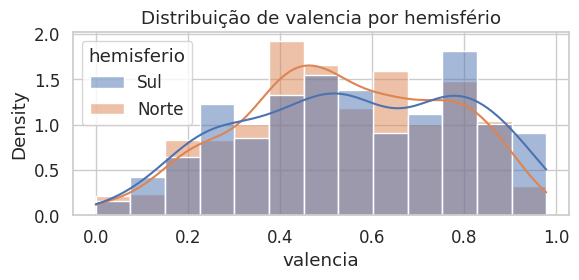

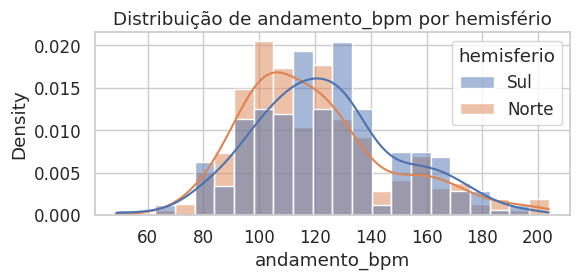

In [ ]:
for col in X.columns:
    plt.figure(figsize=(6,3))
    sns.histplot(data=df_paises_last, x=col, hue='hemisferio', kde=True, stat='density', common_norm=False)
    plt.title(f'Distribuição de {col} por hemisfério')
    plt.tight_layout()
    plt.show()

## Boxplots por hemisfério

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


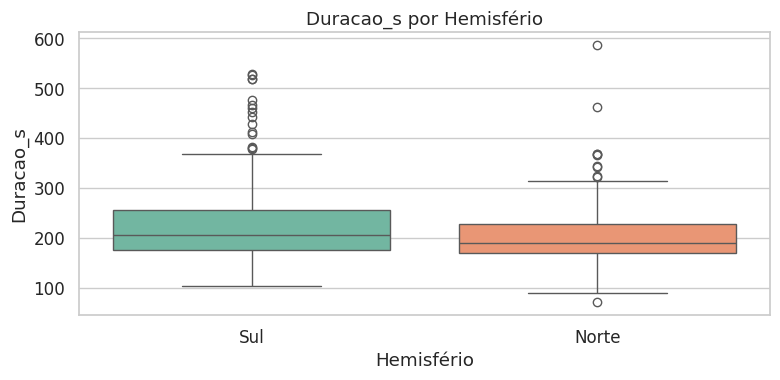

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


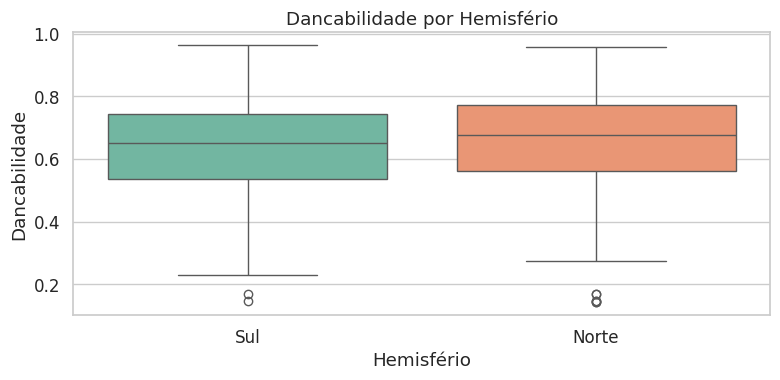

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


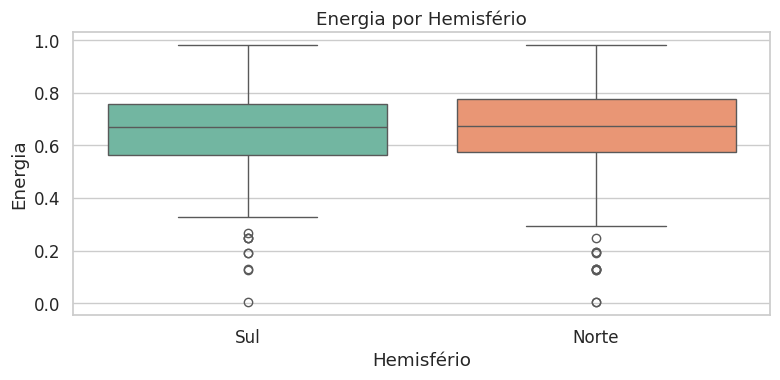

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


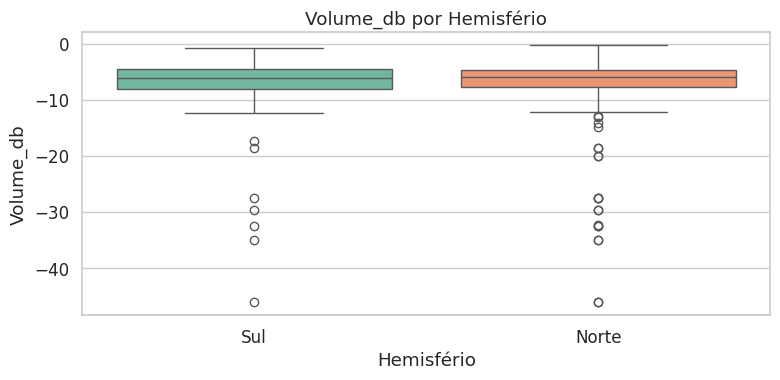

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


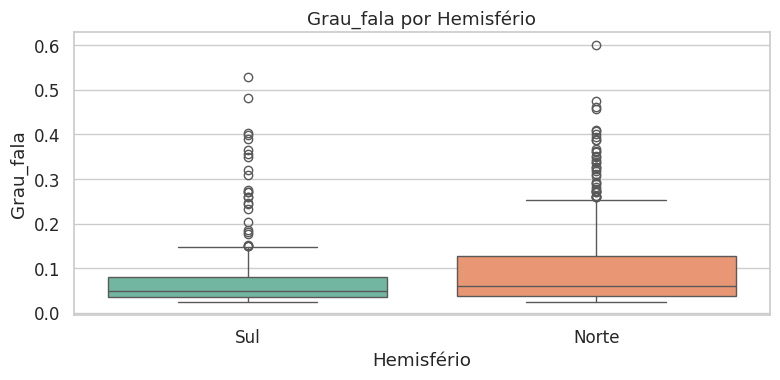

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


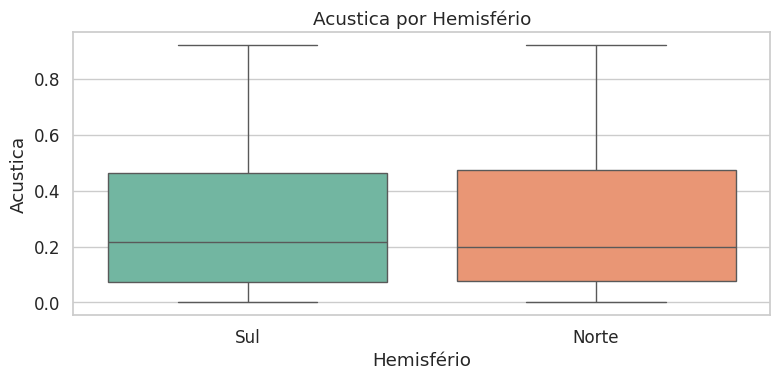

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


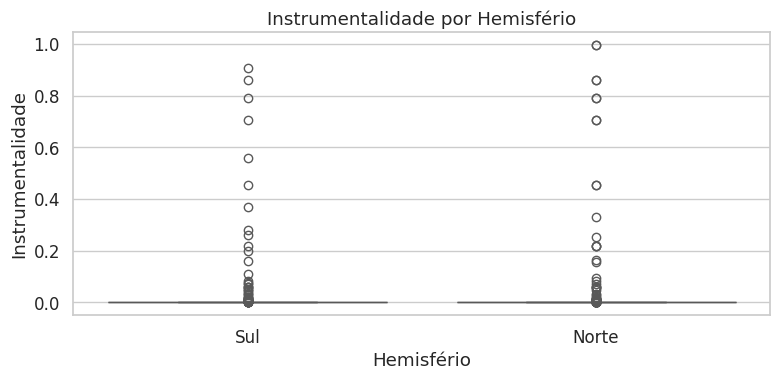

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


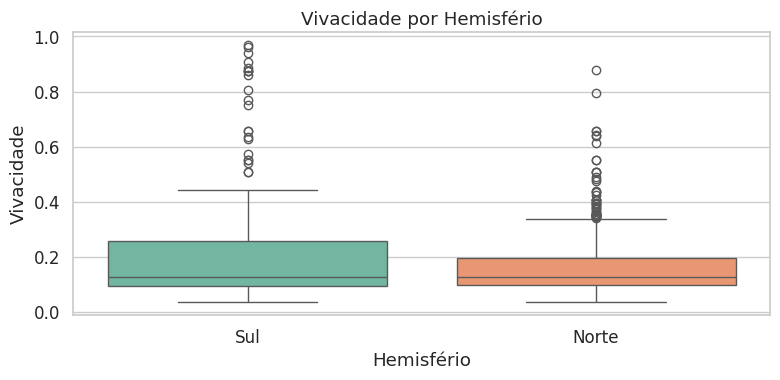

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


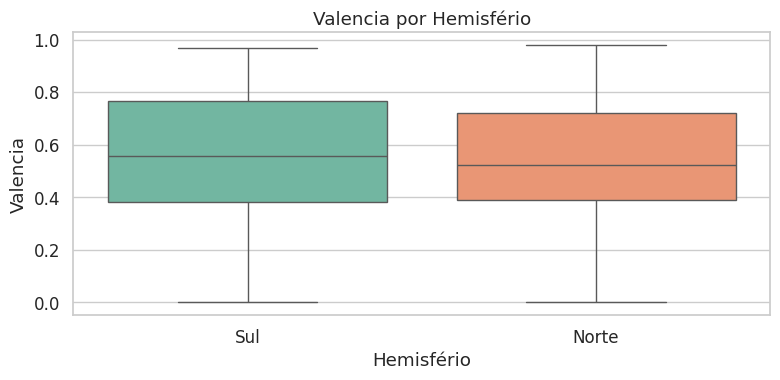

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


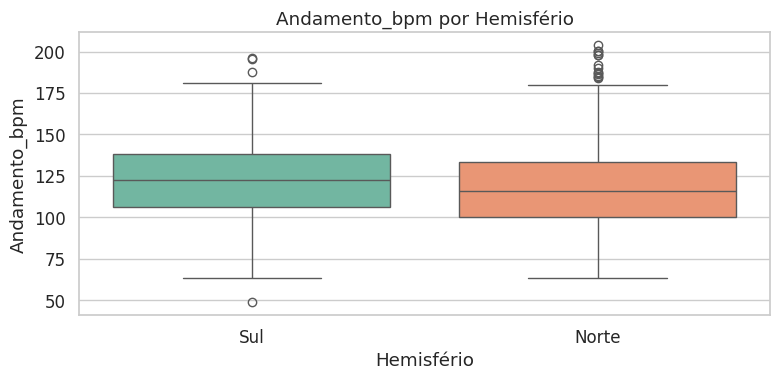

In [ ]:
for col in X.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')
    plt.title(f'{col.capitalize()} por Hemisfério')
    plt.xlabel('Hemisfério')
    plt.ylabel(col.capitalize())
    plt.tight_layout()
    plt.show()


## Análise de correlação

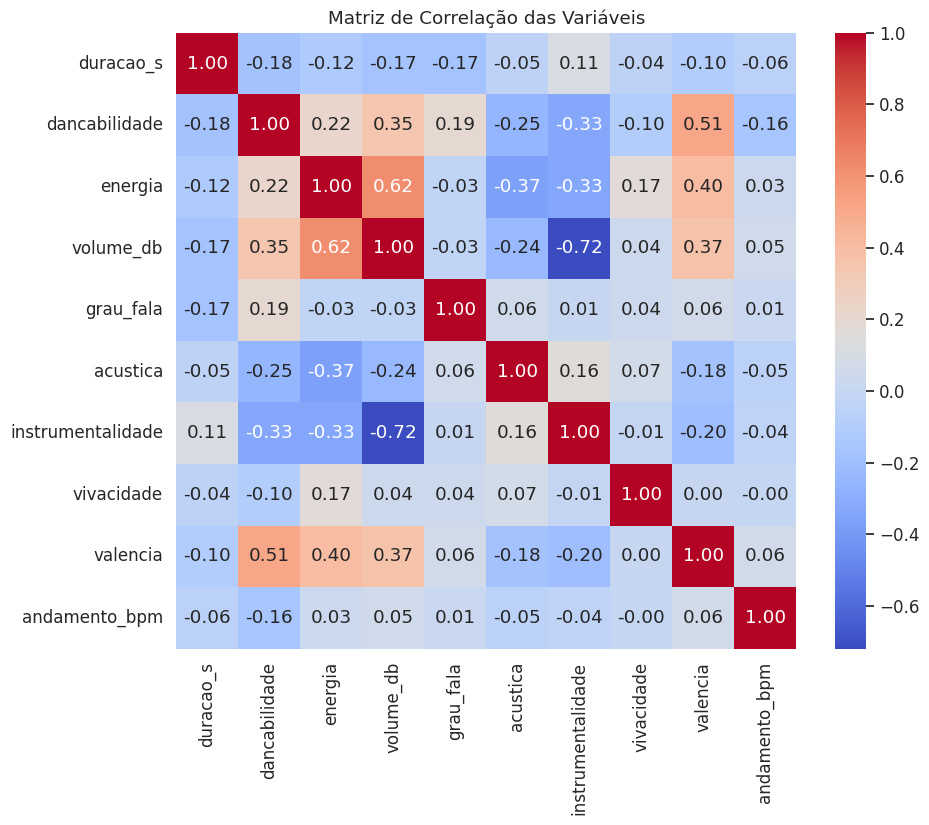

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlação das Variáveis")
plt.show()

## Treino / teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("\nTamanho treino:", X_train.shape)
print("Tamanho teste:", X_test.shape)


Tamanho treino: (490, 10)
Tamanho teste: (210, 10)


## Escalonamento (padronização das variáveis)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Balanceamento (SMOTE)

In [ ]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("Distribuição antes do SMOTE:")
print(y_train.value_counts())
print("\nDistribuição após o SMOTE:")
print(y_train_res.value_counts())

Distribuição antes do SMOTE:
hemisferio
Norte    315
Sul      175
Name: count, dtype: int64

Distribuição após o SMOTE:
hemisferio
Sul      315
Norte    315
Name: count, dtype: int64


## VIF (multicolinearidade)

In [ ]:
vif_df = pd.DataFrame({
    "Variável": X.columns,
    "VIF": [variance_inflation_factor(X_train_scaled, i) for i in range(X_train_scaled.shape[1])]
})
print("\n--- VIF ---")
print(vif_df.sort_values(by="VIF", ascending=False).reset_index(drop=True))


--- VIF ---
            Variável       VIF
0          volume_db  3.479855
1  instrumentalidade  2.331156
2            energia  2.178126
3      dancabilidade  1.767379
4           valencia  1.654186
5           acustica  1.224870
6         vivacidade  1.097172
7          duracao_s  1.094823
8      andamento_bpm  1.085334
9          grau_fala  1.062195


## Testes de normalidade (Shapiro) por grupo

In [ ]:
num_cols = X.columns
norm_test = {}
for grupo in y.unique():
    norm_test[grupo] = {}
    subset = X[y == grupo]
    for col in num_cols:
        n = min(100, len(subset))
        if n < 3:
            p = np.nan
        else:
            stat, p = shapiro(subset[col].dropna().sample(n, random_state=42))
        norm_test[grupo][col] = p

for g in norm_test:
    print(f"\nTeste de Shapiro para grupo {g}:")
    print(pd.Series(norm_test[g]).sort_values())


Teste de Shapiro para grupo Sul:
instrumentalidade    5.225354e-20
grau_fala            7.108033e-16
vivacidade           2.599244e-13
volume_db            2.653317e-13
duracao_s            6.458027e-09
acustica             5.420814e-07
energia              1.748678e-03
valencia             4.742382e-03
dancabilidade        6.040767e-03
andamento_bpm        2.417945e-01
dtype: float64

Teste de Shapiro para grupo Norte:
instrumentalidade    1.149598e-20
volume_db            1.385407e-16
grau_fala            2.260036e-12
vivacidade           2.507305e-11
acustica             1.551035e-06
energia              3.806812e-05
andamento_bpm        1.714516e-04
dancabilidade        2.565090e-04
duracao_s            3.413024e-03
valencia             1.046924e-01
dtype: float64


## Box's M aproximado (matriz de covariância igualdade)

In [ ]:
def box_m_test(X_values, y_values):
    groups = np.unique(y_values)
    ni, Si = [], []
    for g in groups:
        Xi = X_values[y_values == g]
        ni.append(Xi.shape[0])
        Si.append(np.cov(Xi, rowvar=False, bias=True))
    pooled = sum([(ni[i]-1)*Si[i] for i in range(len(groups))]) / (sum(ni)-len(groups))

    term1 = 0.0
    for i in range(len(groups)):
        sign_i, logdet_i = la.slogdet(Si[i])
        term1 += (ni[i]-1) * logdet_i
    sign_p, logdet_p = la.slogdet(pooled)
    m_stat = term1 - (sum(ni)-len(groups)) * logdet_p
    return m_stat

X_np = X.values
y_np = y.values
try:
    boxm = box_m_test(X_np, y_np)
    print("\nEstatística aproximada de Box’s M:", boxm)
except Exception as e:
    print("\nBox's M não pôde ser calculado com estabilidade numérica:", e)


Estatística aproximada de Box’s M: -273.89873925035954


## Treinamento do modelo

In [ ]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_res, y_train_res)

y_pred = lda.predict(X_test_scaled)

## Validação cruzada

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(lda, X_train_res, y_train_res, cv=cv, scoring='accuracy')
print("\nAcurácias por fold (LDA):", np.round(cv_scores, 4))
print("Acurácia média (CV):", np.round(cv_scores.mean(), 4))


Acurácias por fold (LDA): [0.6349 0.5952 0.5079 0.5476 0.5873]
Acurácia média (CV): 0.5746


## Avaliação do conjunto teste


Acurácia no teste (LDA): 0.5904761904761905

Relatório de classificação (LDA):
               precision    recall  f1-score   support

       Norte     0.6899    0.6593    0.6742       135
         Sul     0.4321    0.4667    0.4487        75

    accuracy                         0.5905       210
   macro avg     0.5610    0.5630    0.5615       210
weighted avg     0.5978    0.5905    0.5937       210



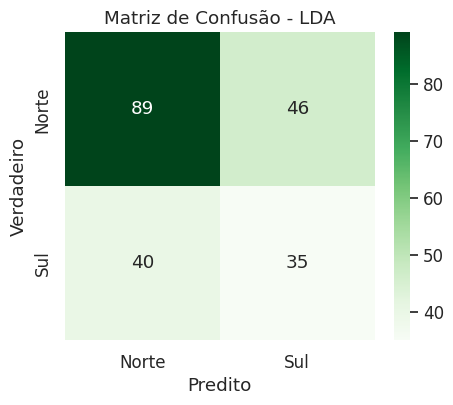

In [ ]:
print("\nAcurácia no teste (LDA):", accuracy_score(y_test, y_pred))
print("\nRelatório de classificação (LDA):\n", classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred, labels=lda.classes_)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=lda.classes_, yticklabels=lda.classes_)
plt.xlabel('Predito')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão - LDA')
plt.show()

## Curva ROC e AUC

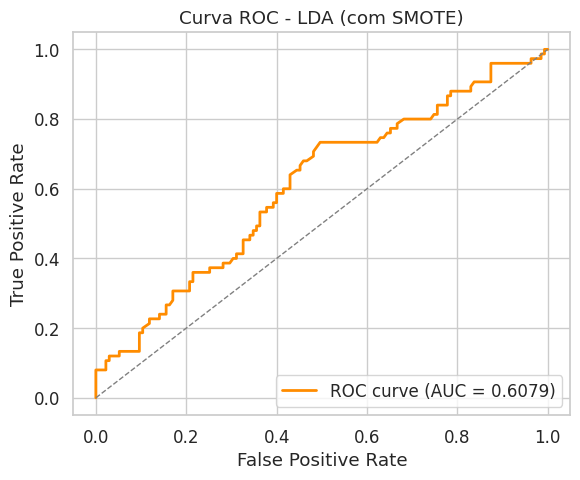

In [ ]:
if len(lda.classes_) == 2:
    y_prob = lda.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=lda.classes_[1])
    roc_auc = calc_auc(fpr, tpr)

    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Curva ROC - LDA (com SMOTE)')
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

else:
    y_bin = pd.get_dummies(y_test)
    y_score = lda.predict_proba(X_test_scaled)
    auc_macro = roc_auc_score(y_bin, y_score, multi_class='ovr', average='macro')
    auc_weighted = roc_auc_score(y_bin, y_score, multi_class='ovr', average='weighted')

    print(f"AUC macro (multiclasse): {auc_macro:.4f}")
    print(f"AUC weighted (multiclasse): {auc_weighted:.4f}")

## Coeficientes das funções discriminantes

In [ ]:
coef_df = pd.DataFrame(lda.coef_.T, index=X.columns, columns=[f'LD{i+1}' for i in range(lda.coef_.shape[0])])
print("\n--- Coeficientes LDA ---")
display(coef_df)


--- Coeficientes LDA ---


,LD1
duracao_s,0.368894
dancabilidade,0.134389
energia,-0.223804
volume_db,0.325416
grau_fala,-0.282336
acustica,0.146890
instrumentalidade,0.179240
vivacidade,0.297941
valencia,0.164527
andamento_bpm,0.180869


## Projeção

/tmp/ipython-input-3996206737.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_scores, x='hemisferio', y=col, palette='Set2')


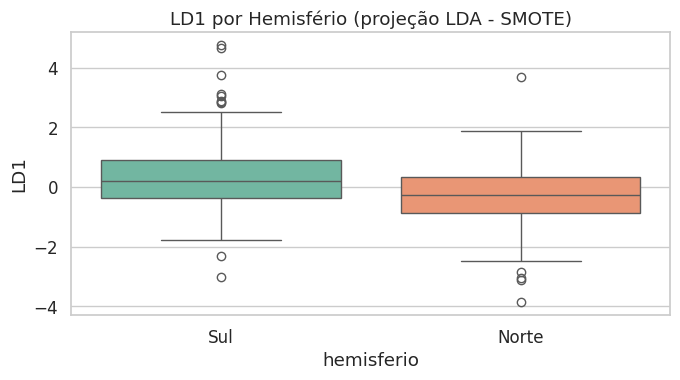

In [ ]:
X_train_lda = lda.transform(X_train_res)
ld_cols = [f'LD{i+1}' for i in range(X_train_lda.shape[1])]
df_scores = pd.DataFrame(X_train_lda, columns=ld_cols)
df_scores['hemisferio'] = y_train_res.values

for col in ld_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=df_scores, x='hemisferio', y=col, palette='Set2')
    plt.title(f'{col} por Hemisfério (projeção LDA - SMOTE)')
    plt.tight_layout()
    plt.show()

## Casos de alta confiança e erro

# Análise Discriminantes Linear - Sem Balanceamento

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import shapiro
import numpy.linalg as la
from sklearn.metrics import roc_curve, roc_auc_score, auc as calc_auc


## Dados e variáveis

In [ ]:
X = df_paises_last[['duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala',
                    'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm']]
y = df_paises_last['hemisferio']

print("Tamanho total:", X.shape)
print("\nDistribuição de classes:\n", y.value_counts())

Tamanho total: (700, 10)

Distribuição de classes:
 hemisferio
Norte    450
Sul      250
Name: count, dtype: int64


## Visualizações: histogramas por classe

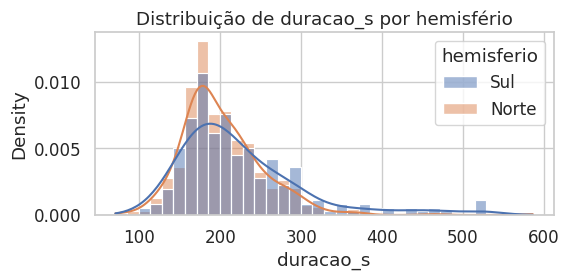

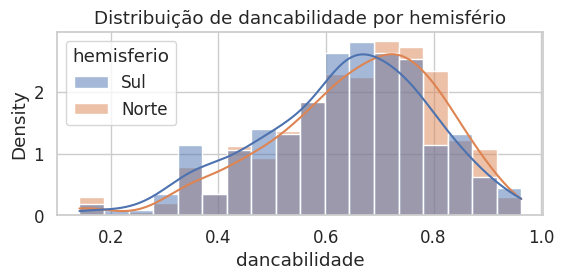

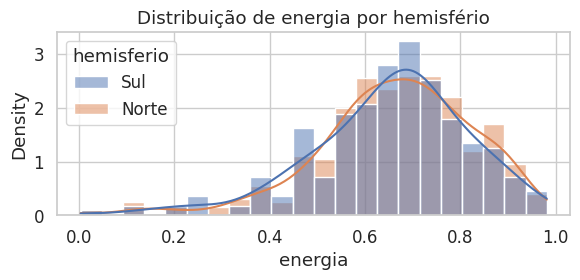

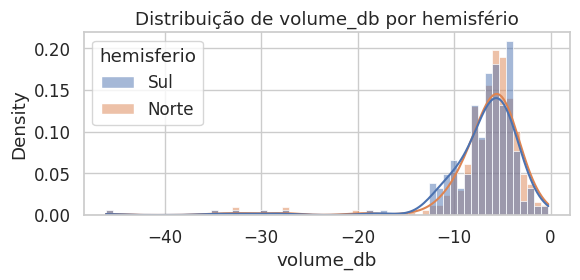

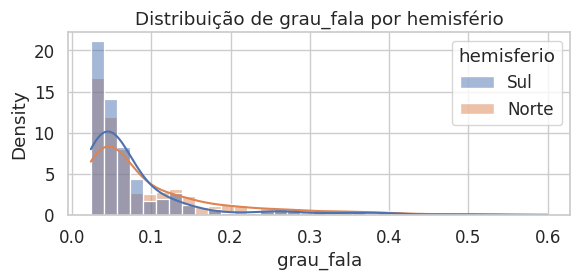

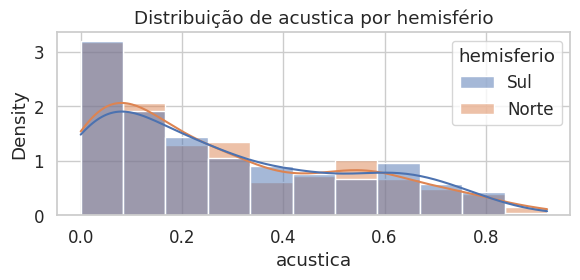

/tmp/ipython-input-1775422463.py:5: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


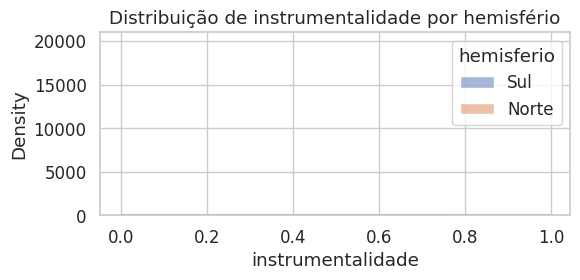

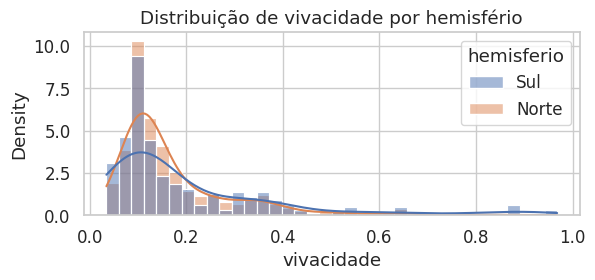

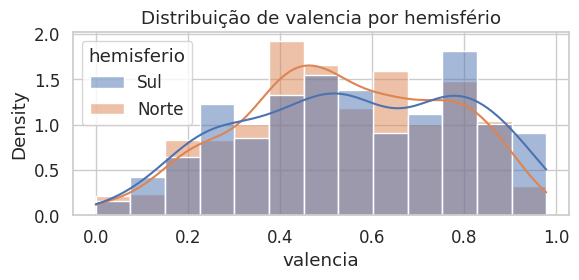

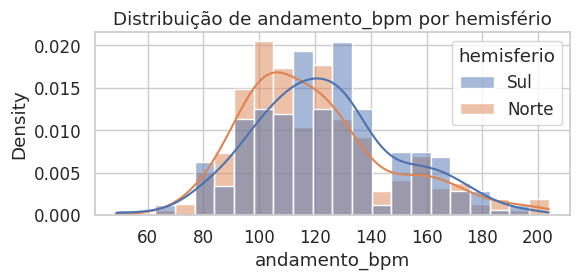

In [ ]:
for col in X.columns:
    plt.figure(figsize=(6,3))
    sns.histplot(data=df_paises_last, x=col, hue='hemisferio', kde=True, stat='density', common_norm=False)
    plt.title(f'Distribuição de {col} por hemisfério')
    plt.tight_layout()
    plt.show()

## Boxplots por hemisfério

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


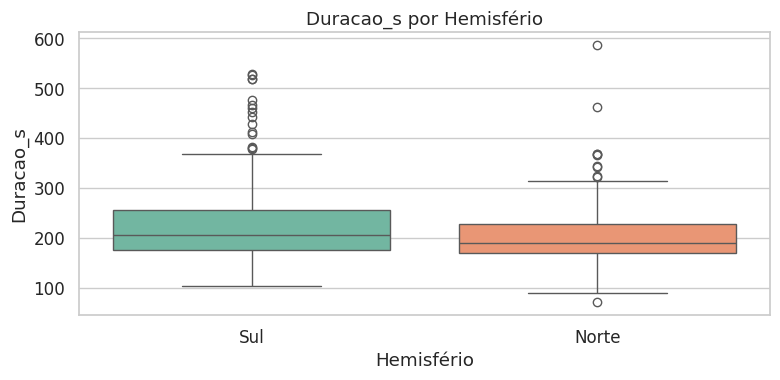

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


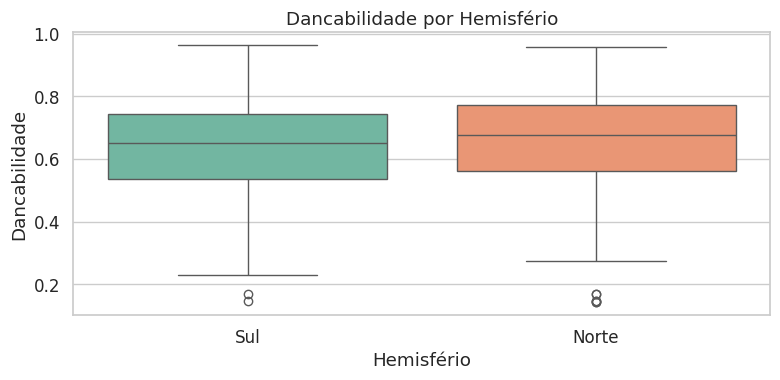

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


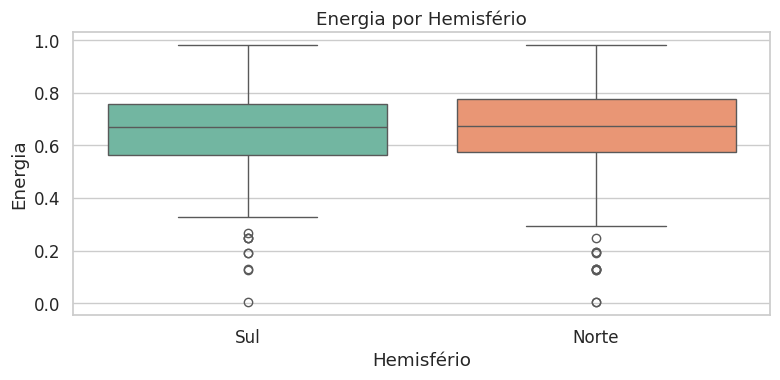

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


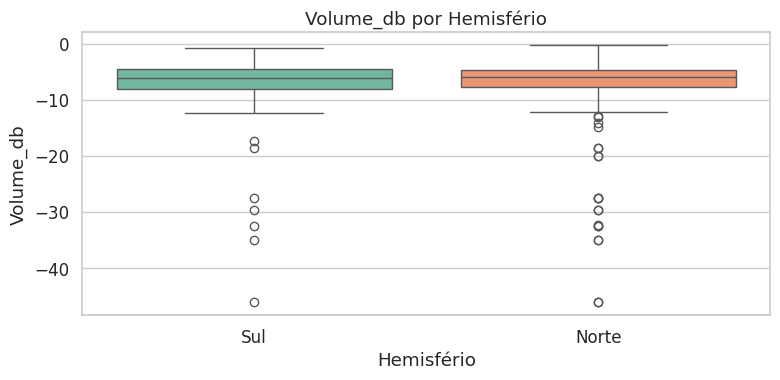

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


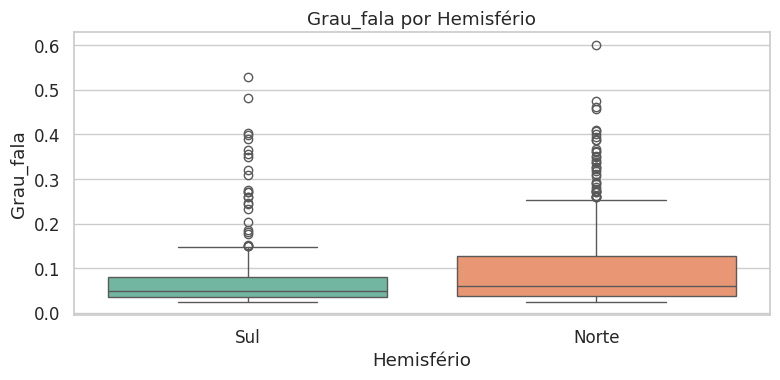

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


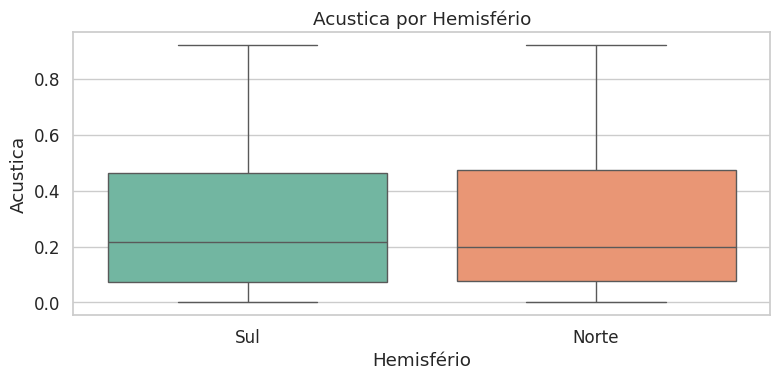

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


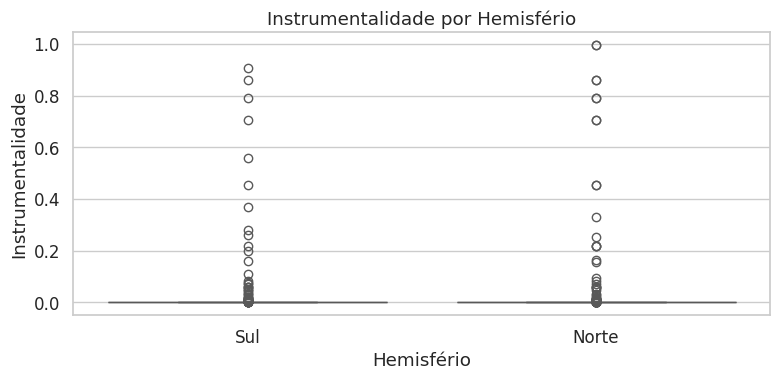

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


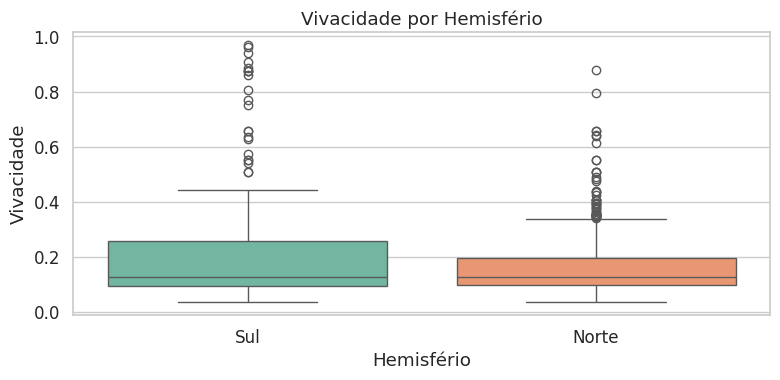

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


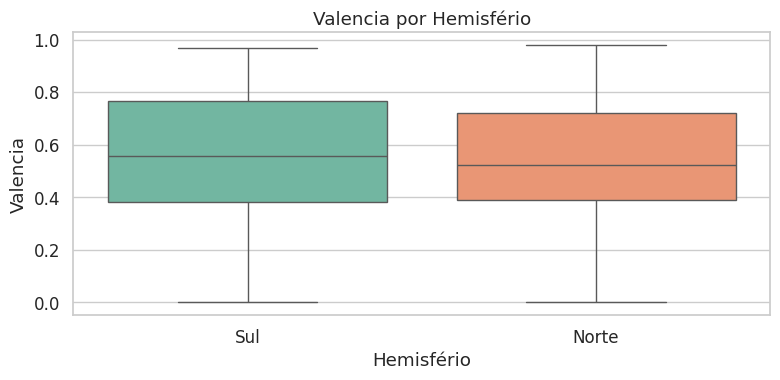

/tmp/ipython-input-2661570172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')


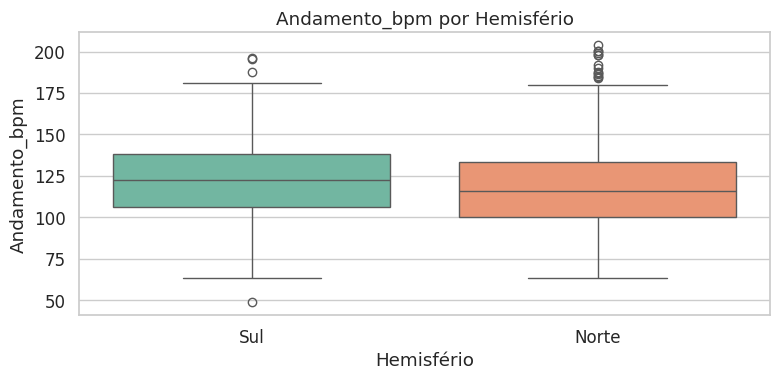

In [ ]:
for col in X.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df_paises_last, x='hemisferio', y=col, palette='Set2')
    plt.title(f'{col.capitalize()} por Hemisfério')
    plt.xlabel('Hemisfério')
    plt.ylabel(col.capitalize())
    plt.tight_layout()
    plt.show()


## Análise de correlação

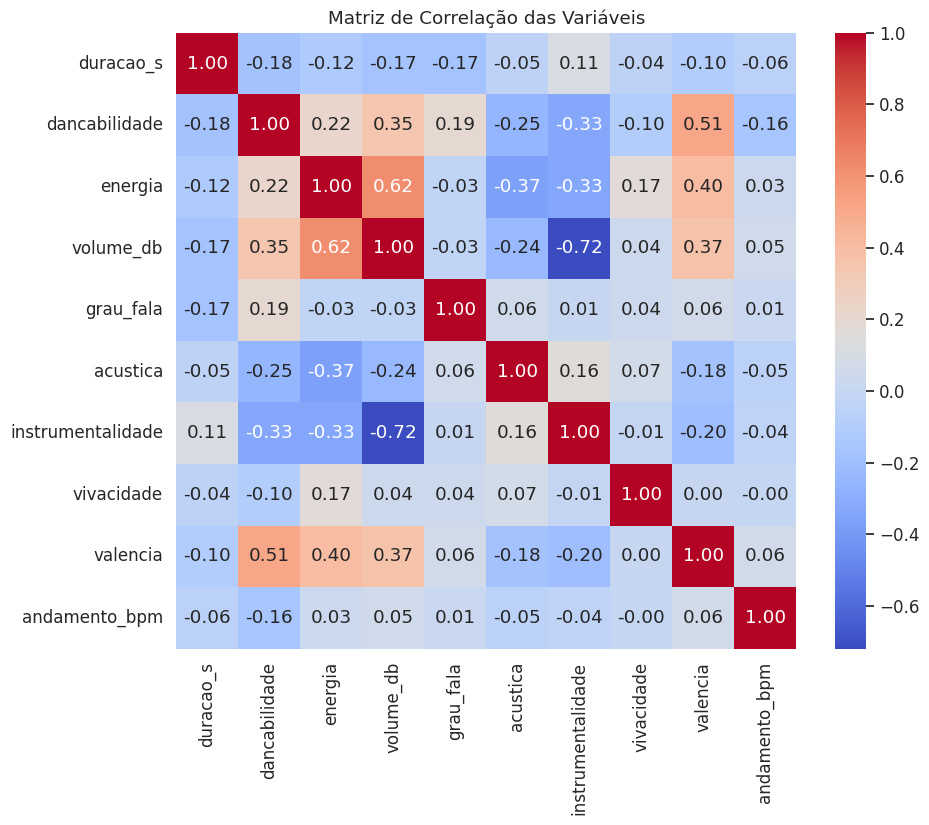

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlação das Variáveis")
plt.show()

## Treino / teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("\nTamanho treino:", X_train.shape)
print("Tamanho teste:", X_test.shape)


Tamanho treino: (490, 10)
Tamanho teste: (210, 10)


## Escalonamento (padronização das variáveis)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## VIF (multicolinearidade)

In [ ]:
vif_df = pd.DataFrame({
    "Variável": X.columns,
    "VIF": [variance_inflation_factor(X_train_scaled, i) for i in range(X_train_scaled.shape[1])]
})
print("\n--- VIF ---")
print(vif_df.sort_values(by="VIF", ascending=False).reset_index(drop=True))


--- VIF ---
            Variável       VIF
0          volume_db  3.479855
1  instrumentalidade  2.331156
2            energia  2.178126
3      dancabilidade  1.767379
4           valencia  1.654186
5           acustica  1.224870
6         vivacidade  1.097172
7          duracao_s  1.094823
8      andamento_bpm  1.085334
9          grau_fala  1.062195


## Testes de normalidade (Shapiro) por grupo

In [ ]:
norm_test = {}
for grupo in y.unique():
    norm_test[grupo] = {}
    subset = X[y == grupo]
    for col in X.columns:
        # se muito pequeno, shapiro pode falhar; amostra até 100
        n = min(100, len(subset))
        if n < 3:
            p = np.nan
        else:
            stat, p = shapiro(subset[col].dropna().sample(n, random_state=42))
        norm_test[grupo][col] = p

for g in norm_test:
    print(f"\nTeste de Shapiro para grupo {g}:")
    print(pd.Series(norm_test[g]).sort_values())

    num_cols = X.columns


Teste de Shapiro para grupo Sul:
instrumentalidade    5.225354e-20
grau_fala            7.108033e-16
vivacidade           2.599244e-13
volume_db            2.653317e-13
duracao_s            6.458027e-09
acustica             5.420814e-07
energia              1.748678e-03
valencia             4.742382e-03
dancabilidade        6.040767e-03
andamento_bpm        2.417945e-01
dtype: float64

Teste de Shapiro para grupo Norte:
instrumentalidade    1.149598e-20
volume_db            1.385407e-16
grau_fala            2.260036e-12
vivacidade           2.507305e-11
acustica             1.551035e-06
energia              3.806812e-05
andamento_bpm        1.714516e-04
dancabilidade        2.565090e-04
duracao_s            3.413024e-03
valencia             1.046924e-01
dtype: float64


## Box's M aproximado (matriz de covariância igualdade)

In [ ]:
def box_m_test(X_values, y_values):
    groups = np.unique(y_values)
    ni, Si = [], []
    for g in groups:
        Xi = X_values[y_values == g]
        ni.append(Xi.shape[0])
        # cov com bias=True (dividir por n)
        Si.append(np.cov(Xi, rowvar=False, bias=True))
    pooled = sum([(ni[i]-1)*Si[i] for i in range(len(groups))]) / (sum(ni)-len(groups))

    # usar slogdet para robustez numérica
    term1 = 0.0
    for i in range(len(groups)):
        sign_i, logdet_i = la.slogdet(Si[i])
        term1 += (ni[i]-1) * logdet_i
    sign_p, logdet_p = la.slogdet(pooled)
    m_stat = term1 - (sum(ni)-len(groups)) * logdet_p
    return m_stat

# Precisamos de arrays NumPy alinhados:
X_np = X.values
y_np = y.values
try:
    boxm = box_m_test(X_np, y_np)
    print("\nEstatística aproximada de Box’s M:", boxm)
except Exception as e:
    print("\nBox's M não pôde ser calculado com estabilidade numérica:", e)


Estatística aproximada de Box’s M: -273.89873925035954


## Treinamento do modelo

In [ ]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_scaled, y_train)

y_pred = lda.predict(X_test_scaled)

## Validação cruzada

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(lda, X_train_scaled, y_train, cv=cv, scoring='accuracy')
print("\nAcurácias por fold (LDA):", np.round(cv_scores, 4))
print("Acurácia média (CV):", np.round(cv_scores.mean(), 4))


Acurácias por fold (LDA): [0.6224 0.5816 0.6224 0.7041 0.7143]
Acurácia média (CV): 0.649


## Avaliação do conjunto de teste


Acurácia no teste (LDA): 0.6476190476190476

Relatório de classificação (LDA):
               precision    recall  f1-score   support

       Norte     0.6597    0.9333    0.7730       135
         Sul     0.5263    0.1333    0.2128        75

    accuracy                         0.6476       210
   macro avg     0.5930    0.5333    0.4929       210
weighted avg     0.6121    0.6476    0.5729       210



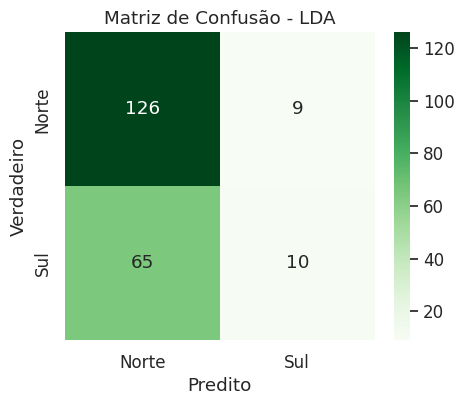

In [ ]:
print("\nAcurácia no teste (LDA):", accuracy_score(y_test, y_pred))
print("\nRelatório de classificação (LDA):\n", classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred, labels=lda.classes_)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=lda.classes_, yticklabels=lda.classes_)
plt.xlabel('Predito')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão - LDA')
plt.show()

## Curva ROC e AUC

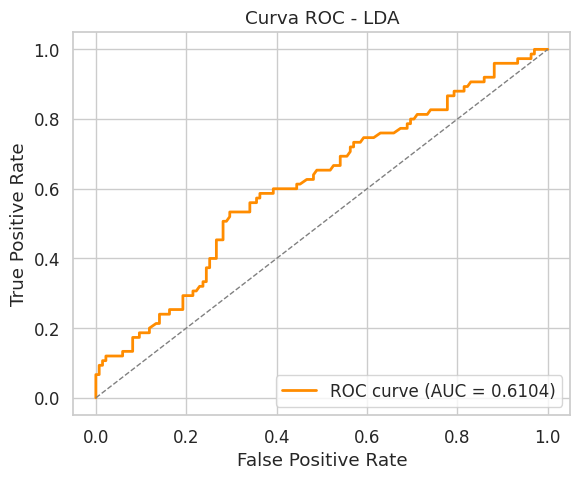

In [ ]:
if len(lda.classes_) == 2:
    y_prob = lda.predict_proba(X_test_scaled)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=lda.classes_[1])
    roc_auc = calc_auc(fpr, tpr)

    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Curva ROC - LDA')
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

else:
    y_bin = pd.get_dummies(y_test)
    y_score = lda.predict_proba(X_test_scaled)
    auc_macro = roc_auc_score(y_bin, y_score, multi_class='ovr', average='macro')
    auc_weighted = roc_auc_score(y_bin, y_score, multi_class='ovr', average='weighted')

    print(f"AUC macro (multiclasse): {auc_macro:.4f}")
    print(f"AUC weighted (multiclasse): {auc_weighted:.4f}")


## Coeficientes das funções discriminantes

In [ ]:
coef_df = pd.DataFrame(lda.coef_.T, index=X.columns, columns=[f'LD{i+1}' for i in range(lda.coef_.shape[0])])
print("\n--- Coeficientes LDA ---")
display(coef_df)


--- Coeficientes LDA ---


,LD1
duracao_s,0.358217
dancabilidade,0.078915
energia,-0.247488
volume_db,0.275629
grau_fala,-0.196470
acustica,0.090012
instrumentalidade,0.189847
vivacidade,0.386257
valencia,0.150696
andamento_bpm,0.161332


## Projeção

/tmp/ipython-input-448206658.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_scores, x='hemisferio', y=col, palette='Set2')


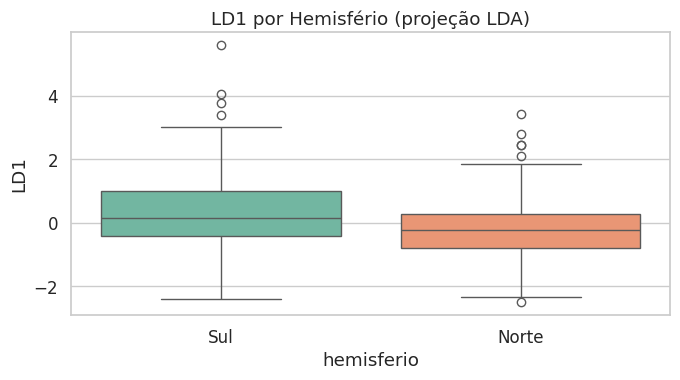

In [ ]:
X_train_lda = lda.transform(X_train_scaled)
ld_cols = [f'LD{i+1}' for i in range(X_train_lda.shape[1])]
df_scores = pd.DataFrame(X_train_lda, columns=ld_cols, index=X_train.index)
df_scores['hemisferio'] = y_train.values

for col in ld_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=df_scores, x='hemisferio', y=col, palette='Set2')
    plt.title(f'{col} por Hemisfério (projeção LDA)')
    plt.tight_layout()
    plt.show()

## Casos de alta confiança e erro

In [ ]:
y_pred_proba = lda.predict_proba(X_test_scaled)
probabilidades = pd.DataFrame(y_pred_proba, columns=lda.classes_)
probabilidades['predito'] = y_pred
probabilidades['verdadeiro'] = y_test.values

alto_erro = probabilidades[
    (probabilidades['predito'] != probabilidades['verdadeiro']) &
    (probabilidades[lda.classes_].max(axis=1) > 0.8)
]
print("\n--- Casos com alta confiança e erro ---")
display(alto_erro.head())


--- Casos com alta confiança e erro ---


,Norte,Sul,predito,verdadeiro
130,0.842960,0.157040,Norte,Sul
150,0.850049,0.149951,Norte,Sul
208,0.822503,0.177497,Norte,Sul


# Análise Fatorial

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 1.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor-analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42655 sha256=5cd310c1c06c831f447f5feb8c6aab4dda812117c3eabd49c6b2e463b411c856
  Stored in directory: /root/.cache/pip/wheels/a2/af/06/f4d4ed4d9d714fda437fb1583629417319603c2266e7b233cc
Successfully built factor-analyzer
ANÁLISE FATORIAL - COM ESCALONAMENTO (USANDO CORRELAÇÃO)

Variáveis incluídas:
['duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala', 'acustica', 'instrumentalidade', 'valencia']

ESTATÍSTICAS DESCRITIVAS
       duracao_s  dancabilidade  energia  volume_db  grau_fala  acustica  \
count    700.000        700.000  700.000    700.000    700.000   700.000   
mean       0.000         -0.000   -0.000     -0.000      0.000     0.000   
std        1.001         

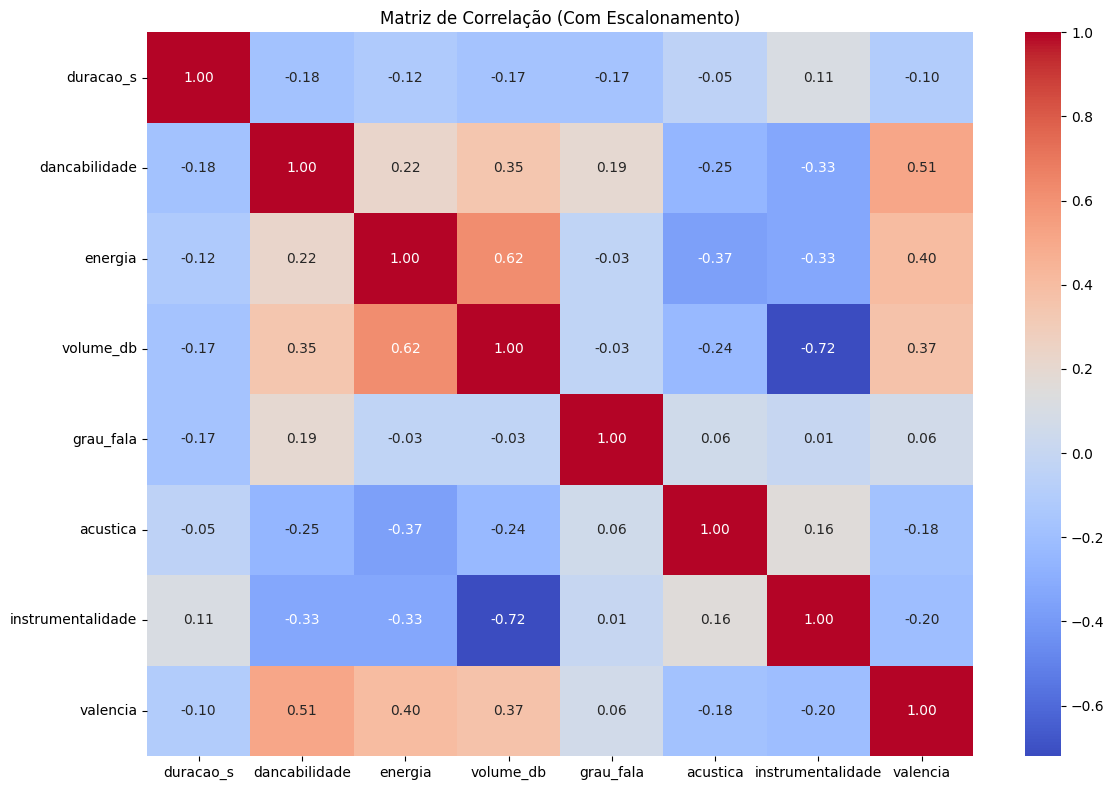


TESTES DE ADEQUAÇÃO
Teste de Bartlett: Chi² = 1530.79, p = 0.00000
KMO Overall = 0.6385

DETERMINAÇÃO DO NÚMERO DE FATORES (PCA CORRELAÇÃO)
Autovalores:
[np.float64(2.858), np.float64(1.284), np.float64(1.037), np.float64(0.82), np.float64(0.796), np.float64(0.677), np.float64(0.348), np.float64(0.191)]


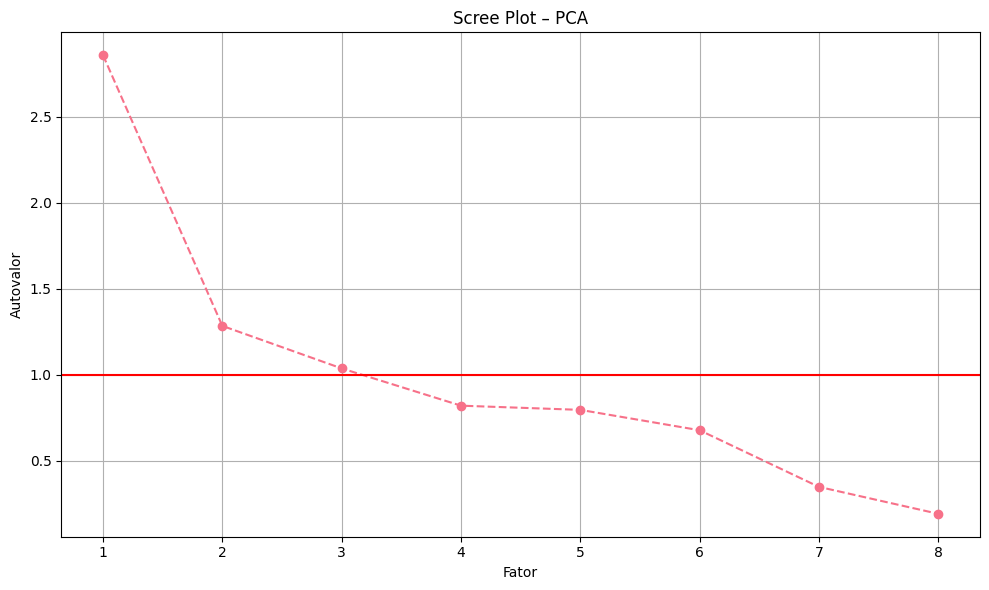


Número de fatores pelo critério de Kaiser: 3

ANÁLISE FATORIAL (CORRELAÇÃO + VARIMAX)

CARGAS FATORIAIS:
                   Fator_1  Fator_2  Fator_3
duracao_s           -0.149   -0.044   -0.172
dancabilidade        0.204    0.336    0.919
energia              0.314    0.832   -0.104
volume_db            0.912    0.410    0.032
grau_fala           -0.014   -0.041    0.244
acustica            -0.085   -0.407   -0.061
instrumentalidade   -0.710   -0.154   -0.129
valencia             0.166    0.450    0.348

COMUNALIDADES:
            Variável  Comunalidade
0          duracao_s         0.054
1      dancabilidade         0.999
2            energia         0.802
3          volume_db         1.002
4          grau_fala         0.061
5           acustica         0.177
6  instrumentalidade         0.545
7           valencia         0.351


/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


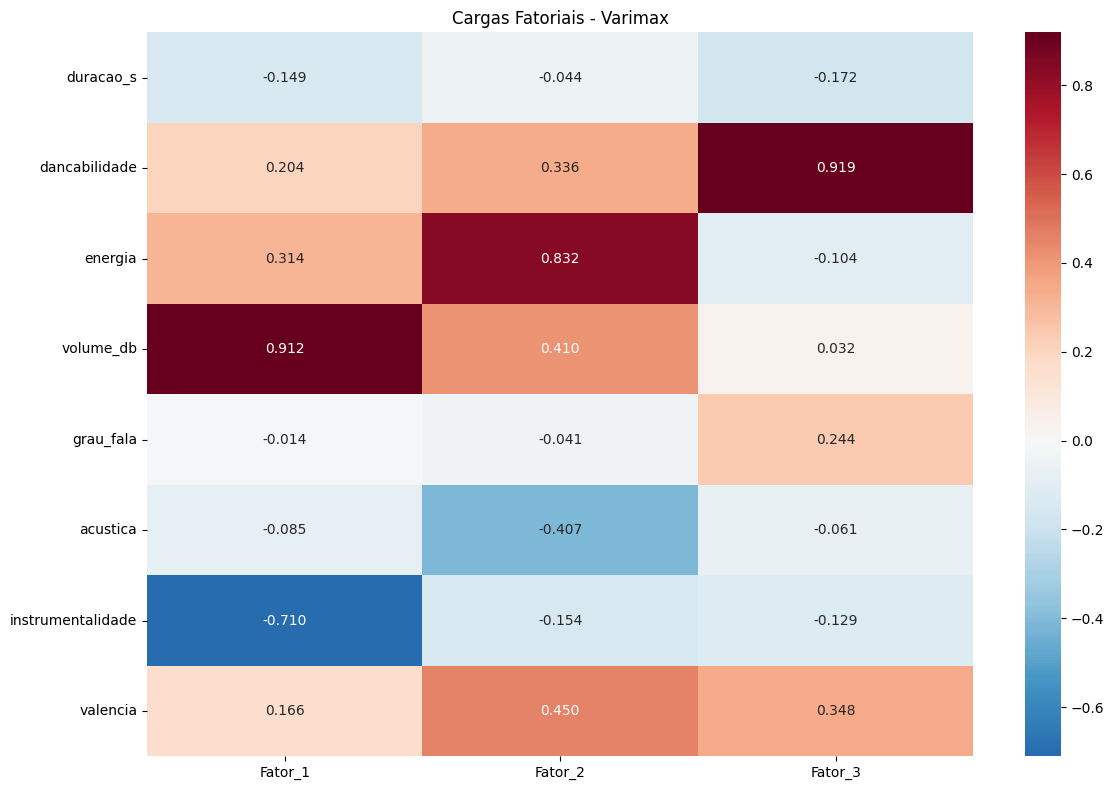

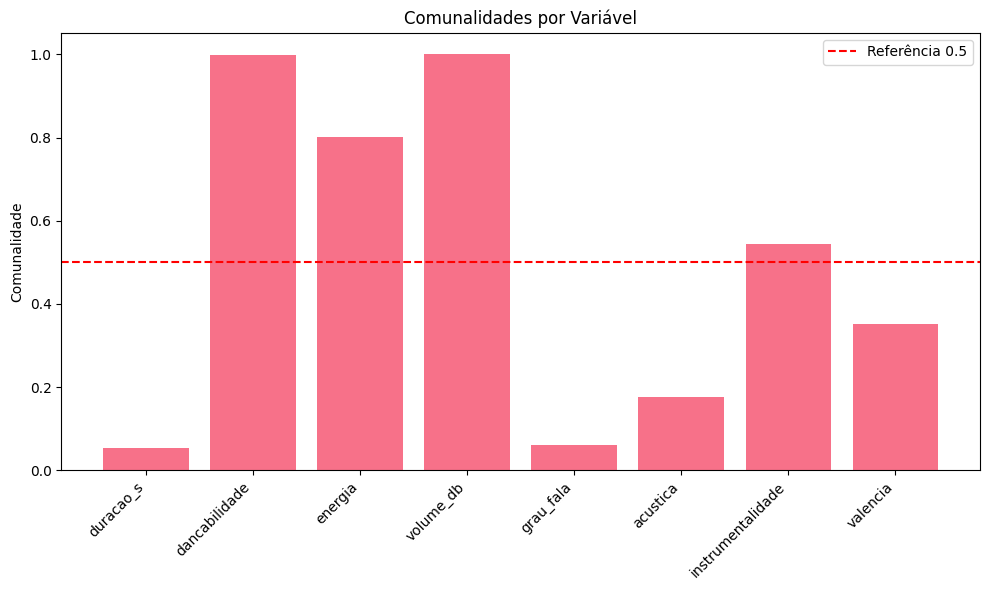


SCORES FATORIAIS (primeiras 5 linhas):
   Score_Fator_1  Score_Fator_2  Score_Fator_3
0         -0.171         -0.519         -1.956
1         -0.458         -0.797         -0.517
2          0.026         -0.255          1.075
3         -1.166          1.037          0.399
4         -0.589         -0.547          0.893

RESUMO FINAL
Método: FactorAnalyzer (MINRES, Varimax, usando Correlação)
Número de Fatores: 3
KMO: 0.638
Teste de Bartlett p: 0.00000

Comunalidade média: 0.499

→ Fator_1: principais variáveis = ['volume_db', 'instrumentalidade', 'energia']

→ Fator_2: principais variáveis = ['energia', 'valencia', 'volume_db']

→ Fator_3: principais variáveis = ['dancabilidade', 'valencia', 'grau_fala']

GRÁFICO DE SCORES MÉDIOS POR CONTINENTE


/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


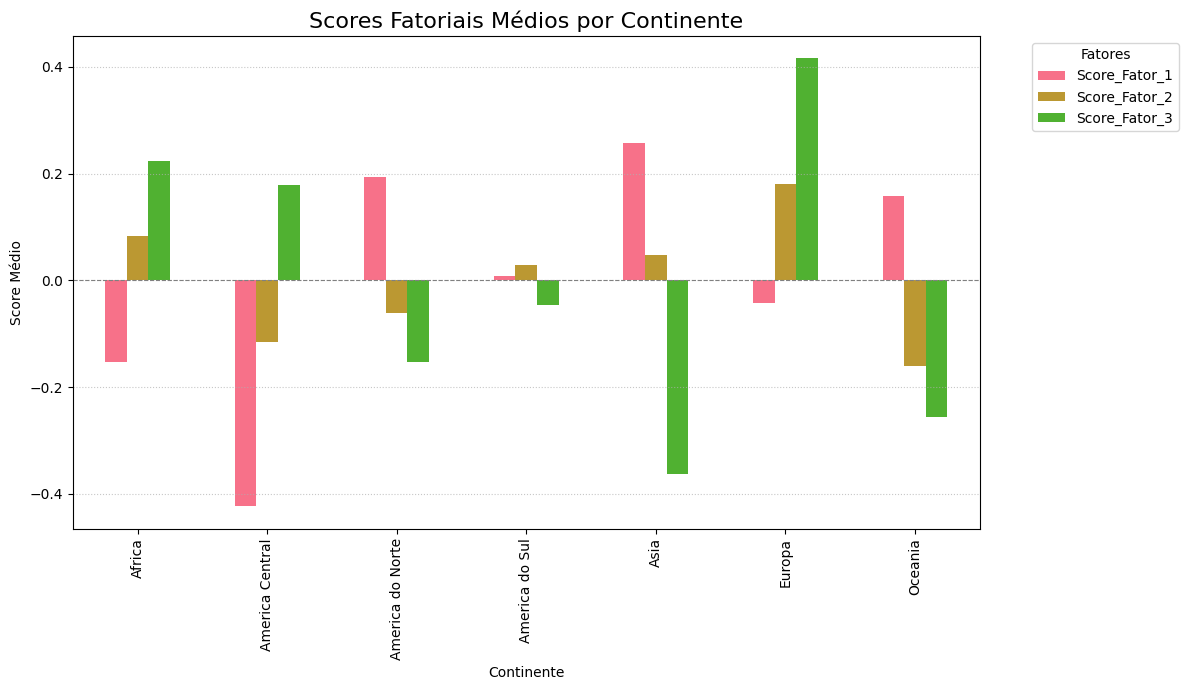


Tabela: Médias dos Scores Fatoriais por Continente:


,Score_Fator_1,Score_Fator_2,Score_Fator_3
continente,,,
Africa,-0.152,0.083,0.224
America Central,-0.423,-0.116,0.180
America do Norte,0.193,-0.062,-0.154
America do Sul,0.009,0.028,-0.047
Asia,0.257,0.047,-0.363
Europa,-0.042,0.180,0.416
Oceania,0.158,-0.161,-0.256


In [ ]:
# ===============================================================
# ANÁLISE FATORIAL COMPLETA (COM ESCALONAMENTO Z-SCORE)
# ===============================================================

!pip install factor-analyzer

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.style.use('default')
sns.set_palette("husl")

print("=" * 70)
print("ANÁLISE FATORIAL - COM ESCALONAMENTO (USANDO CORRELAÇÃO)")
print("=" * 70)

# ===============================================================
# 1. Seleção das variáveis numéricas
# ===============================================================

variaveis = [
    'duracao_s', 'dancabilidade', 'energia', 'volume_db',
    'grau_fala', 'acustica', 'instrumentalidade',
    'valencia'
]

df_numerico = df_paises_last[variaveis].copy()

print("\nVariáveis incluídas:")
print(variaveis)

# ===============================================================
# 2. ESCALONAMENTO (PADRONIZAÇÃO Z-SCORE)
# ===============================================================

scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_numerico),
    columns=variaveis
)

# ===============================================================
# 3. Estatísticas Descritivas (APÓS ESCALONAMENTO)
# ===============================================================

print("\n" + "=" * 60)
print("ESTATÍSTICAS DESCRITIVAS")
print("=" * 60)
print(df_scaled.describe().round(3))

# ===============================================================
# 4. Matriz de Correlação
# ===============================================================

corr_matrix = df_scaled.corr()

print("\n" + "=" * 60)
print("MATRIZ DE CORRELAÇÃO")
print("=" * 60)
print(corr_matrix.round(3))

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlação (Com Escalonamento)")
plt.tight_layout()
plt.show()

# ===============================================================
# 5. Testes de Adequação: Bartlett e KMO
# ===============================================================

print("\n" + "=" * 60)
print("TESTES DE ADEQUAÇÃO")
print("=" * 60)

chi, p_value = calculate_bartlett_sphericity(df_scaled)
print(f"Teste de Bartlett: Chi² = {chi:.2f}, p = {p_value:.5f}")

kmo_all, kmo_model = calculate_kmo(df_scaled)
print(f"KMO Overall = {kmo_model:.4f}")

# ===============================================================
# 6. Determinação de Número de Fatores (PCA com correlação)
# ===============================================================

print("\n" + "=" * 60)
print("DETERMINAÇÃO DO NÚMERO DE FATORES (PCA CORRELAÇÃO)")
print("=" * 60)

pca = PCA()
pca.fit(df_scaled)  # agora usa a matriz de correlação

autovalores = pca.explained_variance_

print("Autovalores:")
print([round(x, 3) for x in autovalores])

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(autovalores) + 1), autovalores, 'o--')
plt.axhline(1, color='red', label='Autovalor = 1')
plt.title("Scree Plot – PCA")
plt.xlabel("Fator")
plt.ylabel("Autovalor")
plt.grid(True)
plt.tight_layout()
plt.show()

n_fatores = sum(autovalores > 1)
print(f"\nNúmero de fatores pelo critério de Kaiser: {n_fatores}")

# ===============================================================
# 7. ANÁLISE FATORIAL (agora com matriz de correlação)
# ===============================================================

print("\n" + "=" * 60)
print("ANÁLISE FATORIAL (CORRELAÇÃO + VARIMAX)")
print("=" * 60)

fa = FactorAnalyzer(
    n_factors=n_fatores,
    rotation="varimax",
    method="minres"
)

fa.fit(df_scaled)

# Cargas fatoriais
cargas = pd.DataFrame(
    fa.loadings_,
    index=variaveis,
    columns=[f"Fator_{i+1}" for i in range(n_fatores)]
)

print("\nCARGAS FATORIAIS:")
print(cargas.round(3))

# Comunalidades
comunalidades = pd.DataFrame({
    "Variável": variaveis,
    "Comunalidade": fa.get_communalities()
})

print("\nCOMUNALIDADES:")
print(comunalidades.round(3))

# ===============================================================
# 8. Heatmap das Cargas
# ===============================================================

plt.figure(figsize=(12, 8))
sns.heatmap(cargas, annot=True, cmap="RdBu_r", fmt=".3f", center=0)
plt.title("Cargas Fatoriais - Varimax")
plt.tight_layout()
plt.show()

# Gráfico das Comunalidades
plt.figure(figsize=(10, 6))
bars = plt.bar(comunalidades["Variável"], comunalidades["Comunalidade"])
plt.axhline(0.5, color='red', linestyle='--', label='Referência 0.5')
plt.title("Comunalidades por Variável")
plt.ylabel("Comunalidade")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

# ===============================================================
# 9. Scores Fatoriais (com escalonamento)
# ===============================================================

scores = fa.transform(df_scaled)

df_scores = df_scaled.copy()
for i in range(n_fatores):
    df_scores[f"Score_Fator_{i+1}"] = scores[:, i]

print("\nSCORES FATORIAIS (primeiras 5 linhas):")
print(df_scores[[f"Score_Fator_{i+1}" for i in range(n_fatores)]].head().round(3))

# ===============================================================
# 10. Resumo Final
# ===============================================================

print("\n" + "=" * 70)
print("RESUMO FINAL")
print("=" * 70)
print(f"Método: FactorAnalyzer (MINRES, Varimax, usando Correlação)")
print(f"Número de Fatores: {n_fatores}")
print(f"KMO: {kmo_model:.3f}")
print(f"Teste de Bartlett p: {p_value:.5f}")

print("\nComunalidade média:", round(comunalidades["Comunalidade"].mean(), 3))

for i in range(n_fatores):
    fator = f"Fator_{i+1}"
    top_vars = cargas[fator].abs().sort_values(ascending=False).head(3).index.tolist()
    print(f"\n→ {fator}: principais variáveis = {top_vars}")

# ===============================================================
# 11. GRÁFICO DE SCORES MÉDIOS POR CONTINENTE
# ===============================================================

print("\n" + "=" * 60)
print("GRÁFICO DE SCORES MÉDIOS POR CONTINENTE")
print("=" * 60)

# 1. Cria um DataFrame com os scores e o índice correto
# (scores vem da Seção 7, n_fatores da Seção 6)
df_scores_finais = pd.DataFrame(
    scores,
    columns=[f"Score_Fator_{i+1}" for i in range(n_fatores)],
    index=df_scaled.index  # Usa o índice do df_scaled para garantir alinhamento
)

# 2. Junta os scores com o DataFrame original (que tem 'continente')
# Usamos o índice para juntar (df_paises_last vem da sua célula de carregamento)
df_plot = df_paises_last.join(df_scores_finais)

# 3. Agrupa os scores médios por continente
# (Isso irá gerar os dados para o seu gráfico)
scores_af_continente = df_plot.groupby('continente')[
    [f"Score_Fator_{i+1}" for i in range(n_fatores)]
].mean()

# 4. Plota o gráfico de barras (ESTE É O GRÁFICO PARA O SLIDE 12)
scores_af_continente.plot(
    kind='bar',
    figsize=(12, 7)
)

plt.title('Scores Fatoriais Médios por Continente', fontsize=16)
plt.ylabel('Score Médio')
plt.xlabel('Continente')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.legend(title='Fatores', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

print("\nTabela: Médias dos Scores Fatoriais por Continente:")
display(scores_af_continente.round(3))


# Análise de componentes principais (PCA)

ANÁLISE FATORIAL - DATASET DE MÚSICAS

Variáveis disponíveis para análise: ['duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala', 'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm']

ESTATÍSTICAS DESCRITIVAS
        duracao_s  dancabilidade     energia   volume_db   grau_fala  \
count  700.000000     700.000000  700.000000  700.000000  700.000000   
mean   210.022341       0.648514    0.659341   -6.952097    0.091714   
std     63.256710       0.156964    0.164126    5.059287    0.088876   
min     70.400000       0.142000    0.003320  -46.113000    0.023600   
25%    170.971750       0.554000    0.572250   -7.787750    0.036800   
50%    196.561000       0.663000    0.674500   -5.923500    0.055600   
75%    235.111750       0.757250    0.773500   -4.507250    0.112000   
max    586.075000       0.963000    0.981000   -0.236000    0.600000   

         acustica  instrumentalidade  vivacidade    valencia  andamento_bpm  
count  700.000000         70

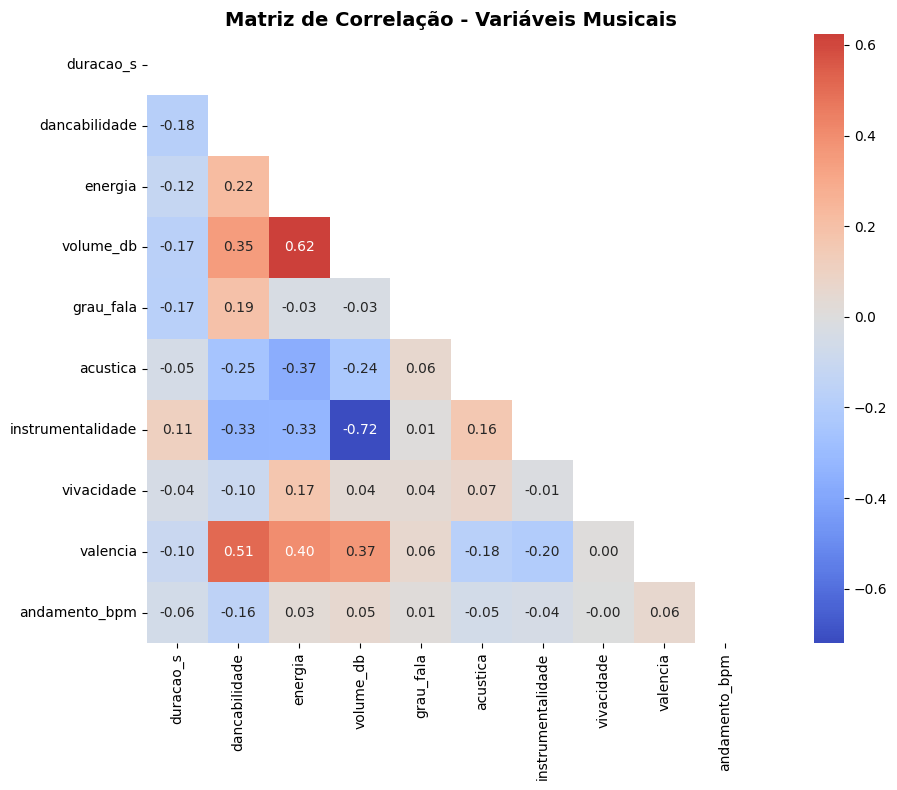


TESTES DE ADEQUAÇÃO
Teste de Esfericidade de Bartlett:
Chi-Quadrado: 1640.32
p-valor: 0.0000
Resultado: Adequado

Medida KMO (Overall): 0.6061
Interpretação KMO:
→ Medíocre

DETERMINAÇÃO DO NÚMERO DE FATORES
Autovalores: ['2.861', '1.292', '1.177', '1.038', '0.978', '0.796', '0.787', '0.582', '0.316', '0.188']


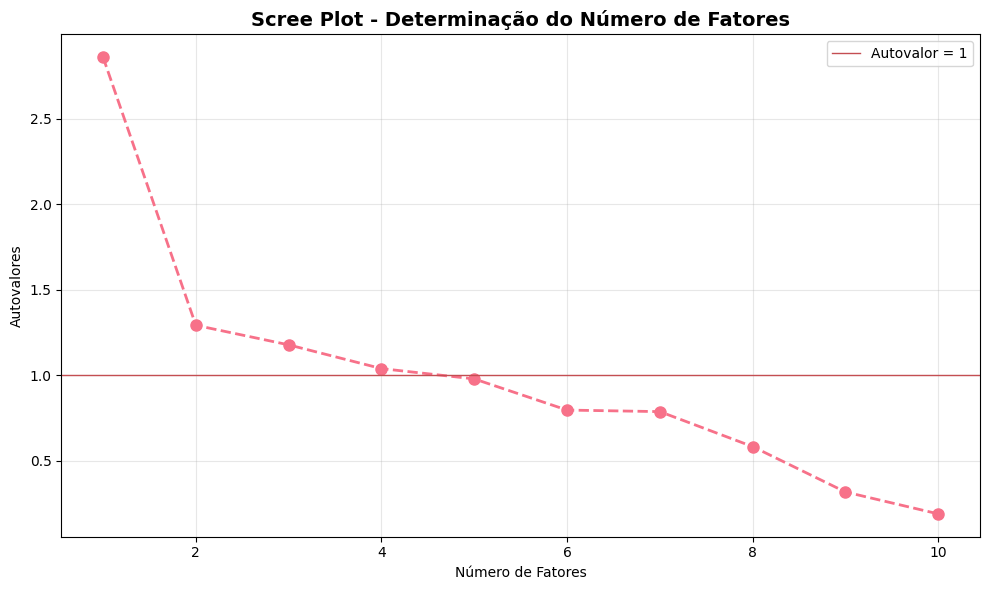


Critério de Kaiser (autovalor > 1): 4 fatores

ANÁLISE PARALELA (Parallel Analysis)


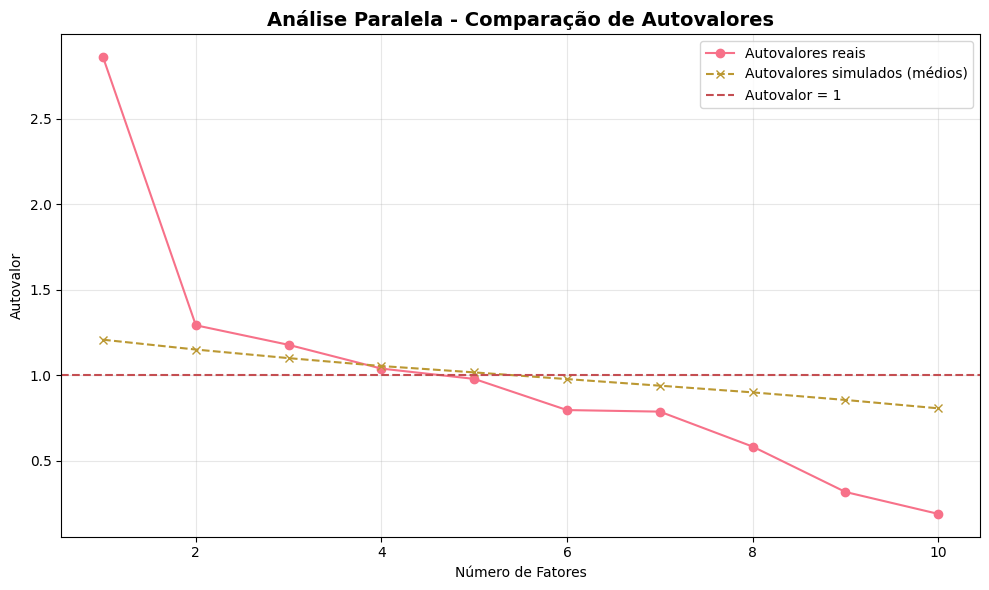

Número de fatores sugeridos pela Análise Paralela: 3

Variância Explicada:
Fator 1: 0.286 (0.286 cumulativa)
Fator 2: 0.129 (0.415 cumulativa)
Fator 3: 0.118 (0.532 cumulativa)
Fator 4: 0.104 (0.636 cumulativa)
Fator 5: 0.098 (0.734 cumulativa)
Fator 6: 0.079 (0.813 cumulativa)
Fator 7: 0.079 (0.892 cumulativa)
Fator 8: 0.058 (0.950 cumulativa)
Fator 9: 0.032 (0.981 cumulativa)
Fator 10: 0.019 (1.000 cumulativa)

ANÁLISE FATORIAL - ROTAÇÃO VARIMAX
MATRIZ DE CARGAS FATORIAIS (Varimax):
                   Fator_1  Fator_2  Fator_3  Fator_4
duracao_s           -0.023   -0.127   -0.116   -0.426
dancabilidade        0.536    0.268   -0.653    0.480
energia              0.850    0.248    0.465    0.023
volume_db            0.371    0.908    0.177    0.059
grau_fala           -0.021   -0.042   -0.021    0.410
acustica            -0.428   -0.120    0.084    0.147
instrumentalidade   -0.175   -0.716    0.005   -0.057
vivacidade           0.040   -0.022    0.254    0.098
valencia             0.4

/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
# Instalar o pacote necessário
!pip install factor-analyzer

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.preprocessing import StandardScaler
import scipy.stats as stats

# Configurações visuais
plt.style.use('default')
sns.set_palette("husl")

print("=" * 60)
print("ANÁLISE FATORIAL - DATASET DE MÚSICAS")
print("=" * 60)

# Selecionar apenas variáveis numéricas para análise fatorial
variaveis_numericas = ['duracao_s', 'dancabilidade', 'energia', 'volume_db',
                       'grau_fala', 'acustica', 'instrumentalidade',
                       'vivacidade', 'valencia', 'andamento_bpm']

# Verificar se todas as variáveis existem no dataset
variaveis_disponiveis = [var for var in variaveis_numericas if var in df_paises_last.columns]
print(f"\nVariáveis disponíveis para análise: {variaveis_disponiveis}")

df_numerico = df_paises_last[variaveis_disponiveis].copy()

# 2. ESTATÍSTICAS DESCRITIVAS
print("\n" + "=" * 60)
print("ESTATÍSTICAS DESCRITIVAS")
print("=" * 60)
print(df_numerico.describe())

# 3. MATRIZ DE CORRELAÇÃO
print("\n" + "=" * 60)
print("MATRIZ DE CORRELAÇÃO")
print("=" * 60)

corr_matrix = df_numerico.corr()
plt.figure(figsize=(12, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.2f')
plt.title('Matriz de Correlação - Variáveis Musicais', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. TESTES DE ADEQUAÇÃO DA ANÁLISE FATORIAL
print("\n" + "=" * 60)
print("TESTES DE ADEQUAÇÃO")
print("=" * 60)

scaler = StandardScaler()
df_numerico_scaled = pd.DataFrame(
    scaler.fit_transform(df_numerico),
    columns=df_numerico.columns,
    index=df_numerico.index
)

# Teste de Esfericidade de Bartlett
try:
    chi_square, p_value = calculate_bartlett_sphericity(df_numerico_scaled)
    print(f"Teste de Esfericidade de Bartlett:")
    print(f"Chi-Quadrado: {chi_square:.2f}")
    print(f"p-valor: {p_value:.4f}")
    print(f"Resultado: {'Adequado' if p_value < 0.05 else 'Não Adequado'}")
except Exception as e:
    print(f"Erro no teste de Bartlett: {e}")
    # Calcular manualmente
    from scipy.stats import chi2
    corr_matrix = df_numerico_scaled.corr()
    n = len(df_numerico_scaled)
    p = len(variaveis_disponiveis)
    chi_square = -((n - 1) - (2 * p + 5) / 6) * np.log(np.linalg.det(corr_matrix))
    df = p * (p - 1) / 2
    p_value = 1 - chi2.cdf(chi_square, df)
    print(f"Teste de Esfericidade de Bartlett (cálculo manual):")
    print(f"Chi-Quadrado: {chi_square:.2f}")
    print(f"p-valor: {p_value:.4f}")
    print(f"Resultado: {'Adequado' if p_value < 0.05 else 'Não Adequado'}")

# Medida de Adequação da Amostra (KMO)
try:
    kmo_all, kmo_model = calculate_kmo(df_numerico_scaled)
    print(f"\nMedida KMO (Overall): {kmo_model:.4f}")
except Exception as e:
    print(f"Erro no cálculo KMO: {e}")
    # Estimativa simples baseada na matriz de correlação
    corr_matrix = df_numerico_scaled.corr()
    anti_image = corr_matrix - np.linalg.inv(corr_matrix)
    kmo_model = np.sum(corr_matrix.values**2) / (np.sum(corr_matrix.values**2) + np.sum(anti_image.values**2))
    print(f"Medida KMO (estimada): {kmo_model:.4f}")

print("Interpretação KMO:")
kmo_interpretation = {
    (0.9, 1.0): "Maravilhoso",
    (0.8, 0.9): "Meritório",
    (0.7, 0.8): "Médio",
    (0.6, 0.7): "Medíocre",
    (0.5, 0.6): "Ruim",
    (0.0, 0.5): "Inaceitável"
}

for range_val, interpretation in kmo_interpretation.items():
    if range_val[0] <= kmo_model < range_val[1]:
        print(f"→ {interpretation}")
        break

# 5. DETERMINAÇÃO DO NÚMERO DE FATORES
print("\n" + "=" * 60)
print("DETERMINAÇÃO DO NÚMERO DE FATORES")
print("=" * 60)

# Usando PCA para determinar número de fatores (corrigido: usa dados escalonados)
pca = PCA()
pca.fit(df_numerico_scaled)

# Autovalores
ev = pca.explained_variance_
print("Autovalores:", [f"{x:.3f}" for x in ev])

# Scree Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(ev) + 1), ev, marker='o', linestyle='--', linewidth=2, markersize=8)
plt.axhline(y=1, color='r', linestyle='-', linewidth=1, label='Autovalor = 1')
plt.title('Scree Plot - Determinação do Número de Fatores', fontsize=14, fontweight='bold')
plt.xlabel('Número de Fatores')
plt.ylabel('Autovalores')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Critério de Kaiser (autovalor > 1)
n_fatores_kaiser = sum(ev > 1)
print(f"\nCritério de Kaiser (autovalor > 1): {n_fatores_kaiser} fatores")

# --- ANÁLISE PARALELA ---
print("\n" + "=" * 60)
print("ANÁLISE PARALELA (Parallel Analysis)")
print("=" * 60)

n_simulacoes = 100
n_obs, n_vars = df_numerico_scaled.shape
eigenvalues_real = ev
eigenvalues_random = np.zeros((n_simulacoes, n_vars))

for i in range(n_simulacoes):
    random_data = np.random.normal(size=(n_obs, n_vars))
    pca_random = PCA()
    pca_random.fit(random_data)
    eigenvalues_random[i, :] = pca_random.explained_variance_

mean_eigen_random = eigenvalues_random.mean(axis=0)

plt.figure(figsize=(10, 6))
plt.plot(range(1, n_vars + 1), eigenvalues_real, marker='o', label='Autovalores reais')
plt.plot(range(1, n_vars + 1), mean_eigen_random, marker='x', linestyle='--', label='Autovalores simulados (médios)')
plt.axhline(y=1, color='r', linestyle='--', label='Autovalor = 1')
plt.title('Análise Paralela - Comparação de Autovalores', fontsize=14, fontweight='bold')
plt.xlabel('Número de Fatores')
plt.ylabel('Autovalor')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

n_fatores_parallel = np.sum(eigenvalues_real > mean_eigen_random)
print(f"Número de fatores sugeridos pela Análise Paralela: {n_fatores_parallel}")
print("=" * 60)
# --------------------------------------

# Variação explicada
variancia_explicada = pca.explained_variance_ratio_
variancia_cumulativa = np.cumsum(variancia_explicada)

print(f"\nVariância Explicada:")
for i, (var, cum_var) in enumerate(zip(variancia_explicada, variancia_cumulativa)):
    print(f"Fator {i+1}: {var:.3f} ({cum_var:.3f} cumulativa)")

# 6. ANÁLISE FATORIAL PRINCIPAL (corrigido: usa df_numerico_scaled)
print("\n" + "=" * 60)
print("ANÁLISE FATORIAL - ROTAÇÃO VARIMAX")
print("=" * 60)

try:
    fa_varimax = FactorAnalyzer(n_factors=n_fatores_kaiser, rotation='varimax', method='minres')
    fa_varimax.fit(df_numerico_scaled)

    # Cargas fatoriais
    cargas = pd.DataFrame(fa_varimax.loadings_,
                         index=variaveis_disponiveis,
                         columns=[f'Fator_{i+1}' for i in range(n_fatores_kaiser)])

    print("MATRIZ DE CARGAS FATORIAIS (Varimax):")
    print(cargas.round(3))

    # Comunalidades
    comunalidades = pd.DataFrame({
        'Variável': variaveis_disponiveis,
        'Comunalidade': fa_varimax.get_communalities()
    })

    # Scores fatoriais
    scores_fatoriais = fa_varimax.transform(df_numerico_scaled)

    method_used = "FactorAnalyzer"

except Exception as e:
    print(f"Usando PCA como alternativa: {e}")
    pca_rotated = PCA(n_components=n_fatores_kaiser)
    scores_fatoriais = pca_rotated.fit_transform(df_numerico_scaled)

    cargas = pd.DataFrame(pca_rotated.components_.T,
                         index=variaveis_disponiveis,
                         columns=[f'Fator_{i+1}' for i in range(n_fatores_kaiser)])

    print("MATRIZ DE COMPONENTES (PCA):")
    print(cargas.round(3))

    comunalidades = pd.DataFrame({
        'Variável': variaveis_disponiveis,
        'Comunalidade': (cargas ** 2).sum(axis=1)
    })

    method_used = "PCA"


In [ ]:
# Instala a biblioteca para os testes de adequação (KMO e Bartlett)
!pip install factor-analyzer

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas para PCA e Padronização
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Bibliotecas para os testes de adequação (seguindo o padrão do seu notebook)
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

# 1. Lista das colunas numéricas (como em [cite: 1304])
variaveis_numericas = [
    "duracao_s", "dancabilidade", "energia", "volume_db", "grau_fala",
    "acustica", "instrumentalidade", "vivacidade", "valencia", "andamento_bpm"
]

# 2. Cria o dataframe numérico (a partir do df_paises_last que você já carregou)
df_numerico = df_paises_last[variaveis_numericas].dropna()

# 3. Padroniza os dados (ESSENCIAL para o PCA)
scaler = StandardScaler()
dados_escalados = scaler.fit_transform(df_numerico)

# Converte de volta para DataFrame para facilitar a visualização
df_escalado = pd.DataFrame(dados_escalados, columns=variaveis_numericas, index=df_numerico.index)

print("Dados numéricos padronizados (z-score) e prontos para o PCA.")

Dados numéricos padronizados (z-score) e prontos para o PCA.


In [ ]:
# 1. Teste de Esfericidade de Bartlett
# H0: A matriz de correlação é uma matriz identidade (variáveis não se correlacionam)
# Queremos rejeitar H0 (ou seja, p-valor < 0.05)
chi_square, p_value = calculate_bartlett_sphericity(df_numerico)
print(f"--- Teste de Bartlett ---")
print(f"Chi-Quadrado: {chi_square:.2f}")
print(f"p-valor: {p_value:.4e}") # Notação científica
print(f"Resultado: {'Adequado (p < 0.05)' if p_value < 0.05 else 'Não Adequado (p >= 0.05)'}")
print("-" * 30)

# 2. Medida de Adequação da Amostra (KMO)
# Mede a proporção de variância que é compartilhada entre as variáveis
# Queremos um valor > 0.6 (idealmente > 0.7)
kmo_all, kmo_model = calculate_kmo(df_numerico)
print(f"--- Teste KMO ---")
print(f"KMO Global: {kmo_model:.3f}")
print(f"Resultado: {'Adequado (KMO > 0.6)' if kmo_model > 0.6 else 'Não Adequado (KMO <= 0.6)'}")

--- Teste de Bartlett ---
Chi-Quadrado: 1640.32
p-valor: 0.0000e+00
Resultado: Adequado (p < 0.05)
------------------------------
--- Teste KMO ---
KMO Global: 0.606
Resultado: Adequado (KMO > 0.6)


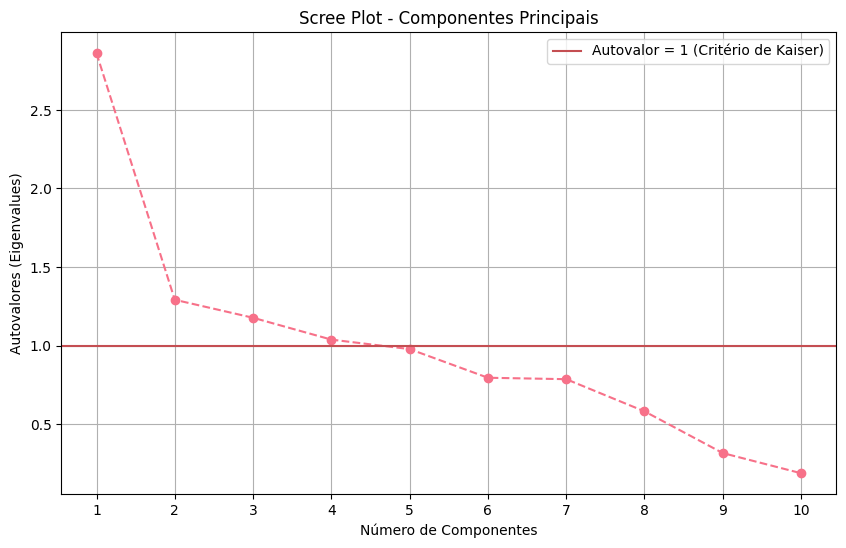


--- Variância Explicada Cumulativa ---
  1 componente(s) explicam: 28.57%
  2 componente(s) explicam: 41.46%
  3 componente(s) explicam: 53.22%
  4 componente(s) explicam: 63.59%
  5 componente(s) explicam: 73.35%
  6 componente(s) explicam: 81.30%
  7 componente(s) explicam: 89.15%
  8 componente(s) explicam: 94.96%
  9 componente(s) explicam: 98.12%
  10 componente(s) explicam: 100.00%

Número de componentes sugeridos pelo Critério de Kaiser: 4


In [ ]:
# 1. Roda o PCA
pca = PCA()
pca.fit(df_escalado) # Usa os dados padronizados

# 2. Pega os Autovalores (Eigenvalues)
autovalores = pca.explained_variance_

# 3. Gera o Scree Plot (como no seu notebook )
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(autovalores) + 1), autovalores, marker='o', linestyle='--')
plt.axhline(y=1, color='r', linestyle='-', label='Autovalor = 1 (Critério de Kaiser)')
plt.title('Scree Plot - Componentes Principais')
plt.xlabel('Número de Componentes')
plt.ylabel('Autovalores (Eigenvalues)')
plt.xticks(range(1, len(autovalores) + 1))
plt.legend()
plt.grid(True)
plt.show()

# 4. Análise de Variância Explicada (A parte "completa" do PCA)
variancia_explicada_cumulativa = np.cumsum(pca.explained_variance_ratio_)

print("\n--- Variância Explicada Cumulativa ---")
for i, v in enumerate(variancia_explicada_cumulativa):
    print(f"  {i+1} componente(s) explicam: {v:.2%}")

# 5. Decidindo o número de componentes
n_componentes_kaiser = np.sum(autovalores > 1)
print(f"\nNúmero de componentes sugeridos pelo Critério de Kaiser: {n_componentes_kaiser}")

In [ ]:
# 1. Extrai as cargas (Loadings)
# pca.components_ tem os componentes nas LINHAS, então usamos .T (transpor)
cargas_pca = pd.DataFrame(
    pca.components_.T,
    columns=[f'CP{i+1}' for i in range(len(autovalores))],
    index=variaveis_numericas
)

# 2. Mostra as cargas dos N primeiros componentes (o número que você decidiu no passo anterior)
print(f"--- Cargas (Loadings) dos {n_componentes_kaiser} primeiros componentes ---")

# Usamos .style.background_gradient para ver mais fácil os valores altos
display(cargas_pca.iloc[:, :n_componentes_kaiser].style.background_gradient(cmap='RdBu', axis=None))

--- Cargas (Loadings) dos 4 primeiros componentes ---


,CP1,CP2,CP3,CP4
duracao_s,-0.156912,-0.446884,-0.380131,-0.153927
dancabilidade,0.378266,0.392253,-0.348036,-0.068108
energia,0.435620,-0.232079,0.152098,-0.101106
volume_db,0.501717,-0.168608,0.142651,-0.040305
grau_fala,0.043035,0.643800,0.151556,0.099052
acustica,-0.267146,0.259139,0.327218,-0.187762
instrumentalidade,-0.414244,0.121419,-0.109255,0.044331
vivacidade,0.028566,-0.081086,0.619242,-0.497021
valencia,0.380269,0.172431,-0.149684,0.064614
andamento_bpm,0.023905,-0.177373,0.378212,0.813379


In [ ]:
# 1. Roda o PCA novamente, mas desta vez especificando o n° de componentes
pca_final = PCA(n_components=n_componentes_kaiser)
scores_pca = pca_final.fit_transform(df_escalado)

print(f"Novos 'scores' de PCA gerados com shape: {scores_pca.shape}")

# 2. Adiciona os novos scores ao seu dataframe original
# (Isso é muito útil para usar em outras análises, como a Regressão)
for i in range(n_componentes_kaiser):
    df_paises_last[f'CP{i+1}'] = scores_pca[:, i]

# 3. Mostra o resultado
print("\nDataFrame original com os novos Scores de PCA (CP1, CP2, etc.):")
display(df_paises_last.head())
display(df_paises_last.tail())

Novos 'scores' de PCA gerados com shape: (700, 4)

DataFrame original com os novos Scores de PCA (CP1, CP2, etc.):


,titulo_musica,artistas,pais,continente,hemisferio,data_lancamento_album,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm,CP1,CP2,CP3,CP4
0,Isaka (6am),"CIZA, Jazzworx, Thukuthela",ZA,Africa,Sul,2025-04-11,349.910,0.341,0.540,-9.070,0.0566,0.29200,0.27900,0.2120,0.752,176.762,-2.136521,-1.727489,0.155284,1.595395
1,Uzizwa Kanjan (feat. GL_Ceejay),"Jazzworx, MaWhoo, Thukuthela, GL_Ceejay",ZA,Africa,Sul,2025-04-25,467.145,0.510,0.431,-11.190,0.0518,0.58200,0.37100,0.1100,0.560,118.055,-3.559074,-1.236537,-1.908591,-0.399821
2,Mali,"Dlala Thukzin, Zee Nxumalo, SYKES",ZA,Africa,Sul,2025-04-25,408.813,0.807,0.538,-7.799,0.0518,0.00606,0.00329,0.0526,0.291,118.050,-0.611081,-1.516130,-2.518044,-0.059811
3,"Abantwana Bakho (feat. Thatohatsi, Young Stunn...","DJ Maphorisa, Xduppy, Kabza De Small, Thatohat...",ZA,Africa,Sul,2025-03-28,518.307,0.740,0.747,-10.590,0.0496,0.02180,0.00370,0.1810,0.542,112.992,-0.346901,-2.502773,-2.613862,-0.918899
4,Vuka (feat. Thukuthela),"Oscar Mbo, Jazzworx, Thukuthela",ZA,Africa,Sul,2024-12-13,327.451,0.738,0.455,-10.965,0.0466,0.17500,0.19800,0.1050,0.524,118.006,-1.582859,-0.397247,-1.943969,0.075306


,titulo_musica,artistas,pais,continente,hemisferio,data_lancamento_album,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm,CP1,CP2,CP3,CP4
695,NUBES,"De La Rose, Omar Courtz",AR,America do Sul,Sul,2025-04-03,271.801,0.657,0.666,-3.786,0.0302,0.24300,0.000000,0.101,0.190,99.945,-0.332081,-1.124197,-0.837741,-0.722657
696,Nunca Lo Olvides,Airbag,AR,America do Sul,Sul,2025-05-28,299.810,0.366,0.744,-3.612,0.0276,0.00811,0.000000,0.292,0.298,157.989,-0.351460,-2.844614,0.922475,0.656830
697,AURORA,"Mora, De La Rose",AR,America do Sul,Sul,2025-05-18,192.853,0.595,0.761,-4.966,0.0420,0.59200,0.000000,0.202,0.367,111.926,-0.205376,-0.355064,0.785526,-0.721130
698,Qué Pasaría...,"Rauw Alejandro, Bad Bunny",AR,America do Sul,Sul,2024-11-15,191.018,0.833,0.563,-5.593,0.2040,0.52800,0.000013,0.139,0.343,105.008,-0.123798,1.721197,-0.080763,-0.476987
699,MEJOR QUE VOS,"Lali, Miranda!",AR,America do Sul,Sul,2025-04-30,166.794,0.650,0.832,-4.456,0.0292,0.00238,0.000001,0.444,0.761,123.964,1.593061,-0.786614,0.969406,-0.588880



GRÁFICO DE SCORES MÉDIOS DO PCA POR CONTINENTE


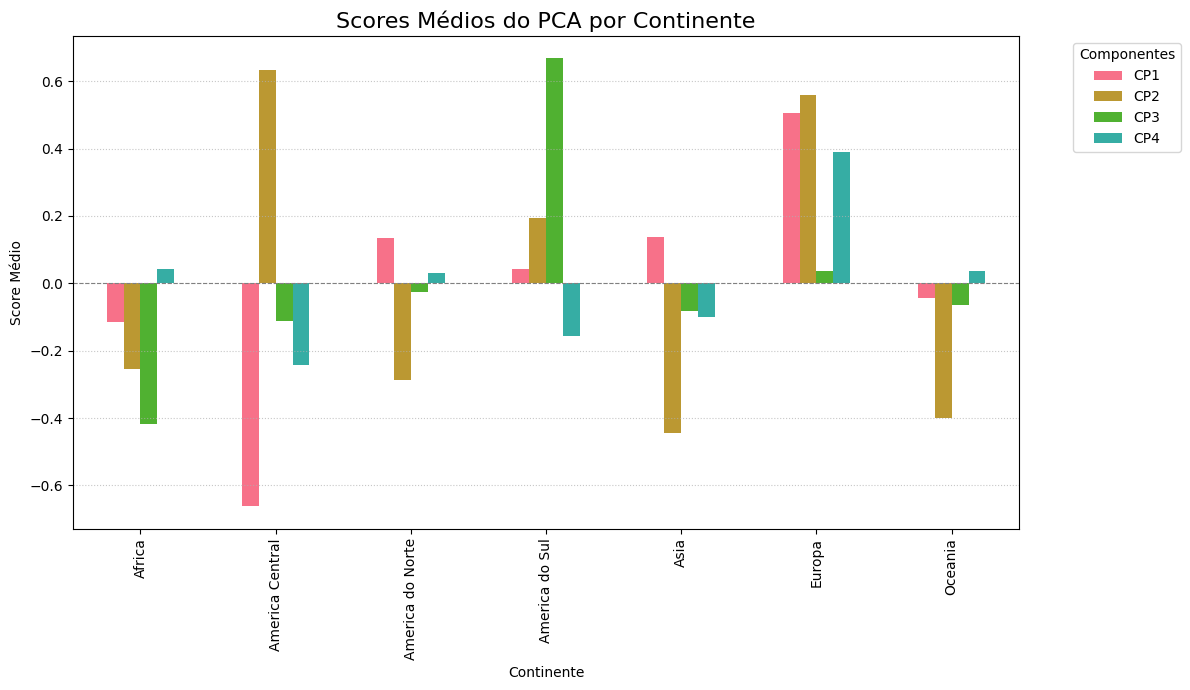


Tabela: Médias dos Scores do PCA por Continente:


,CP1,CP2,CP3,CP4
continente,,,,
Africa,-0.115,-0.256,-0.417,0.042
America Central,-0.662,0.633,-0.112,-0.242
America do Norte,0.133,-0.288,-0.027,0.031
America do Sul,0.043,0.194,0.668,-0.157
Asia,0.138,-0.444,-0.083,-0.100
Europa,0.506,0.559,0.036,0.388
Oceania,-0.043,-0.398,-0.065,0.037


In [ ]:
print("\n" + "=" * 60)
print("GRÁFICO DE SCORES MÉDIOS DO PCA POR CONTINENTE")
print("=" * 60)

# (Este código assume que 'df_paises_last' já contém as colunas CP1, CP2, etc.)

# 1. Agrupa os scores médios por continente
# (Isso irá gerar os dados para o seu gráfico)
scores_pca_continente = df_paises_last.groupby('continente')[
    [f'CP{i+1}' for i in range(n_fatores_kaiser)]
].mean()

# 2. Plota o gráfico de barras (ESTE É O GRÁFICO QUE FALTA NA SEÇÃO PCA)
scores_pca_continente.plot(
    kind='bar',
    figsize=(12, 7)
)

plt.title('Scores Médios do PCA por Continente', fontsize=16)
plt.ylabel('Score Médio')
plt.xlabel('Continente')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.legend(title='Componentes', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

print("\nTabela: Médias dos Scores do PCA por Continente:")
display(scores_pca_continente.round(3))

# Script T4


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Sucesso! DataFrame 'df_paises_last' carregado.


,titulo_musica,artistas,pais,continente,hemisferio,data_lancamento_album,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm,CP1,CP2,CP3,CP4
0,Isaka (6am),"CIZA, Jazzworx, Thukuthela",ZA,Africa,Sul,2025-04-11,349.910,0.341,0.540,-9.070,0.0566,0.29200,0.27900,0.2120,0.752,176.762,-2.136521,-1.727489,0.155284,1.595395
1,Uzizwa Kanjan (feat. GL_Ceejay),"Jazzworx, MaWhoo, Thukuthela, GL_Ceejay",ZA,Africa,Sul,2025-04-25,467.145,0.510,0.431,-11.190,0.0518,0.58200,0.37100,0.1100,0.560,118.055,-3.559074,-1.236537,-1.908591,-0.399821
2,Mali,"Dlala Thukzin, Zee Nxumalo, SYKES",ZA,Africa,Sul,2025-04-25,408.813,0.807,0.538,-7.799,0.0518,0.00606,0.00329,0.0526,0.291,118.050,-0.611081,-1.516130,-2.518044,-0.059811
3,"Abantwana Bakho (feat. Thatohatsi, Young Stunn...","DJ Maphorisa, Xduppy, Kabza De Small, Thatohat...",ZA,Africa,Sul,2025-03-28,518.307,0.740,0.747,-10.590,0.0496,0.02180,0.00370,0.1810,0.542,112.992,-0.346901,-2.502773,-2.613862,-0.918899
4,Vuka (feat. Thukuthela),"Oscar Mbo, Jazzworx, Thukuthela",ZA,Africa,Sul,2024-12-13,327.451,0.738,0.455,-10.965,0.0466,0.17500,0.19800,0.1050,0.524,118.006,-1.582859,-0.397247,-1.943969,0.075306


✅ Bibliotecas importadas e configuradas.
ANÁLISE FATORIAL - PREPARAÇÃO
Variáveis selecionadas: ['duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala', 'acustica', 'instrumentalidade', 'valencia']
✅ Dados padronizados com sucesso.

TESTES DE ADEQUAÇÃO (AF)
Teste de Bartlett: Chi² = 1530.79, p = 0.00000
KMO Overall = 0.6385

DETERMINAÇÃO DO NÚMERO DE FATORES (AF)


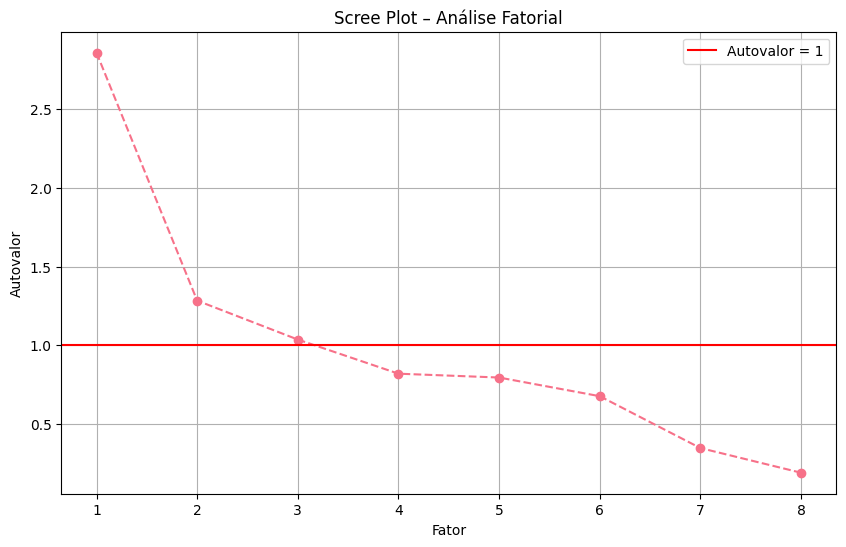


Número de fatores sugeridos (Kaiser): 3

RESULTADOS DA ANÁLISE FATORIAL


/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


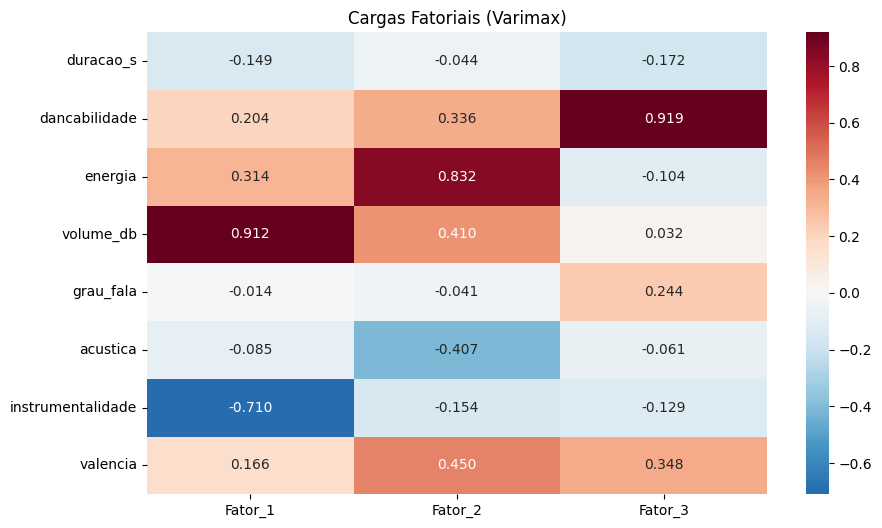

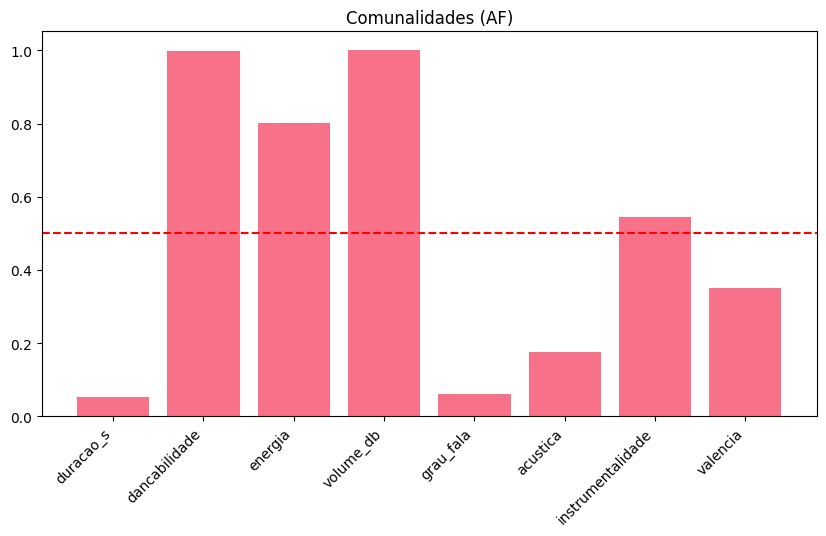


SCORES FATORIAIS POR CONTINENTE


/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


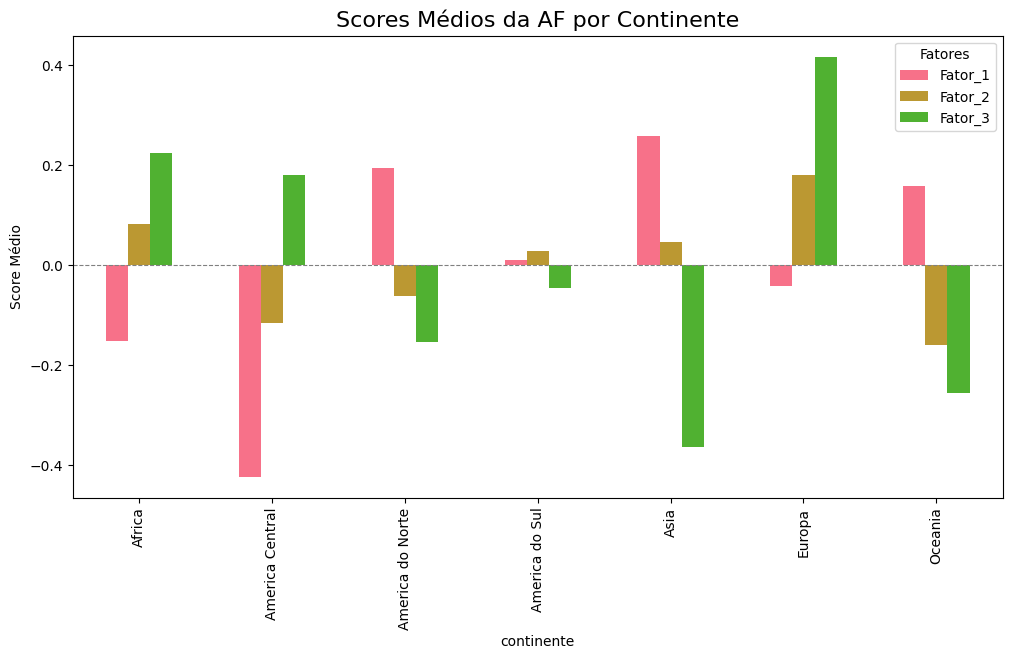


ANÁLISE PCA - PREPARAÇÃO (10 VARIÁVEIS)
Bartlett PCA: Chi² = 1640.32, p = 0.0000
KMO PCA: 0.6061

DECISÃO E EXECUÇÃO DO PCA


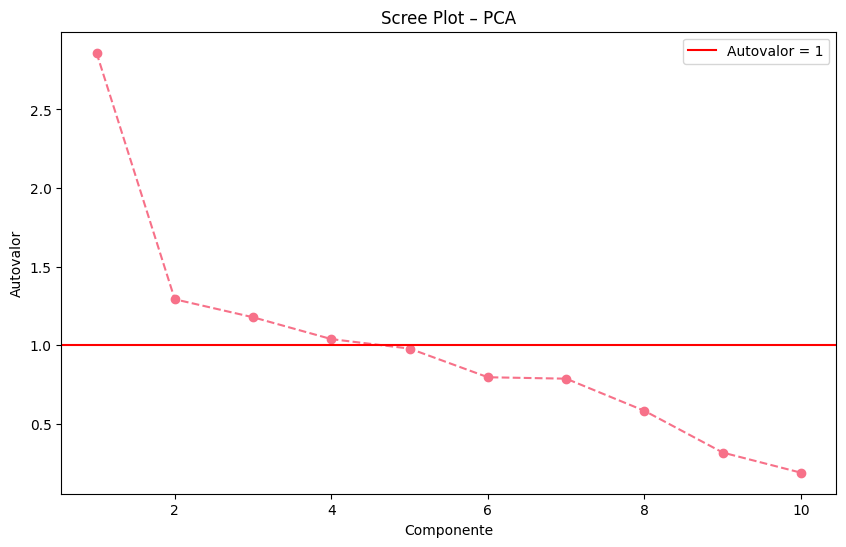

Número de componentes sugeridos (Kaiser): 4
Variância Explicada Acumulada: [0.28565189 0.41464253 0.53220282 0.63588018]

RESULTADOS FINAIS DO PCA


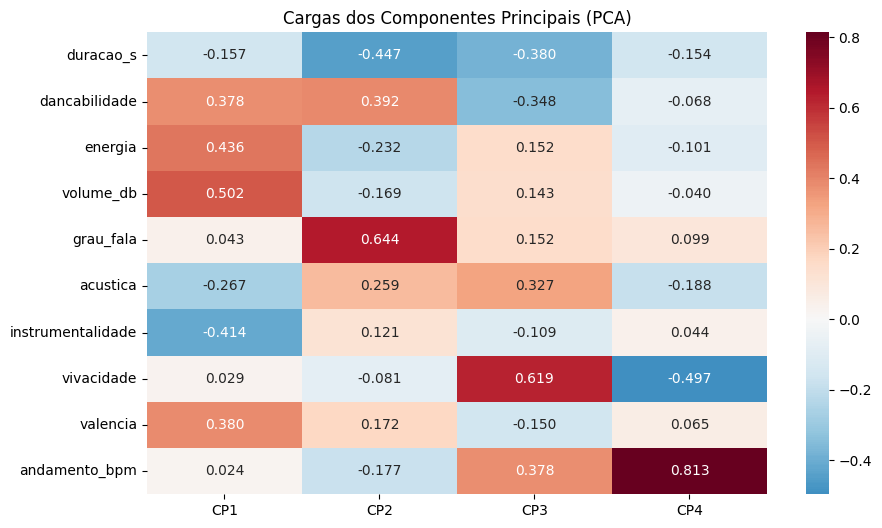

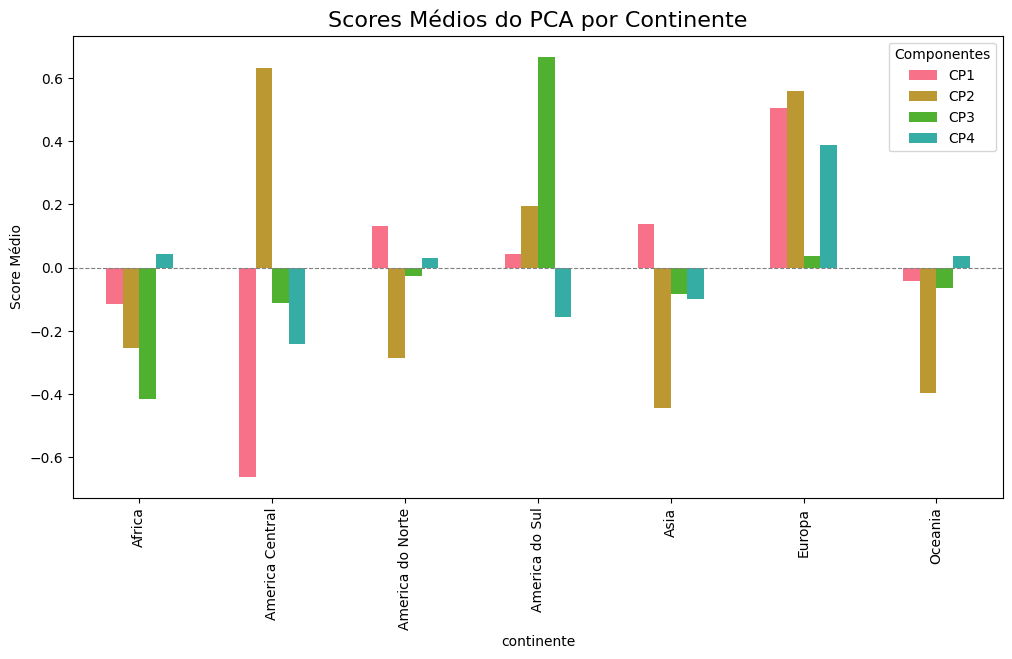

In [ ]:
# ==============================================================================
# ROTEIRO DE ANÁLISE DE DADOS: ANÁLISE FATORIAL (AF) E COMPONENTES PRINCIPAIS (PCA)
# ==============================================================================
#
# INSTRUÇÕES DE USO:
# 1. Certifique-se de que o arquivo 'df_paises_last.csv' (90 KB) esteja na sua pasta
#    'Colab_Notebooks' no Google Drive.
# 2. Execute as células abaixo EM ORDEM, uma por uma.
# ==============================================================================

# --- CÉLULA 1: CONEXÃO E CARREGAMENTO DOS DADOS ---
from google.colab import drive
import pandas as pd

# Conecta ao Google Drive
drive.mount('/content/drive')

# Carrega o DataFrame pré-processado (o arquivo de 90KB)
# Ajuste o caminho se o seu arquivo estiver em outra pasta
try:
    df_paises_last = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks/df_paises_last.csv')
    print("✅ Sucesso! DataFrame 'df_paises_last' carregado.")
    display(df_paises_last.head())
except FileNotFoundError:
    print("❌ ERRO: Arquivo não encontrado. Verifique se o arquivo 'df_paises_last.csv'")
    print("   está na pasta 'Colab_Notebooks' do seu Google Drive.")


# --- CÉLULA 2: INSTALAÇÃO DE PACOTES E IMPORTAÇÃO DE BIBLIOTECAS ---
!pip install factor-analyzer

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Configuração visual
plt.style.use('default')
sns.set_palette("husl")
print("✅ Bibliotecas importadas e configuradas.")


# ==============================================================================
# PARTE 1: ANÁLISE FATORIAL (AF) - A METODOLOGIA CORRETA (8 VARIÁVEIS)
# ==============================================================================

# --- CÉLULA 3: PREPARAÇÃO E PADRONIZAÇÃO PARA AF ---
print("=" * 70)
print("ANÁLISE FATORIAL - PREPARAÇÃO")
print("=" * 70)

# 1. Seleção das 8 variáveis (sem 'vivacidade' e 'andamento_bpm')
variaveis_af = [
    'duracao_s', 'dancabilidade', 'energia', 'volume_db',
    'grau_fala', 'acustica', 'instrumentalidade', 'valencia'
]

df_numerico_af = df_paises_last[variaveis_af].copy()

# 2. Padronização (Z-Score) - ESSENCIAL
scaler_af = StandardScaler()
df_scaled_af = pd.DataFrame(
    scaler_af.fit_transform(df_numerico_af),
    columns=variaveis_af,
    index=df_numerico_af.index
)

print("Variáveis selecionadas:", variaveis_af)
print("✅ Dados padronizados com sucesso.")


# --- CÉLULA 4: TESTES DE ADEQUAÇÃO (AF) ---
print("\n" + "=" * 60)
print("TESTES DE ADEQUAÇÃO (AF)")
print("=" * 60)

# Bartlett
chi, p_value = calculate_bartlett_sphericity(df_scaled_af)
print(f"Teste de Bartlett: Chi² = {chi:.2f}, p = {p_value:.5f}")

# KMO
kmo_all, kmo_model = calculate_kmo(df_scaled_af)
print(f"KMO Overall = {kmo_model:.4f}")


# --- CÉLULA 5: DECISÃO DO NÚMERO DE FATORES (AF) ---
print("\n" + "=" * 60)
print("DETERMINAÇÃO DO NÚMERO DE FATORES (AF)")
print("=" * 60)

# Usa PCA apenas para ver os autovalores
pca_af = PCA().fit(df_scaled_af)
autovalores_af = pca_af.explained_variance_

# Scree Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(autovalores_af) + 1), autovalores_af, 'o--')
plt.axhline(1, color='red', label='Autovalor = 1')
plt.title("Scree Plot – Análise Fatorial")
plt.xlabel("Fator")
plt.ylabel("Autovalor")
plt.grid(True)
plt.legend()
plt.show()

n_fatores_af = sum(autovalores_af > 1)
print(f"\nNúmero de fatores sugeridos (Kaiser): {n_fatores_af}")


# --- CÉLULA 6: EXECUÇÃO DA ANÁLISE FATORIAL E RESULTADOS ---
print("\n" + "=" * 60)
print("RESULTADOS DA ANÁLISE FATORIAL")
print("=" * 60)

# Roda a AF com rotação Varimax nos dados padronizados
fa = FactorAnalyzer(n_factors=n_fatores_af, rotation="varimax", method="minres")
fa.fit(df_scaled_af)

# Cargas Fatoriais
cargas_af = pd.DataFrame(
    fa.loadings_,
    index=variaveis_af,
    columns=[f"Fator_{i+1}" for i in range(n_fatores_af)]
)

# Comunalidades
comunalidades_af = pd.DataFrame({
    "Variável": variaveis_af,
    "Comunalidade": fa.get_communalities()
})

# Heatmap das Cargas
plt.figure(figsize=(10, 6))
sns.heatmap(cargas_af, annot=True, cmap="RdBu_r", fmt=".3f", center=0)
plt.title("Cargas Fatoriais (Varimax)")
plt.show()

# Gráfico de Comunalidades
plt.figure(figsize=(10, 5))
plt.bar(comunalidades_af["Variável"], comunalidades_af["Comunalidade"])
plt.axhline(0.5, color='red', linestyle='--')
plt.title("Comunalidades (AF)")
plt.xticks(rotation=45, ha="right")
plt.show()


# --- CÉLULA 7: SCORES FATORIAIS POR CONTINENTE (AF) ---
print("\n" + "=" * 60)
print("SCORES FATORIAIS POR CONTINENTE")
print("=" * 60)

# Calcula os scores
scores_af = fa.transform(df_scaled_af)

# Adiciona ao dataframe original para pegar os continentes
df_af_final = df_paises_last.copy()
for i in range(n_fatores_af):
    df_af_final.loc[df_scaled_af.index, f"Fator_{i+1}"] = scores_af[:, i]

# Agrupa e Plota
scores_af_continente = df_af_final.groupby('continente')[
    [f"Fator_{i+1}" for i in range(n_fatores_af)]
].mean()

scores_af_continente.plot(kind='bar', figsize=(12, 6))
plt.title('Scores Médios da AF por Continente', fontsize=16)
plt.ylabel('Score Médio')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.legend(title='Fatores')
plt.show()


# ==============================================================================
# PARTE 2: ANÁLISE DE COMPONENTES PRINCIPAIS (PCA) - (10 VARIÁVEIS)
# ==============================================================================

# --- CÉLULA 8: PREPARAÇÃO E TESTES DE ADEQUAÇÃO (PCA) ---
print("\n" + "=" * 70)
print("ANÁLISE PCA - PREPARAÇÃO (10 VARIÁVEIS)")
print("=" * 70)

# 1. Seleção das 10 variáveis (todas as numéricas)
variaveis_pca = [
    'duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala',
    'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm'
]

df_numerico_pca = df_paises_last[variaveis_pca].dropna()

# 2. Padronização (Z-Score)
scaler_pca = StandardScaler()
df_scaled_pca = pd.DataFrame(
    scaler_pca.fit_transform(df_numerico_pca),
    columns=variaveis_pca,
    index=df_numerico_pca.index
)

# 3. Testes de Adequação (Para Slide 15)
chi_pca, p_val_pca = calculate_bartlett_sphericity(df_scaled_pca)
kmo_all_pca, kmo_model_pca = calculate_kmo(df_scaled_pca)

print(f"Bartlett PCA: Chi² = {chi_pca:.2f}, p = {p_val_pca:.4f}")
print(f"KMO PCA: {kmo_model_pca:.4f}")


# --- CÉLULA 9: DECISÃO DE COMPONENTES E EXECUÇÃO (PCA) ---
print("\n" + "=" * 60)
print("DECISÃO E EXECUÇÃO DO PCA")
print("=" * 60)

# Roda PCA inicial
pca = PCA().fit(df_scaled_pca)
autovalores_pca = pca.explained_variance_
n_comp_kaiser = sum(autovalores_pca > 1)

# Scree Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(autovalores_pca) + 1), autovalores_pca, 'o--')
plt.axhline(1, color='red', label='Autovalor = 1')
plt.title("Scree Plot – PCA")
plt.xlabel("Componente")
plt.ylabel("Autovalor")
plt.legend()
plt.show()

print(f"Número de componentes sugeridos (Kaiser): {n_comp_kaiser}")

# Roda PCA Final com o número escolhido
pca_final = PCA(n_components=n_comp_kaiser)
scores_pca = pca_final.fit_transform(df_scaled_pca)

# Variância Explicada
var_exp = np.cumsum(pca_final.explained_variance_ratio_)
print("Variância Explicada Acumulada:", var_exp)


# --- CÉLULA 10: CARGAS E SCORES POR CONTINENTE (PCA) ---
print("\n" + "=" * 60)
print("RESULTADOS FINAIS DO PCA")
print("=" * 60)

# Cargas (Loadings)
cargas_pca = pd.DataFrame(
    pca_final.components_.T,
    columns=[f'CP{i+1}' for i in range(n_comp_kaiser)],
    index=variaveis_pca
)

plt.figure(figsize=(10, 6))
sns.heatmap(cargas_pca, annot=True, cmap="RdBu_r", fmt=".3f", center=0)
plt.title("Cargas dos Componentes Principais (PCA)")
plt.show()

# Scores por Continente
df_pca_final = df_paises_last.copy()
for i in range(n_comp_kaiser):
    df_pca_final.loc[df_scaled_pca.index, f"CP{i+1}"] = scores_pca[:, i]

scores_pca_continente = df_pca_final.groupby('continente')[
    [f"CP{i+1}" for i in range(n_comp_kaiser)]
].mean()

scores_pca_continente.plot(kind='bar', figsize=(12, 6))
plt.title('Scores Médios do PCA por Continente', fontsize=16)
plt.ylabel('Score Médio')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.legend(title='Componentes')
plt.show()

# Análise de Clusters

In [ ]:
# ===============================================================
# 1. PREPARAÇÃO: PADRONIZAÇÃO (Z-SCORE)
# ===============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Configuração visual
plt.style.use('default')
sns.set_palette("husl")

# 1. Seleção das variáveis (mesmas do PCA para consistência)
variaveis_cluster = [
    'duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala',
    'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm'
]

# 2. Cria dataframe numérico e remove nulos
df_numerico = df_paises_last[variaveis_cluster].dropna()

# 3. Padronização (Z-Score) - Slide 25 (Cluster I)
# "A forma mais utilizada é a padronização Z-score, com média zero e desvio padrão 1"
scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_numerico),
    columns=variaveis_cluster,
    index=df_numerico.index
)

print("✅ Dados padronizados com sucesso (Média=0, Desvio=1).")
display(df_scaled.describe().round(2))

✅ Dados padronizados com sucesso (Média=0, Desvio=1).


,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm
count,700.00,700.00,700.00,700.00,700.00,700.00,700.00,700.00,700.00,700.00
mean,0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.21,-3.23,-4.00,-7.75,-0.77,-1.17,-0.20,-0.97,-2.40,-2.74
25%,-0.62,-0.60,-0.53,-0.17,-0.62,-0.85,-0.20,-0.57,-0.69,-0.70
50%,-0.21,0.09,0.09,0.20,-0.41,-0.30,-0.20,-0.38,-0.03,-0.13
75%,0.40,0.69,0.70,0.48,0.23,0.76,-0.20,0.20,0.86,0.52
max,5.95,2.00,1.96,1.33,5.72,2.65,8.22,5.12,1.91,3.11


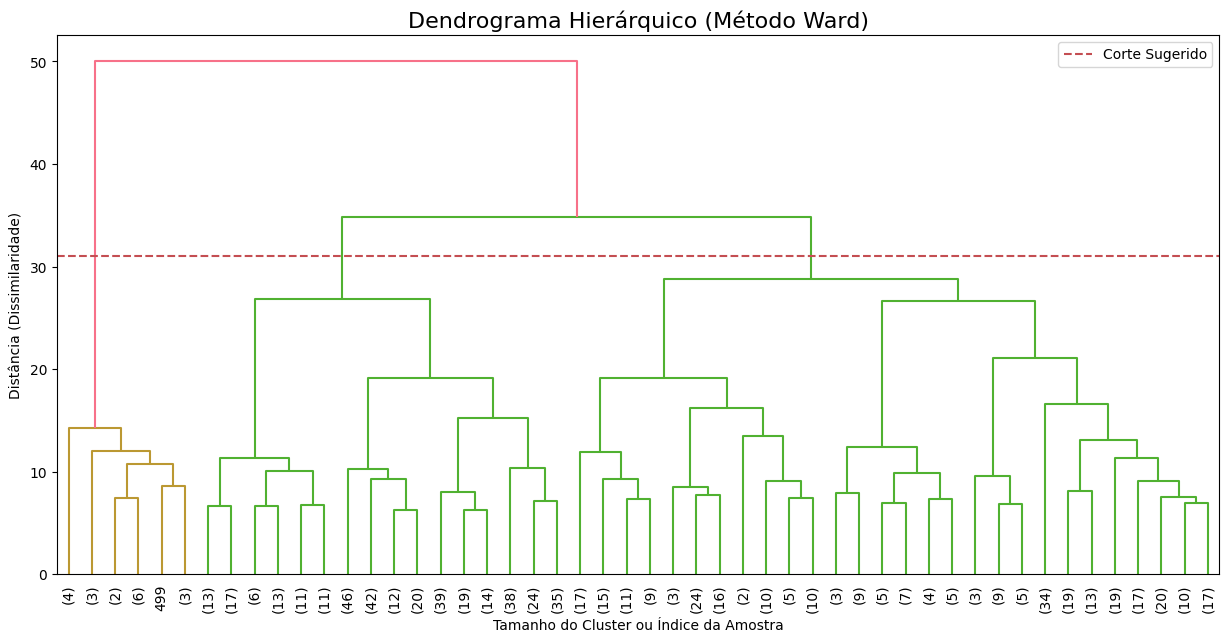

Interpretação: Linhas verticais mais longas indicam maior separação entre os grupos.


In [ ]:
# ===============================================================
# 2. CLUSTER HIERÁRQUICO (DENDROGRAMA)
# ===============================================================
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Calcular a Matriz de Ligação (Linkage)
# Usamos o método 'ward' (Slide 56, Cluster I) que minimiza a soma dos quadrados intra-grupo
linked = linkage(df_scaled, method='ward')

# 2. Plotar o Dendrograma (Slide 22, Cluster II)
plt.figure(figsize=(15, 7))
dendrogram(
    linked,
    truncate_mode='lastp',  # Mostra apenas os últimos p clusters para não poluir
    p=50,                   # Mostra os 50 últimos ramos
    show_leaf_counts=True,
    leaf_font_size=10,
    leaf_rotation=90,
)

plt.title('Dendrograma Hierárquico (Método Ward)', fontsize=16)
plt.xlabel('Tamanho do Cluster ou Índice da Amostra')
plt.ylabel('Distância (Dissimilaridade)')

# Linha de corte sugerida (Visual - Ajuste conforme necessário)
plt.axhline(y=31, color='r', linestyle='--', label='Corte Sugerido')
plt.legend()
plt.show()

print("Interpretação: Linhas verticais mais longas indicam maior separação entre os grupos.")

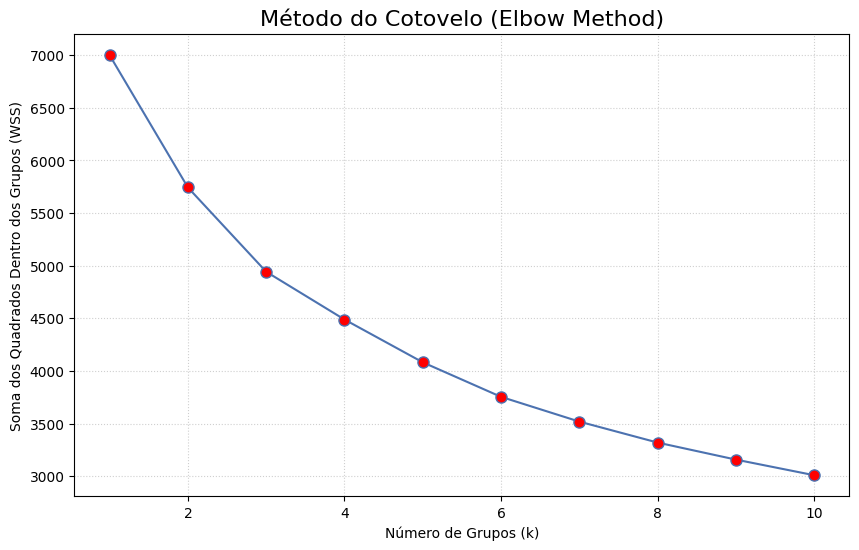

Observe onde a curva 'dobra' (o cotovelo). Esse é o k ideal.


In [ ]:
# ===============================================================
# 3. K-MEANS: MÉTODO DO COTOVELO (DECISÃO DE k)
# ===============================================================
from sklearn.cluster import KMeans

# 1. Calcular a Inércia (WSS) para k=1 a 10
wss = [] # Within-Cluster Sum of Squares
range_k = range(1, 11)

for k in range_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    wss.append(kmeans.inertia_)

# 2. Plotar o gráfico do Cotovelo (Slide 48, Cluster II)
plt.figure(figsize=(10, 6))
plt.plot(range_k, wss, 'bo-', markerfacecolor='red', markersize=8)
plt.title('Método do Cotovelo (Elbow Method)', fontsize=16)
plt.xlabel('Número de Grupos (k)')
plt.ylabel('Soma dos Quadrados Dentro dos Grupos (WSS)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print("Observe onde a curva 'dobra' (o cotovelo). Esse é o k ideal.")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


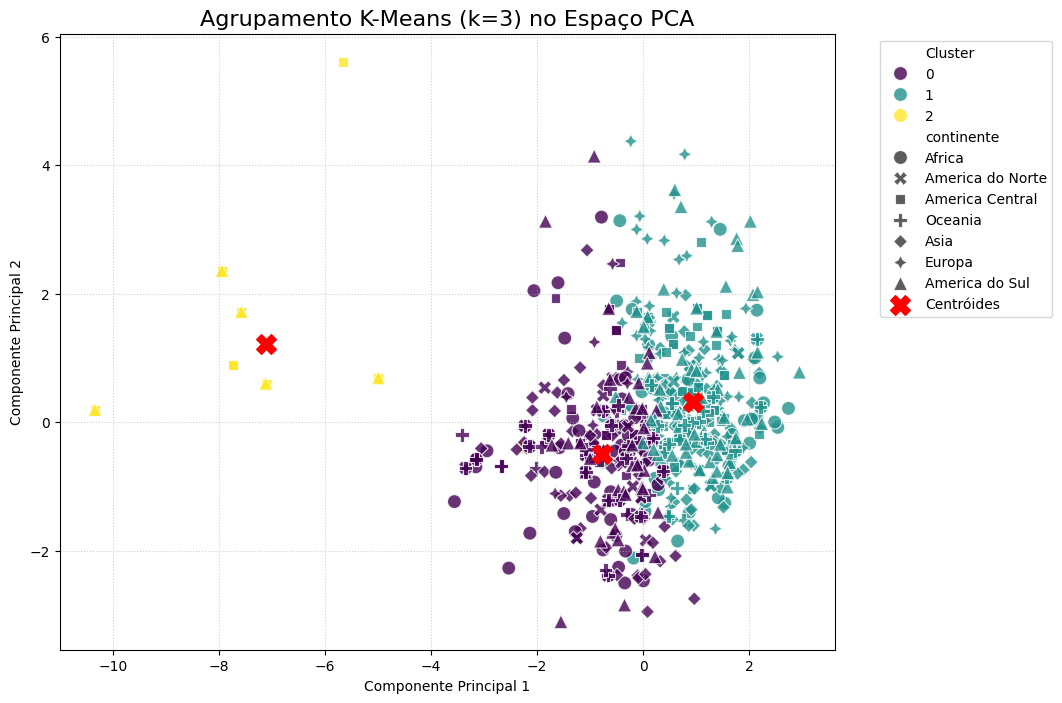


Perfil Médio dos Clusters (Variáveis Originais):


,duracao_s,dancabilidade,energia,volume_db,grau_fala,acustica,instrumentalidade,vivacidade,valencia,andamento_bpm
Cluster,,,,,,,,,,
0,232.58,0.55,0.60,-7.19,0.07,0.38,0.01,0.16,0.40,126.34
1,192.18,0.74,0.72,-5.54,0.11,0.20,0.00,0.20,0.67,118.18
2,228.76,0.34,0.29,-30.92,0.11,0.51,0.63,0.18,0.19,113.85


In [ ]:
# ===============================================================
# 4. EXECUÇÃO DO K-MEANS E VISUALIZAÇÃO NO PCA
# ===============================================================
from sklearn.decomposition import PCA

# --- DEFINA O NÚMERO DE CLUSTERS AQUI (Baseado no Cotovelo) ---
k_escolhido = 3
# --------------------------------------------------------------

# 1. Roda o K-Means Final
kmeans_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
labels = kmeans_final.fit_predict(df_scaled)

# 2. Adiciona os clusters ao dataframe original
df_paises_last['Cluster'] = labels

# 3. Visualização no Espaço PCA (Slide 34, Cluster II)
# Precisamos do PCA apenas para visualizar os grupos em 2D
pca_viz = PCA(n_components=2)
coords_pca = pca_viz.fit_transform(df_scaled)

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=coords_pca[:, 0],
    y=coords_pca[:, 1],
    hue=df_paises_last['Cluster'],
    palette='viridis',
    style=df_paises_last['continente'], # Diferencia continentes por símbolo
    s=100,
    alpha=0.8
)

# Plotar os Centróides
centroides_pca = pca_viz.transform(kmeans_final.cluster_centers_)
plt.scatter(centroides_pca[:, 0], centroides_pca[:, 1],
            c='red', s=200, marker='X', label='Centróides')

plt.title(f'Agrupamento K-Means (k={k_escolhido}) no Espaço PCA', fontsize=16)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 4. Perfil dos Clusters (Médias das variáveis originais por grupo)
print("\nPerfil Médio dos Clusters (Variáveis Originais):")
perfil_clusters = df_paises_last.groupby('Cluster')[variaveis_cluster].mean()
display(perfil_clusters.round(2))

In [ ]:
# ===============================================================
# 5. GERAÇÃO DA TABELA RESUMO (CONCLUSÕES)
# ===============================================================
import pandas as pd

# 1. Definir os rótulos interpretativos (Baseado na análise prévia)
# Ajuste esses textos conforme sua interpretação final
perfis_sugeridos = {
    0: "Melódicas & Intensas (Lentas/Complexas)",
    1: "Hits Dançantes & Pop (Mainstream)",
    2: "Instrumental / Ambiente (Outliers)"
}

# 2. Selecionar apenas as variáveis de interesse para o resumo
cols_resumo = ['duracao_s', 'dancabilidade', 'energia', 'valencia', 'instrumentalidade', 'volume_db']

# 3. Calcular as médias
df_resumo = df_paises_last.groupby('Cluster')[cols_resumo].mean().T

# 4. Calcular o tamanho de cada cluster (n)
counts = df_paises_last['Cluster'].value_counts().sort_index()

# 5. Renomear as colunas para incluir o tamanho do grupo (Ex: "Cluster 0 (n=291)")
novas_colunas = {}
for cluster_id in df_resumo.columns:
    n = counts[cluster_id]
    novas_colunas[cluster_id] = f"Cluster {cluster_id} (n={n})"

df_resumo.rename(columns=novas_colunas, inplace=True)

# 6. Adicionar a linha de "Perfil Sugerido" no topo
# Criamos um DataFrame temporário apenas para a linha de perfil
row_perfil = pd.DataFrame(
    [perfis_sugeridos[i] for i in sorted(perfis_sugeridos.keys())],
    index=df_resumo.columns,
    columns=['Perfil Sugerido']
).T

# Concatenar: Perfil primeiro, depois os dados numéricos
tabela_final = pd.concat([row_perfil, df_resumo])

# 7. Formatação visual (Arredondamento)
# Nota: Como misturamos texto (Perfil) com números, o dataframe é do tipo 'object'.
# Vamos arredondar apenas o que for numérico visualmente convertendo.
print("=== TABELA DE ANÁLISE DE CLUSTERS ===")
display(tabela_final)

# Opcional: Exportar para CSV se quiser usar no Excel/Relatório
# tabela_final.to_csv('tabela_conclusoes_clusters.csv')

=== TABELA DE ANÁLISE DE CLUSTERS ===


Cluster,Cluster 0 (n=291),Cluster 1 (n=389),Cluster 2 (n=20)
Perfil Sugerido,Melódicas & Intensas (Lentas/Complexas),Hits Dançantes & Pop (Mainstream),Instrumental / Ambiente (Outliers)
duracao_s,232.584814,192.180866,228.75505
dancabilidade,0.552192,0.736249,0.34355
energia,0.599674,0.723141,0.286598
valencia,0.398578,0.672283,0.186352
instrumentalidade,0.008336,0.004624,0.6262
volume_db,-7.186639,-5.544499,-30.9173


# Escalonamento Multi Dimensional (MDS)

Processando MDS para o dataset completo: 700 músicas.


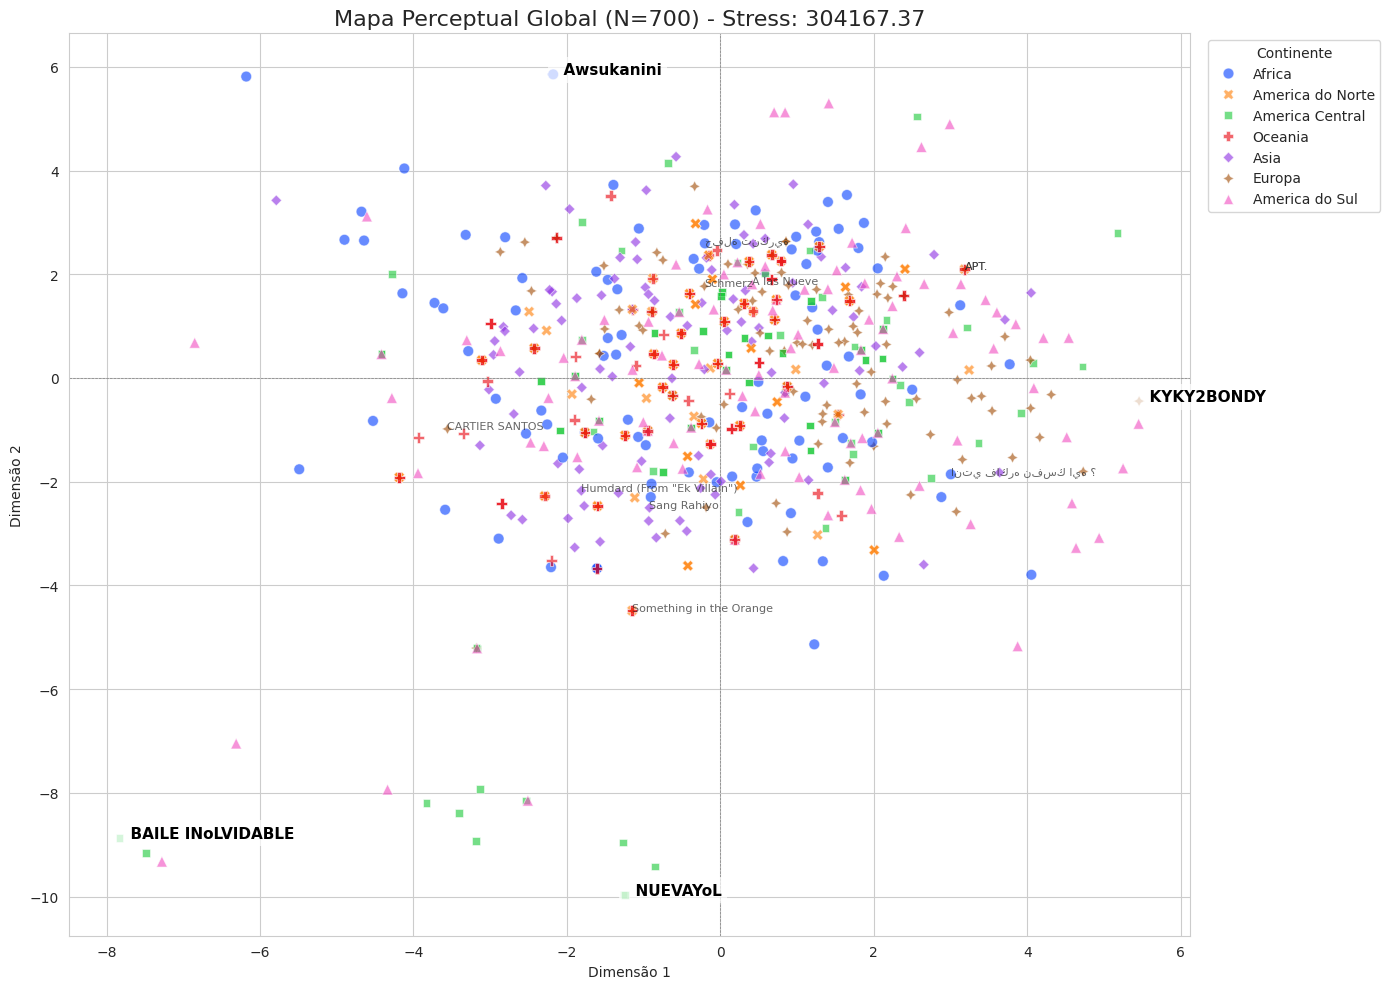

In [ ]:
# ==============================================================================
# Escalonamento Multi Dimensional - MDS
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import MDS
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import euclidean_distances

# Configuração
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = [14, 10]

# 1. PREPARAÇÃO
cols_numericas = [
    'duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala',
    'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm'
]

# Remove nulos e reseta index
df_full = df_paises_last.dropna(subset=cols_numericas).reset_index(drop=True)

# Cria rótulo único (caso precisemos identificar algum ponto específico)
df_full['rotulo'] = df_full['titulo_musica'] + " (" + df_full['artistas'].str.slice(0,10) + ")"

print(f"Processando MDS para o dataset completo: {len(df_full)} músicas.")

# 2. PADRONIZAÇÃO E MATRIZ
X = df_full[cols_numericas].values
X_scaled = StandardScaler().fit_transform(X)
dist_matrix = euclidean_distances(X_scaled, X_scaled)

# 3. MDS
mds = MDS(n_components=2, metric=True, dissimilarity='precomputed', random_state=42, n_jobs=-1)
coords = mds.fit_transform(dist_matrix)

# 4. PREPARANDO O PLOT
df_plot = df_full.copy()
df_plot['X_MDS'] = coords[:, 0]
df_plot['Y_MDS'] = coords[:, 1]

# 5. VISUALIZAÇÃO INTELIGENTE
plt.figure(figsize=(14, 10))

# A) Plotamos todos os pontos, mas sem texto
sns.scatterplot(
    data=df_plot,
    x='X_MDS', y='Y_MDS',
    hue='continente',    # Cor por continente ajuda a ver padrões regionais
    style='continente',
    palette='bright',
    alpha=0.6,           # Transparência ajuda a ver onde tem muita música aglomerada
    s=60
)

# B) Identificamos e rotulamos apenas os EXTREMOS (Outliers)
# Isso ajuda a entender o significado dos eixos sem poluir o gráfico
# Extremos: Maior/Menor X e Maior/Menor Y
extremos = df_plot.iloc[[
    df_plot['X_MDS'].idxmax(), df_plot['X_MDS'].idxmin(),
    df_plot['Y_MDS'].idxmax(), df_plot['Y_MDS'].idxmin()
]]

for idx, row in extremos.iterrows():
    plt.text(
        row['X_MDS'], row['Y_MDS'],
        f"  {row['titulo_musica']}",
        fontsize=11, fontweight='bold', color='black',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )

# C) (Opcional) Rotular algumas aleatórias para contexto
amostra_rotulos = df_plot.sample(10, random_state=1)
for idx, row in amostra_rotulos.iterrows():
    plt.text(
        row['X_MDS'], row['Y_MDS'],
        row['titulo_musica'], fontsize=8, alpha=0.7
    )

plt.title(f'Mapa Perceptual Global (N={len(df_full)}) - Stress: {mds.stress_:.2f}', fontsize=16)
plt.xlabel('Dimensão 1')
plt.ylabel('Dimensão 2')
plt.axhline(0, color='gray', ls='--', lw=0.5)
plt.axvline(0, color='gray', ls='--', lw=0.5)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title="Continente")
plt.tight_layout()
plt.show()

Processando MDS para o dataset completo: 700 músicas.


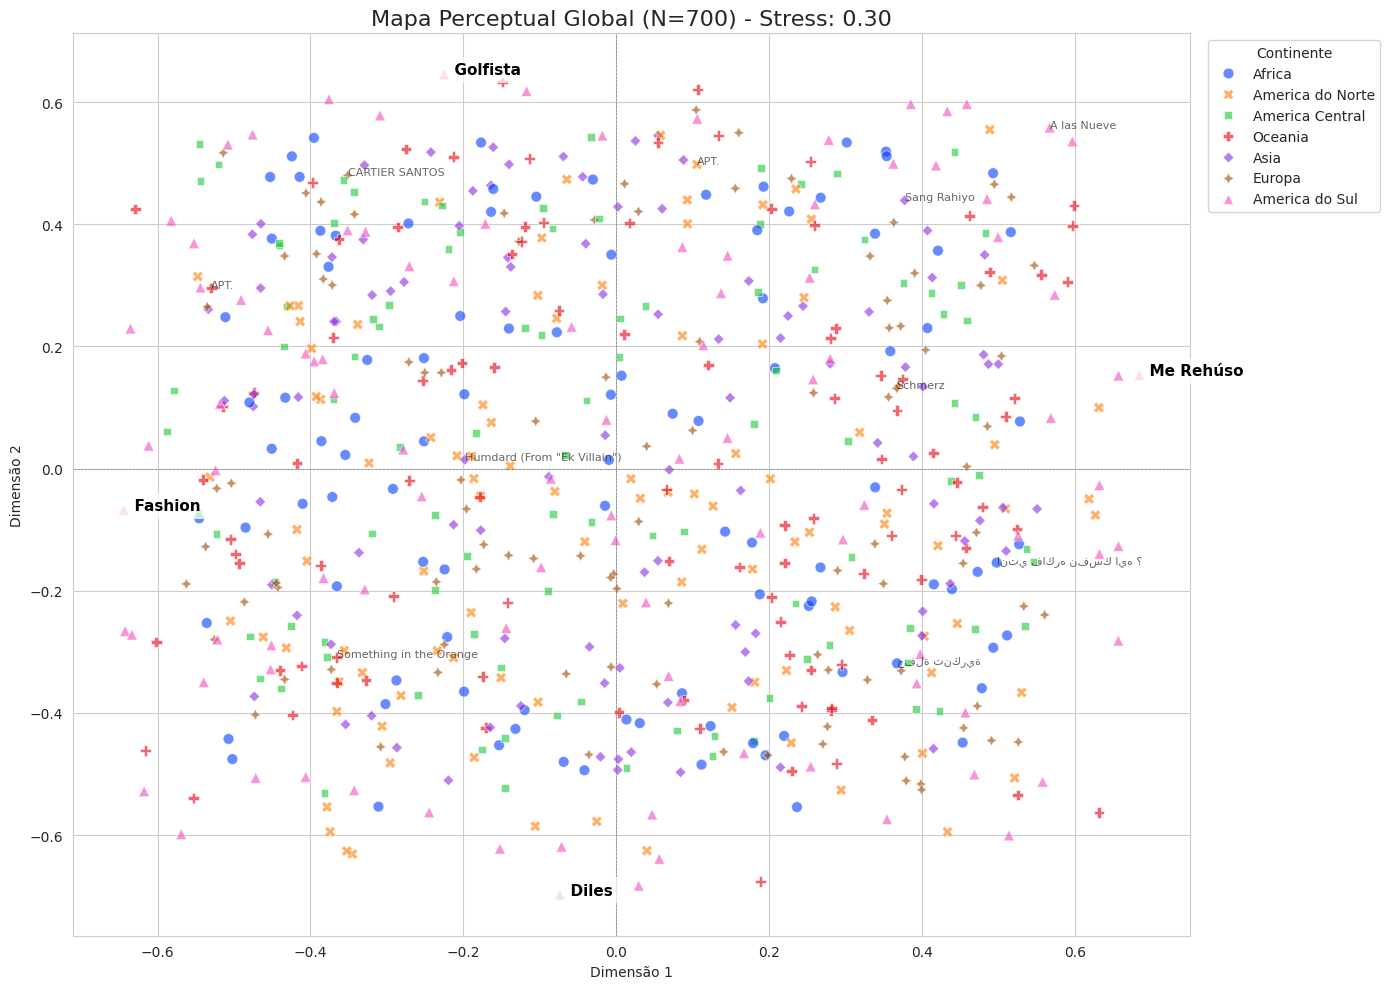

In [ ]:
# ==============================================================================
# Escalonamento Multi Dimensional - MDS (VERSÃO OTIMIZADA)
# USANDO: MDS NÃO-MÉTRICO + DISTÂNCIA COSSENO
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import MDS
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances   # <-- ALTERAÇÃO AQUI

# Configuração
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = [14, 10]

# 1. PREPARAÇÃO
cols_numericas = [
    'duracao_s', 'dancabilidade', 'energia', 'volume_db', 'grau_fala',
    'acustica', 'instrumentalidade', 'vivacidade', 'valencia', 'andamento_bpm'
]

df_full = df_paises_last.dropna(subset=cols_numericas).reset_index(drop=True)

df_full['rotulo'] = df_full['titulo_musica'] + " (" + df_full['artistas'].str.slice(0,10) + ")"

print(f"Processando MDS para o dataset completo: {len(df_full)} músicas.")

# 2. PADRONIZAÇÃO E MATRIZ
X = df_full[cols_numericas].values
X_scaled = StandardScaler().fit_transform(X)

# *** ALTERAÇÃO AQUI: DISTÂNCIA COSSENO ***
dist_matrix = cosine_distances(X_scaled)

# 3. MDS
# *** ALTERAÇÃO AQUI: metric=False ***
mds = MDS(
    n_components=2,
    metric=False,                      # <-- NÃO-MÉTRICO
    dissimilarity='precomputed',
    random_state=42,
    n_jobs=-1
)

coords = mds.fit_transform(dist_matrix)

# 4. PREPARANDO O PLOT
df_plot = df_full.copy()
df_plot['X_MDS'] = coords[:, 0]
df_plot['Y_MDS'] = coords[:, 1]

# 5. VISUALIZAÇÃO
plt.figure(figsize=(14, 10))

sns.scatterplot(
    data=df_plot,
    x='X_MDS', y='Y_MDS',
    hue='continente',
    style='continente',
    palette='bright',
    alpha=0.6,
    s=60
)

extremos = df_plot.iloc[[
    df_plot['X_MDS'].idxmax(), df_plot['X_MDS'].idxmin(),
    df_plot['Y_MDS'].idxmax(), df_plot['Y_MDS'].idxmin()
]]

for idx, row in extremos.iterrows():
    plt.text(
        row['X_MDS'], row['Y_MDS'],
        f"  {row['titulo_musica']}",
        fontsize=11, fontweight='bold', color='black',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )

amostra_rotulos = df_plot.sample(10, random_state=1)
for idx, row in amostra_rotulos.iterrows():
    plt.text(row['X_MDS'], row['Y_MDS'], row['titulo_musica'], fontsize=8, alpha=0.7)

plt.title(f'Mapa Perceptual Global (N={len(df_full)}) - Stress: {mds.stress_:.2f}', fontsize=16)
plt.xlabel('Dimensão 1')
plt.ylabel('Dimensão 2')
plt.axhline(0, color='gray', ls='--', lw=0.5)
plt.axvline(0, color='gray', ls='--', lw=0.5)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title="Continente")
plt.tight_layout()
plt.show()


In [ ]:
# ===============================================================
# INTERPRETAÇÃO DOS EIXOS (Correlacionando MDS com Variáveis)
# ===============================================================

# 1. Cria um DataFrame com as Coordenadas MDS e as Variáveis Originais
df_analise = pd.DataFrame(X_scaled, columns=variaveis_mds) # Variáveis padronizadas
df_analise['MDS_Dim1'] = coords[:, 0]
df_analise['MDS_Dim2'] = coords[:, 1]

# 2. Calcula a correlação de Pearson
correlacoes = df_analise.corr()[['MDS_Dim1', 'MDS_Dim2']]

# 3. Exibe as variáveis que mais explicam cada eixo
print("--- O que significa a Dimensão 1? (Maiores correlações) ---")
print(correlacoes['MDS_Dim1'].abs().sort_values(ascending=False).head(4))
print("\n--- O que significa a Dimensão 2? (Maiores correlações) ---")
print(correlacoes['MDS_Dim2'].abs().sort_values(ascending=False).head(4))

# 4. Plotagem do Heatmap de Correlações para facilitar a leitura
plt.figure(figsize=(6, 8))
sns.heatmap(correlacoes.drop(['MDS_Dim1', 'MDS_Dim2'], axis=0),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlação: Variáveis Originais vs. Dimensões MDS")
plt.show()

NameError: name 'variaveis_mds' is not defined

# Transformando os Dataframes em CSV's

In [ ]:
# Exportar df_paises_last para CSV
df_paises_last.to_csv("/content/drive/MyDrive/Colab_Notebooks/df_paises_last.csv", index=False, encoding="utf-8")

# Exportar df_paises_last para CSV
df_last.to_csv("/content/drive/MyDrive/Colab_Notebooks/df_last.csv", index=False, encoding="utf-8")
